In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 1
# Load and VERIFY the frozen experiment handoff
# ============================================================
#
# This notebook does NOT:
#
#   - download WM-811K
#   - recreate labels
#   - remove samples
#   - recreate groups
#   - regenerate train/test splits
#
# Those decisions were permanently frozen in Notebook 1.
#
#
# This cell:
#
#   1. mounts Google Drive;
#   2. loads the handoff manifest;
#   3. verifies the expected handoff fingerprint;
#   4. verifies the maps archive;
#   5. verifies the metadata;
#   6. loads all 25,513 native maps;
#   7. reconstructs a convenient map accessor;
#   8. checks train/validation/test roles.
#
# If ANY hash differs, we STOP.
# ============================================================


from google.colab import drive

from pathlib import Path

import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive"
)


# ------------------------------------------------------------
# 2. Frozen project paths
# ------------------------------------------------------------

PROJECT_DRIVE_DIR = Path(
    "/content/drive/MyDrive/"
    "WM811K_Spatial_Information_Audit"
)


FROZEN_DATA_DIR = (
    PROJECT_DRIVE_DIR /
    "frozen_data"
)


EXPERIMENT_DIR = (
    PROJECT_DRIVE_DIR /
    "experiments"
)


EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. EXPECTED fingerprints from Notebook 1
#
# These are deliberately hard-coded.
#
# Notebook 2 should verify Notebook 1's outputs, not silently
# trust whatever files happen to be present in Drive.
# ------------------------------------------------------------

EXPECTED_SOURCE_DATASET_SHA256 = (
    "1d04fccb3dd3176b276878b926b20fead"
    "7e077c5751e4d353ea9741a5e7b5c65"
)


EXPECTED_OUTER_SPLIT_SHA256 = (
    "c9d3edae11a34473753539361b49456a"
    "2a6ec036f3e08dc8a50d21fa475e3f6e"
)


EXPECTED_FULL_SPLIT_SHA256 = (
    "a1640bc7d8e46d1cdde0e9209d979916"
    "cb90c5a414d29c3fe94605f69284bb20"
)


EXPECTED_MAP_CONTENT_SHA256 = (
    "43e8891eadc45567466009c3b96032e5"
    "27770b31a1c2fac5de29fb9ec7522489"
)


EXPECTED_METADATA_SHA256 = (
    "e7ab1ee2c313336d20da855c98753dc4"
    "83ef596cb72fb91961c592b6bc1c9195"
)


EXPECTED_MAPS_FILE_SHA256 = (
    "d6cd44b50a0ff3b05a3cd84427bec822"
    "557a271597ca6c45fb70f72181db89dd"
)


EXPECTED_HANDOFF_SHA256 = (
    "2f80df17eba3e293636c64a9cc2b7073"
    "40b460bf203d3a676ff683bca648b0c5"
)


# ------------------------------------------------------------
# 4. File paths
# ------------------------------------------------------------

MAPS_PATH = (
    FROZEN_DATA_DIR /
    "FROZEN_primary_clean_native_maps.npz"
)


METADATA_PATH = (
    FROZEN_DATA_DIR /
    "FROZEN_primary_clean_metadata.tsv"
)


HANDOFF_PATH = (
    FROZEN_DATA_DIR /
    "FROZEN_experiment_handoff.json"
)


required_files = [
    MAPS_PATH,
    METADATA_PATH,
    HANDOFF_PATH
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing frozen handoff file:\n{path}"
        )


print("=" * 78)
print("WM-811K SPATIAL INFORMATION EXPERIMENTS")
print("=" * 78)

print(
    "Frozen-data directory:"
)

print(
    FROZEN_DATA_DIR
)

print()


# ------------------------------------------------------------
# 5. General SHA-256 function
# ------------------------------------------------------------

def file_sha256(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            sha.update(
                chunk
            )

    return sha.hexdigest()


# ------------------------------------------------------------
# 6. Load frozen handoff manifest
# ------------------------------------------------------------

with open(
    HANDOFF_PATH,
    "r"
) as f:

    handoff_manifest = json.load(
        f
    )


print("=" * 78)
print("HANDOFF MANIFEST")
print("=" * 78)

print(
    "Wafers:",
    f"{handoff_manifest['n_wafers']:,}"
)

print(
    "Classes:",
    handoff_manifest["classes"]
)

print(
    "Handoff content SHA-256:"
)

print(
    handoff_manifest[
        "handoff_content_sha256"
    ]
)

print()


# ------------------------------------------------------------
# 7. Verify ALL scientific fingerprints
# ------------------------------------------------------------

assert (
    handoff_manifest[
        "source_dataset_sha256"
    ]
    ==
    EXPECTED_SOURCE_DATASET_SHA256
)


assert (
    handoff_manifest[
        "outer_split_manifest_sha256"
    ]
    ==
    EXPECTED_OUTER_SPLIT_SHA256
)


assert (
    handoff_manifest[
        "full_train_val_test_manifest_sha256"
    ]
    ==
    EXPECTED_FULL_SPLIT_SHA256
)


assert (
    handoff_manifest[
        "native_map_content_sha256"
    ]
    ==
    EXPECTED_MAP_CONTENT_SHA256
)


assert (
    handoff_manifest[
        "metadata_sha256"
    ]
    ==
    EXPECTED_METADATA_SHA256
)


assert (
    handoff_manifest[
        "maps_archive_file_sha256"
    ]
    ==
    EXPECTED_MAPS_FILE_SHA256
)


assert (
    handoff_manifest[
        "handoff_content_sha256"
    ]
    ==
    EXPECTED_HANDOFF_SHA256
)


print(
    "PASS: all manifest fingerprints match Notebook 1."
)

print()


# ------------------------------------------------------------
# 8. Independently verify the maps archive FILE hash
# ------------------------------------------------------------

actual_maps_file_hash = file_sha256(
    MAPS_PATH
)


print(
    "Maps archive SHA-256:"
)

print(
    actual_maps_file_hash
)


assert (
    actual_maps_file_hash
    ==
    EXPECTED_MAPS_FILE_SHA256
)


print(
    "PASS: maps archive file verified."
)

print()


# ------------------------------------------------------------
# 9. Independently verify metadata TSV hash
# ------------------------------------------------------------

actual_metadata_hash = file_sha256(
    METADATA_PATH
)


print(
    "Metadata SHA-256:"
)

print(
    actual_metadata_hash
)


assert (
    actual_metadata_hash
    ==
    EXPECTED_METADATA_SHA256
)


print(
    "PASS: metadata file verified."
)

print()


# ------------------------------------------------------------
# 10. Load metadata
# ------------------------------------------------------------

metadata = pd.read_csv(
    METADATA_PATH,
    sep="\t"
)


assert len(
    metadata
) == 25_513


assert metadata[
    "orig_index"
].is_unique


assert metadata[
    "orig_index"
].is_monotonic_increasing


print("=" * 78)
print("METADATA LOADED")
print("=" * 78)

print(
    "Rows:",
    f"{len(metadata):,}"
)

print(
    "Columns:",
    len(
        metadata.columns
    )
)

print()


display(
    metadata.head()
)


# ------------------------------------------------------------
# 11. Load packed native maps
#
# Everything is numeric.
#
# allow_pickle=False is intentional.
# ------------------------------------------------------------

packed_maps = np.load(
    MAPS_PATH,
    allow_pickle=False
)


flat_maps = packed_maps[
    "flat_maps"
]


offsets = packed_maps[
    "offsets"
]


heights = packed_maps[
    "heights"
]


widths = packed_maps[
    "widths"
]


map_orig_indices = packed_maps[
    "orig_index"
]


# ------------------------------------------------------------
# 12. Structural checks
# ------------------------------------------------------------

assert len(
    heights
) == len(
    metadata
)


assert len(
    widths
) == len(
    metadata
)


assert len(
    map_orig_indices
) == len(
    metadata
)


assert len(
    offsets
) == (
    len(
        metadata
    )
    + 1
)


assert np.array_equal(
    map_orig_indices,
    metadata[
        "orig_index"
    ].to_numpy()
)


assert np.array_equal(
    heights,
    metadata[
        "height"
    ].to_numpy()
)


assert np.array_equal(
    widths,
    metadata[
        "width"
    ].to_numpy()
)


print("=" * 78)
print("NATIVE MAP ARCHIVE LOADED")
print("=" * 78)

print(
    "Wafers:",
    f"{len(heights):,}"
)

print(
    "Packed cells:",
    f"{len(flat_maps):,}"
)

print(
    "Packed uint8 payload:",
    f"{flat_maps.nbytes / 1024**2:.2f} MiB"
)

print()


# ------------------------------------------------------------
# 13. Native wafer accessor
#
# get_native_wafer(i)
#
# returns wafer number i in the canonical metadata ordering.
#
# This is a VIEW into flat_maps whenever possible, so we avoid
# storing another 25,513 arrays in memory.
# ------------------------------------------------------------

def get_native_wafer(
    position,
    copy=False
):

    position = int(
        position
    )


    if (
        position < 0
        or
        position >= len(
            metadata
        )
    ):

        raise IndexError(
            position
        )


    start = int(
        offsets[
            position
        ]
    )


    end = int(
        offsets[
            position + 1
        ]
    )


    wafer = (
        flat_maps[
            start:end
        ]
        .reshape(
            int(
                heights[
                    position
                ]
            ),
            int(
                widths[
                    position
                ]
            )
        )
    )


    if copy:

        wafer = wafer.copy()


    return wafer


# ------------------------------------------------------------
# 14. Optional accessor by ORIGINAL WM-811K row index
# ------------------------------------------------------------

orig_index_to_position = {

    int(
        orig_index
    ):
    position

    for position, orig_index
    in enumerate(
        map_orig_indices
    )
}


def get_wafer_by_orig_index(
    orig_index,
    copy=False
):

    position = (
        orig_index_to_position[
            int(
                orig_index
            )
        ]
    )


    return get_native_wafer(
        position,
        copy=copy
    )


# ------------------------------------------------------------
# 15. Test a few reconstructed wafers
# ------------------------------------------------------------

test_positions = [
    0,
    100,
    1000,
    len(
        metadata
    ) // 2,
    len(
        metadata
    ) - 1
]


for position in test_positions:

    wafer = get_native_wafer(
        position
    )


    assert wafer.shape == (
        int(
            metadata.loc[
                position,
                "height"
            ]
        ),
        int(
            metadata.loc[
                position,
                "width"
            ]
        )
    )


    assert set(
        np.unique(
            wafer
        )
    ).issubset(
        {
            0,
            1,
            2
        }
    )


    assert int(
        np.count_nonzero(
            wafer > 0
        )
    ) == int(
        metadata.loc[
            position,
            "active_dies"
        ]
    )


    assert int(
        np.count_nonzero(
            wafer == 2
        )
    ) == int(
        metadata.loc[
            position,
            "failed_dies"
        ]
    )


print(
    "PASS: reconstructed-map spot checks passed."
)

print()


# ------------------------------------------------------------
# 16. Verify the frozen role counts
#
# These should exactly reproduce Notebook 1.
# ------------------------------------------------------------

print("=" * 78)
print("FROZEN TRAIN / VALIDATION / TEST COUNTS")
print("=" * 78)


role_summary_rows = []


for outer_fold in [
    1,
    2,
    3
]:

    role_column = (
        f"role_outer_{outer_fold}"
    )


    counts = (
        metadata[
            role_column
        ]
        .value_counts()
    )


    role_summary_rows.append(
        {
            "outer_fold":
                outer_fold,

            "train":
                int(
                    counts[
                        "train"
                    ]
                ),

            "validation":
                int(
                    counts[
                        "validation"
                    ]
                ),

            "test":
                int(
                    counts[
                        "test"
                    ]
                )
        }
    )


role_summary = pd.DataFrame(
    role_summary_rows
)


display(
    role_summary
)


# Expected from Notebook 1.

expected_role_summary = {

    1:
        {
            "train":
                13_794,

            "validation":
                3_375,

            "test":
                8_344
        },

    2:
        {
            "train":
                13_509,

            "validation":
                3_465,

            "test":
                8_539
        },

    3:
        {
            "train":
                13_598,

            "validation":
                3_285,

            "test":
                8_630
        }
}


for row in role_summary.itertuples(
    index=False
):

    expected = (
        expected_role_summary[
            row.outer_fold
        ]
    )


    assert row.train == expected[
        "train"
    ]


    assert row.validation == expected[
        "validation"
    ]


    assert row.test == expected[
        "test"
    ]


print(
    "PASS: all train/validation/test counts match Notebook 1."
)

print()


# ------------------------------------------------------------
# 17. Reconstruct class mapping
# ------------------------------------------------------------

DEFECT_CLASSES = (
    handoff_manifest[
        "classes"
    ]
)


CLASS_TO_ID = {
    key:
        int(
            value
        )

    for key, value
    in handoff_manifest[
        "class_to_id"
    ].items()
}


ID_TO_CLASS = {
    value:
        key

    for key, value
    in CLASS_TO_ID.items()
}


print("=" * 78)
print("CLASS MAPPING")
print("=" * 78)

for label in DEFECT_CLASSES:

    print(
        f"{CLASS_TO_ID[label]} -> {label}"
    )

print()


# ------------------------------------------------------------
# 18. Environment information
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 ENVIRONMENT")
print("=" * 78)

print(
    "Python:",
    sys.version.split()[0]
)

print(
    "Platform:",
    platform.platform()
)

print(
    "NumPy:",
    np.__version__
)

print(
    "pandas:",
    pd.__version__
)

print()


# ------------------------------------------------------------
# 19. Final confirmation
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 1 COMPLETE")
print("=" * 78)

print()

print(
    "Frozen wafers loaded       :",
    f"{len(metadata):,}"
)

print(
    "Original native maps       : VERIFIED"
)

print(
    "Frozen metadata            : VERIFIED"
)

print(
    "Outer split                : VERIFIED"
)

print(
    "Train/validation/test roles: VERIFIED"
)

print()

print(
    "Overall handoff SHA-256:"
)

print(
    EXPECTED_HANDOFF_SHA256
)

print()

print(
    "Notebook 2 is now isolated from data-preparation logic."
)

print(
    "No dataset membership or split decision will be "
    "recomputed here."
)

Mounted at /content/drive
WM-811K SPATIAL INFORMATION EXPERIMENTS
Frozen-data directory:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/frozen_data

HANDOFF MANIFEST
Wafers: 25,513
Classes: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch']
Handoff content SHA-256:
2f80df17eba3e293636c64a9cc2b707340b460bf203d3a676ff683bca648b0c5

PASS: all manifest fingerprints match Notebook 1.

Maps archive SHA-256:
d6cd44b50a0ff3b05a3cd84427bec822557a271597ca6c45fb70f72181db89dd
PASS: maps archive file verified.

Metadata SHA-256:
e7ab1ee2c313336d20da855c98753dc483ef596cb72fb91961c592b6bc1c9195
PASS: metadata file verified.

METADATA LOADED
Rows: 25,513
Columns: 18



,orig_index,lotName,waferIndex,label,class_id,provided_split,dieSize,height,width,active_dies,failed_dies,layout_hash,exact_map_hash,strict_group,outer_fold,role_outer_1,role_outer_2,role_outer_3
0,19,lot1,20,Loc,4,Training,1683,45,48,1683,146,5418cf9f1f4c5e72d3b4422829647078,20ea3f1accdf645f8f3e90b50ca9ecfb,G00001,1,test,train,validation
1,36,lot2,12,Edge-Loc,2,Training,2460,53,58,2460,219,69c4e339287ca09a583b1cec433a4b23,a181762f518b3f7a0e7f33131a316ea1,G01433,3,train,validation,test
2,37,lot2,13,Edge-Loc,2,Training,2460,53,58,2460,239,69c4e339287ca09a583b1cec433a4b23,1e2bacab893cf29fb616b2fdf0aec4f3,G01433,3,train,validation,test
3,38,lot2,14,Edge-Loc,2,Training,2460,53,58,2460,270,69c4e339287ca09a583b1cec433a4b23,702681a8b4b77e3c4d9fb69bf9ede789,G01433,3,train,validation,test
4,39,lot2,15,Edge-Loc,2,Training,2460,53,58,2460,274,69c4e339287ca09a583b1cec433a4b23,1da9c955099c5224aa9d740dfbe0e7cf,G01433,3,train,validation,test


NATIVE MAP ARCHIVE LOADED
Wafers: 25,513
Packed cells: 56,878,089
Packed uint8 payload: 54.24 MiB

PASS: reconstructed-map spot checks passed.

FROZEN TRAIN / VALIDATION / TEST COUNTS


,outer_fold,train,validation,test
0,1,13794,3375,8344
1,2,13509,3465,8539
2,3,13598,3285,8630


PASS: all train/validation/test counts match Notebook 1.

CLASS MAPPING
0 -> Center
1 -> Donut
2 -> Edge-Loc
3 -> Edge-Ring
4 -> Loc
5 -> Near-full
6 -> Random
7 -> Scratch

NOTEBOOK 2 ENVIRONMENT
Python: 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
pandas: 2.2.3

NOTEBOOK 2 — CELL 1 COMPLETE

Frozen wafers loaded       : 25,513
Original native maps       : VERIFIED
Frozen metadata            : VERIFIED
Outer split                : VERIFIED
Train/validation/test roles: VERIFIED

Overall handoff SHA-256:
2f80df17eba3e293636c64a9cc2b707340b460bf203d3a676ff683bca648b0c5

Notebook 2 is now isolated from data-preparation logic.
No dataset membership or split decision will be recomputed here.


In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 2
# Define and audit the controlled spatial representations
# ============================================================
#
# CORE RESEARCH QUESTION
# ----------------------
#
# How much class-predictive information comes from:
#
#   1. wafer geometry/layout?
#   2. total number of failed dies?
#   3. coarse radial distribution of failures?
#   4. detailed spatial arrangement of failures?
#
#
# We construct a ladder of four representations:
#
#
#   A. layout_only
#
#       Preserves:
#           wafer geometry / valid-die positions
#
#       Removes:
#           ALL failure information
#
#
#   B. global_shuffle
#
#       Preserves:
#           wafer geometry
#           EXACT total failed-die count
#
#       Removes:
#           original failure locations
#
#
#   C. radial_shuffle
#
#       Preserves:
#           wafer geometry
#           exact total failed-die count
#           exact failed-die count within each radial bin
#
#       Removes:
#           fine spatial arrangement inside each radial bin
#
#
#   D. original
#
#       Preserves:
#           everything
#
#
# Conceptually:
#
#   layout_only
#       ↓ + total failure count
#
#   global_shuffle
#       ↓ + coarse radial distribution
#
#   radial_shuffle
#       ↓ + detailed spatial arrangement
#
#   original
#
#
# IMPORTANT
# ---------
#
# All transformations occur at the ORIGINAL native wafer
# resolution.
#
# No resizing occurs in this cell.
#
# No model is trained in this cell.
#
# ============================================================


from pathlib import Path

import hashlib
import json
import struct

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [
    "metadata",
    "get_native_wafer",
    "DEFECT_CLASSES",
    "EXPECTED_HANDOFF_SHA256",
    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cell 1 first."
        )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Freeze the representation constants BEFORE modeling
# ------------------------------------------------------------

REPRESENTATION_PROTOCOL_VERSION = 1

REPRESENTATION_MASTER_SEED = 42

PRIMARY_RANDOMIZATION_REPLICATE = 0

N_RADIAL_BINS = 8


REPRESENTATION_NAMES = [

    "layout_only",

    "global_shuffle",

    "radial_shuffle",

    "original"
]


print("=" * 78)
print("CONTROLLED REPRESENTATION PROTOCOL")
print("=" * 78)

print(
    "Frozen handoff:",
    EXPECTED_HANDOFF_SHA256
)

print(
    "Wafers:",
    f"{len(metadata):,}"
)

print(
    "Master random seed:",
    REPRESENTATION_MASTER_SEED
)

print(
    "Primary randomization replicate:",
    PRIMARY_RANDOMIZATION_REPLICATE
)

print(
    "Number of radial bins:",
    N_RADIAL_BINS
)

print()

print("Representations:")

for representation in REPRESENTATION_NAMES:

    print(
        "  ",
        representation
    )

print()


# ------------------------------------------------------------
# 2. Stable random-number generator
#
# IMPORTANT DESIGN CHOICE:
#
# We seed from:
#
#   master seed
#   representation name
#   exact native-map hash
#   randomization replicate
#
#
# We deliberately DO NOT use orig_index.
#
# Therefore:
#
#       identical source maps
#
# always receive:
#
#       identical randomized maps
#
#
# This prevents arbitrary source-row identity from affecting
# the experiment.
#
# ------------------------------------------------------------

def stable_representation_rng(
    exact_map_hash,
    representation_name,
    replicate=PRIMARY_RANDOMIZATION_REPLICATE
):

    key = (
        f"v{REPRESENTATION_PROTOCOL_VERSION}|"
        f"{REPRESENTATION_MASTER_SEED}|"
        f"{representation_name}|"
        f"{exact_map_hash}|"
        f"{int(replicate)}"
    )


    digest = hashlib.sha256(
        key.encode(
            "utf-8"
        )
    ).digest()


    # First 8 digest bytes become an unsigned 64-bit RNG seed.

    seed = int.from_bytes(
        digest[:8],
        byteorder="little",
        signed=False
    )


    return np.random.default_rng(
        seed
    )


# ------------------------------------------------------------
# 3. Compute geometry-only radial bins
#
# The radial bins may depend ONLY on the valid-die mask.
#
# They must NOT depend on:
#
#   - class label
#   - failure locations
#   - train/validation/test role
#   - model outputs
#
#
# Procedure:
#
#   1. identify all valid dies;
#   2. calculate their coordinate centroid;
#   3. measure Euclidean distance from that centroid;
#   4. divide normalized radius [0, 1] into 8 equal bins.
#
#
# Output:
#
#   -1 : background
#  0-7 : radial-bin number for a valid die
#
# ------------------------------------------------------------

def compute_radial_bins(
    valid_mask,
    n_bins=N_RADIAL_BINS
):

    valid_mask = np.asarray(
        valid_mask,
        dtype=bool
    )


    radial_bins = np.full(
        valid_mask.shape,
        -1,
        dtype=np.int8
    )


    rows, cols = np.nonzero(
        valid_mask
    )


    if len(rows) == 0:

        raise ValueError(
            "Wafer contains no valid dies."
        )


    # Geometry-only centroid.

    center_row = float(
        rows.mean()
    )

    center_col = float(
        cols.mean()
    )


    distances = np.sqrt(

        (
            rows
            -
            center_row
        ) ** 2

        +

        (
            cols
            -
            center_col
        ) ** 2
    )


    maximum_distance = float(
        distances.max()
    )


    if maximum_distance == 0:

        normalized_radius = np.zeros_like(
            distances,
            dtype=np.float64
        )

    else:

        normalized_radius = (
            distances
            /
            maximum_distance
        )


    # Equal-width bins:
    #
    # [0, 1/8)
    # [1/8, 2/8)
    # ...
    # [7/8, 1]
    #
    # A radius exactly equal to 1 would mathematically produce
    # bin 8, so clip it back to bin 7.

    bin_ids = np.floor(
        normalized_radius
        *
        n_bins
    ).astype(
        np.int16
    )


    bin_ids = np.clip(
        bin_ids,
        0,
        n_bins - 1
    )


    radial_bins[
        rows,
        cols
    ] = bin_ids.astype(
        np.int8
    )


    return radial_bins


# ------------------------------------------------------------
# 4. Representation A — layout_only
#
# Native encoding:
#
#       0 = background
#       1 = passing die
#       2 = failed die
#
#
# layout_only:
#
#       0 = background
#       1 = valid die
#
# There are no failed dies at all.
# ------------------------------------------------------------

def make_layout_only(
    wafer
):

    wafer = np.asarray(
        wafer,
        dtype=np.uint8
    )


    result = np.zeros_like(
        wafer,
        dtype=np.uint8
    )


    result[
        wafer > 0
    ] = 1


    return result


# ------------------------------------------------------------
# 5. Representation B — global count-preserving shuffle
#
# We randomly choose K positions from all physically valid
# die locations, where:
#
#       K = exact original number of failed dies
#
#
# Therefore:
#
#       layout              unchanged
#       active-die count    unchanged
#       failed-die count    unchanged
#       failure locations   randomized
#
# ------------------------------------------------------------

def make_global_shuffle(
    wafer,
    exact_map_hash,
    replicate=PRIMARY_RANDOMIZATION_REPLICATE
):

    wafer = np.asarray(
        wafer,
        dtype=np.uint8
    )


    valid_mask = (
        wafer > 0
    )


    n_failed = int(
        np.count_nonzero(
            wafer == 2
        )
    )


    result = np.zeros_like(
        wafer,
        dtype=np.uint8
    )


    # All valid sites initially pass.

    result[
        valid_mask
    ] = 1


    if n_failed == 0:

        return result


    valid_flat_indices = np.flatnonzero(
        valid_mask.ravel()
    )


    rng = stable_representation_rng(

        exact_map_hash=
            exact_map_hash,

        representation_name=
            "global_shuffle",

        replicate=
            replicate
    )


    selected = rng.choice(

        valid_flat_indices,

        size=n_failed,

        replace=False
    )


    result.ravel()[
        selected
    ] = 2


    return result


# ------------------------------------------------------------
# 6. Representation C — radial-count-preserving shuffle
#
# For each of the 8 radial bins:
#
#       count original failed dies in that bin
#
# then randomly place EXACTLY that many failures somewhere
# else among the valid positions of the SAME bin.
#
#
# Thus the fine arrangement is destroyed while radial
# distribution is retained exactly.
# ------------------------------------------------------------

def make_radial_shuffle(
    wafer,
    exact_map_hash,
    replicate=PRIMARY_RANDOMIZATION_REPLICATE,
    n_bins=N_RADIAL_BINS
):

    wafer = np.asarray(
        wafer,
        dtype=np.uint8
    )


    valid_mask = (
        wafer > 0
    )


    original_failed = (
        wafer == 2
    )


    radial_bins = compute_radial_bins(
        valid_mask,
        n_bins=n_bins
    )


    result = np.zeros_like(
        wafer,
        dtype=np.uint8
    )


    result[
        valid_mask
    ] = 1


    rng = stable_representation_rng(

        exact_map_hash=
            exact_map_hash,

        representation_name=
            "radial_shuffle",

        replicate=
            replicate
    )


    result_flat = result.ravel()

    radial_flat = radial_bins.ravel()

    failed_flat = original_failed.ravel()


    for radial_bin in range(
        n_bins
    ):

        positions_in_bin = np.flatnonzero(
            radial_flat
            ==
            radial_bin
        )


        n_failed_in_bin = int(
            np.count_nonzero(
                failed_flat[
                    positions_in_bin
                ]
            )
        )


        if n_failed_in_bin == 0:

            continue


        selected = rng.choice(

            positions_in_bin,

            size=n_failed_in_bin,

            replace=False
        )


        result_flat[
            selected
        ] = 2


    return result


# ------------------------------------------------------------
# 7. Unified accessor
#
# From now on later notebook cells can use:
#
#       get_representation(position, "original")
#       get_representation(position, "layout_only")
#       get_representation(position, "global_shuffle")
#       get_representation(position, "radial_shuffle")
#
# ------------------------------------------------------------

def get_representation(
    position,
    representation_name,
    replicate=PRIMARY_RANDOMIZATION_REPLICATE
):

    position = int(
        position
    )


    wafer = get_native_wafer(
        position
    )


    exact_map_hash = str(
        metadata.loc[
            position,
            "exact_map_hash"
        ]
    )


    if representation_name == "layout_only":

        return make_layout_only(
            wafer
        )


    if representation_name == "global_shuffle":

        return make_global_shuffle(
            wafer,
            exact_map_hash=exact_map_hash,
            replicate=replicate
        )


    if representation_name == "radial_shuffle":

        return make_radial_shuffle(
            wafer,
            exact_map_hash=exact_map_hash,
            replicate=replicate
        )


    if representation_name == "original":

        return np.asarray(
            wafer,
            dtype=np.uint8
        ).copy()


    raise ValueError(
        f"Unknown representation: "
        f"{representation_name}"
    )


# ------------------------------------------------------------
# 8. Prepare canonical hashes of the transformed datasets.
#
# We do NOT save 25,513 transformed arrays.
#
# Instead, all transformed maps can be regenerated on demand.
#
# But we calculate a fingerprint of the complete primary
# replicate so we can prove later exactly what transformation
# was used.
# ------------------------------------------------------------

representation_hashers = {}


for representation_name in REPRESENTATION_NAMES:

    hasher = hashlib.sha256()

    hasher.update(
        (
            f"WM811K_REPRESENTATION_V"
            f"{REPRESENTATION_PROTOCOL_VERSION}|"
            f"{representation_name}|"
            f"replicate="
            f"{PRIMARY_RANDOMIZATION_REPLICATE}\n"
        ).encode(
            "utf-8"
        )
    )


    representation_hashers[
        representation_name
    ] = hasher


# ------------------------------------------------------------
# 9. Dataset-wide mathematical audit
# ------------------------------------------------------------

audit_rows = []


global_identical_to_original = 0

radial_identical_to_original = 0


print("=" * 78)
print("AUDITING ALL 25,513 WAFERS")
print("=" * 78)


for position in tqdm(
    range(
        len(metadata)
    ),
    desc="Representation audit"
):

    original = get_native_wafer(
        position
    )


    original = np.asarray(
        original,
        dtype=np.uint8
    )


    exact_map_hash = str(
        metadata.loc[
            position,
            "exact_map_hash"
        ]
    )


    orig_index = int(
        metadata.loc[
            position,
            "orig_index"
        ]
    )


    label = str(
        metadata.loc[
            position,
            "label"
        ]
    )


    valid_mask = (
        original > 0
    )


    original_failed = (
        original == 2
    )


    active_dies = int(
        valid_mask.sum()
    )


    failed_dies = int(
        original_failed.sum()
    )


    # --------------------------------------------------------
    # Generate all four conditions.
    # --------------------------------------------------------

    layout_only = make_layout_only(
        original
    )


    global_shuffle = make_global_shuffle(

        original,

        exact_map_hash=
            exact_map_hash,

        replicate=
            PRIMARY_RANDOMIZATION_REPLICATE
    )


    radial_shuffle = make_radial_shuffle(

        original,

        exact_map_hash=
            exact_map_hash,

        replicate=
            PRIMARY_RANDOMIZATION_REPLICATE
    )


    original_copy = original.copy()


    representations = {

        "layout_only":
            layout_only,

        "global_shuffle":
            global_shuffle,

        "radial_shuffle":
            radial_shuffle,

        "original":
            original_copy
    }


    # --------------------------------------------------------
    # A. Every representation must have native dimensions.
    # --------------------------------------------------------

    for representation_name, transformed in (
        representations.items()
    ):

        assert transformed.shape == original.shape


    # --------------------------------------------------------
    # B. Every representation must preserve physical layout.
    # --------------------------------------------------------

    for representation_name, transformed in (
        representations.items()
    ):

        assert np.array_equal(

            transformed > 0,

            valid_mask
        )


    # --------------------------------------------------------
    # C. Allowed categorical values
    # --------------------------------------------------------

    assert set(
        np.unique(
            layout_only
        )
    ).issubset(
        {
            0,
            1
        }
    )


    for transformed in [

        global_shuffle,
        radial_shuffle,
        original_copy
    ]:

        assert set(
            np.unique(
                transformed
            )
        ).issubset(
            {
                0,
                1,
                2
            }
        )


    # --------------------------------------------------------
    # D. layout_only contains no failed dies.
    # --------------------------------------------------------

    assert (
        np.count_nonzero(
            layout_only == 2
        )
        == 0
    )


    # --------------------------------------------------------
    # E. global_shuffle preserves exact total failed count.
    # --------------------------------------------------------

    global_failed = (
        global_shuffle == 2
    )


    assert int(
        global_failed.sum()
    ) == failed_dies


    # --------------------------------------------------------
    # F. radial_shuffle preserves exact total failed count.
    # --------------------------------------------------------

    radial_failed = (
        radial_shuffle == 2
    )


    assert int(
        radial_failed.sum()
    ) == failed_dies


    # --------------------------------------------------------
    # G. radial_shuffle preserves exact failure counts
    #    independently in EVERY radial bin.
    # --------------------------------------------------------

    radial_bins = compute_radial_bins(
        valid_mask
    )


    radial_bin_preservation_passed = True


    for radial_bin in range(
        N_RADIAL_BINS
    ):

        bin_mask = (
            radial_bins
            ==
            radial_bin
        )


        original_bin_failures = int(
            np.count_nonzero(

                original_failed
                &
                bin_mask
            )
        )


        shuffled_bin_failures = int(
            np.count_nonzero(

                radial_failed
                &
                bin_mask
            )
        )


        if (
            original_bin_failures
            !=
            shuffled_bin_failures
        ):

            radial_bin_preservation_passed = False

            break


    assert radial_bin_preservation_passed


    # --------------------------------------------------------
    # H. Measure how much failure placement actually changed.
    #
    # A "changed position" means its failure status differs:
    #
    #       failed -> passing
    #
    # or
    #
    #       passing -> failed
    #
    # --------------------------------------------------------

    global_changed_positions = int(
        np.count_nonzero(

            original_failed
            !=
            global_failed
        )
    )


    radial_changed_positions = int(
        np.count_nonzero(

            original_failed
            !=
            radial_failed
        )
    )


    global_fraction_changed = (
        global_changed_positions
        /
        active_dies
    )


    radial_fraction_changed = (
        radial_changed_positions
        /
        active_dies
    )


    global_is_identical = np.array_equal(
        global_shuffle,
        original
    )


    radial_is_identical = np.array_equal(
        radial_shuffle,
        original
    )


    if global_is_identical:

        global_identical_to_original += 1


    if radial_is_identical:

        radial_identical_to_original += 1


    # --------------------------------------------------------
    # I. Add every representation to its canonical fingerprint.
    # --------------------------------------------------------

    for representation_name, transformed in (
        representations.items()
    ):

        hasher = representation_hashers[
            representation_name
        ]


        # Stable record header:
        #
        # orig_index, height, width

        hasher.update(
            struct.pack(
                "<qii",
                orig_index,
                int(
                    transformed.shape[0]
                ),
                int(
                    transformed.shape[1]
                )
            )
        )


        hasher.update(
            np.ascontiguousarray(
                transformed,
                dtype=np.uint8
            ).tobytes()
        )


    # --------------------------------------------------------
    # J. Save compact audit row.
    # --------------------------------------------------------

    audit_rows.append(
        {

            "position":
                position,

            "orig_index":
                orig_index,

            "label":
                label,

            "active_dies":
                active_dies,

            "failed_dies":
                failed_dies,

            "failure_fraction":
                (
                    failed_dies
                    /
                    active_dies
                ),

            "global_changed_positions":
                global_changed_positions,

            "global_fraction_active_positions_changed":
                global_fraction_changed,

            "global_identical_to_original":
                bool(
                    global_is_identical
                ),

            "radial_changed_positions":
                radial_changed_positions,

            "radial_fraction_active_positions_changed":
                radial_fraction_changed,

            "radial_identical_to_original":
                bool(
                    radial_is_identical
                ),

            "radial_bin_counts_preserved":
                bool(
                    radial_bin_preservation_passed
                )
        }
    )


representation_audit = pd.DataFrame(
    audit_rows
)


print()

print(
    "PASS: all native dimensions were preserved."
)

print(
    "PASS: all valid-die layouts were preserved."
)

print(
    "PASS: layout_only removed all failure information."
)

print(
    "PASS: global_shuffle preserved exact failed-die count."
)

print(
    "PASS: radial_shuffle preserved exact failed-die count."
)

print(
    "PASS: radial_shuffle preserved all "
    f"{N_RADIAL_BINS} radial-bin failure counts."
)

print()


# ------------------------------------------------------------
# 10. Finalize complete-dataset representation fingerprints
# ------------------------------------------------------------

REPRESENTATION_CONTENT_SHA256 = {

    representation_name:
        hasher.hexdigest()

    for representation_name, hasher
    in representation_hashers.items()
}


print("=" * 78)
print("PRIMARY REPRESENTATION CONTENT FINGERPRINTS")
print("=" * 78)


for representation_name in REPRESENTATION_NAMES:

    print()

    print(
        representation_name
    )

    print(
        " ",
        REPRESENTATION_CONTENT_SHA256[
            representation_name
        ]
    )


print()


# ------------------------------------------------------------
# 11. Determinism test
#
# Regenerate 100 transformations twice.
# ------------------------------------------------------------

determinism_positions = np.linspace(

    0,

    len(
        metadata
    ) - 1,

    num=100,

    dtype=int
)


for position in determinism_positions:

    global_a = get_representation(
        position,
        "global_shuffle"
    )


    global_b = get_representation(
        position,
        "global_shuffle"
    )


    radial_a = get_representation(
        position,
        "radial_shuffle"
    )


    radial_b = get_representation(
        position,
        "radial_shuffle"
    )


    assert np.array_equal(
        global_a,
        global_b
    )


    assert np.array_equal(
        radial_a,
        radial_b
    )


print(
    "PASS: deterministic regeneration on 100 wafers."
)

print()


# ------------------------------------------------------------
# 12. Extra duplicate-map control
#
# Exact duplicate source maps should transform identically.
#
# This confirms that arbitrary orig_index does NOT affect the
# randomized representation.
# ------------------------------------------------------------

duplicate_metadata = metadata[
    metadata[
        "exact_map_hash"
    ].duplicated(
        keep=False
    )
]


n_duplicate_clusters_checked = 0


for exact_hash, group in (
    duplicate_metadata.groupby(
        "exact_map_hash"
    )
):

    positions = list(
        group.index
    )


    reference_position = positions[
        0
    ]


    reference_global = get_representation(
        reference_position,
        "global_shuffle"
    )


    reference_radial = get_representation(
        reference_position,
        "radial_shuffle"
    )


    for position in positions[
        1:
    ]:

        assert np.array_equal(

            reference_global,

            get_representation(
                position,
                "global_shuffle"
            )
        )


        assert np.array_equal(

            reference_radial,

            get_representation(
                position,
                "radial_shuffle"
            )
        )


    n_duplicate_clusters_checked += 1


print(
    "Exact duplicate clusters checked:",
    n_duplicate_clusters_checked
)

print(
    "PASS: identical source maps receive identical "
    "randomized representations."
)

print()


# ------------------------------------------------------------
# 13. How strongly did each shuffle alter failure placement?
# ------------------------------------------------------------

change_summary = (

    representation_audit[
        [
            "global_fraction_active_positions_changed",
            "radial_fraction_active_positions_changed"
        ]
    ]

    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


print("=" * 78)
print("HOW MUCH DID THE RANDOMIZATIONS CHANGE?")
print("=" * 78)

display(
    change_summary
)

print()


print(
    "Global shuffles exactly identical to original:",
    f"{global_identical_to_original:,}"
)

print(
    "Radial shuffles exactly identical to original:",
    f"{radial_identical_to_original:,}"
)

print()


# ------------------------------------------------------------
# 14. Randomization strength by class
# ------------------------------------------------------------

class_change_summary = (

    representation_audit

    .groupby(
        "label",
        observed=True
    )

    .agg(

        wafers=(
            "orig_index",
            "size"
        ),

        mean_failure_fraction=(
            "failure_fraction",
            "mean"
        ),

        mean_global_fraction_changed=(
            "global_fraction_active_positions_changed",
            "mean"
        ),

        median_global_fraction_changed=(
            "global_fraction_active_positions_changed",
            "median"
        ),

        global_identical_count=(
            "global_identical_to_original",
            "sum"
        ),

        mean_radial_fraction_changed=(
            "radial_fraction_active_positions_changed",
            "mean"
        ),

        median_radial_fraction_changed=(
            "radial_fraction_active_positions_changed",
            "median"
        ),

        radial_identical_count=(
            "radial_identical_to_original",
            "sum"
        )
    )

    .reindex(
        DEFECT_CLASSES
    )
)


print("=" * 78)
print("RANDOMIZATION STRENGTH BY CLASS")
print("=" * 78)

display(
    class_change_summary
)

print()


# ------------------------------------------------------------
# 15. Freeze the representation protocol
# ------------------------------------------------------------

representation_protocol = {

    "protocol_version":
        REPRESENTATION_PROTOCOL_VERSION,

    "project":
        "WM811K Spatial Information Audit",

    "input_handoff_sha256":
        EXPECTED_HANDOFF_SHA256,

    "n_wafers":
        int(
            len(
                metadata
            )
        ),

    "representation_master_seed":
        int(
            REPRESENTATION_MASTER_SEED
        ),

    "primary_randomization_replicate":
        int(
            PRIMARY_RANDOMIZATION_REPLICATE
        ),

    "rng_identity_rule":
        (
            "SHA256(protocol_version | master_seed | "
            "representation_name | exact_map_hash | replicate); "
            "first 8 bytes interpreted as little-endian uint64."
        ),

    "identical_source_maps_transform_identically":
        True,

    "representations":

        {

            "layout_only":

                {

                    "preserves": [

                        "native dimensions",

                        "valid-die layout"
                    ],

                    "removes": [

                        "all failed-die information"
                    ]
                },


            "global_shuffle":

                {

                    "preserves": [

                        "native dimensions",

                        "valid-die layout",

                        "exact total failed-die count"
                    ],

                    "randomizes":

                        (
                            "failed-die positions uniformly "
                            "among all valid die locations"
                        )
                },


            "radial_shuffle":

                {

                    "preserves": [

                        "native dimensions",

                        "valid-die layout",

                        "exact total failed-die count",

                        (
                            "exact failed-die count "
                            "within each radial bin"
                        )
                    ],

                    "randomizes":

                        (
                            "failed-die positions within "
                            "each radial bin"
                        )
                },


            "original":

                {

                    "preserves": [

                        "complete native wafer map"
                    ]
                }
        },


    "radial_rule":

        {

            "center":
                "centroid of valid-die coordinates",

            "distance":
                "Euclidean distance from valid-die centroid",

            "normalization":
                (
                    "divide by maximum valid-die distance "
                    "from centroid"
                ),

            "number_of_bins":
                int(
                    N_RADIAL_BINS
                ),

            "bin_edges":
                [

                    float(
                        value
                    )

                    for value in np.linspace(
                        0.0,
                        1.0,
                        N_RADIAL_BINS + 1
                    )
                ],

            "depends_on_class_label":
                False,

            "depends_on_failure_locations":
                False,

            "depends_on_split_role":
                False
        },


    "primary_representation_content_sha256":
        REPRESENTATION_CONTENT_SHA256
}


# ------------------------------------------------------------
# 16. Canonical protocol fingerprint
# ------------------------------------------------------------

canonical_protocol_text = json.dumps(

    representation_protocol,

    sort_keys=True,

    separators=(
        ",",
        ":"
    )
)


REPRESENTATION_PROTOCOL_SHA256 = (
    hashlib.sha256(
        canonical_protocol_text.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


print("=" * 78)
print("FROZEN REPRESENTATION PROTOCOL")
print("=" * 78)

print(
    "SHA-256:"
)

print(
    REPRESENTATION_PROTOCOL_SHA256
)

print()


# ------------------------------------------------------------
# 17. Save protocol and audits directly into Google Drive
# ------------------------------------------------------------

REPRESENTATION_PROTOCOL_DIR = (
    EXPERIMENT_DIR /
    "representation_protocol"
)


REPRESENTATION_PROTOCOL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


protocol_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "FROZEN_representation_protocol.json"
)


protocol_hash_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "FROZEN_representation_protocol_sha256.txt"
)


content_hash_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "FROZEN_primary_representation_content_hashes.json"
)


audit_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "cell2_representation_audit.csv"
)


class_summary_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "cell2_randomization_strength_by_class.csv"
)


summary_path = (
    REPRESENTATION_PROTOCOL_DIR /
    "cell2_representation_summary.json"
)


# Human-readable protocol JSON

with open(
    protocol_path,
    "w"
) as f:

    json.dump(
        representation_protocol,
        f,
        indent=2,
        sort_keys=True
    )


protocol_hash_path.write_text(

    REPRESENTATION_PROTOCOL_SHA256
    +
    "\n",

    encoding="utf-8"
)


with open(
    content_hash_path,
    "w"
) as f:

    json.dump(
        REPRESENTATION_CONTENT_SHA256,
        f,
        indent=2,
        sort_keys=True
    )


representation_audit.to_csv(
    audit_path,
    index=False
)


class_change_summary.to_csv(
    class_summary_path
)


representation_summary = {

    "n_wafers":
        int(
            len(
                metadata
            )
        ),

    "n_radial_bins":
        int(
            N_RADIAL_BINS
        ),

    "global_identical_to_original":
        int(
            global_identical_to_original
        ),

    "radial_identical_to_original":
        int(
            radial_identical_to_original
        ),

    "duplicate_exact_map_clusters_checked":
        int(
            n_duplicate_clusters_checked
        ),

    "representation_protocol_sha256":
        REPRESENTATION_PROTOCOL_SHA256
}


with open(
    summary_path,
    "w"
) as f:

    json.dump(
        representation_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 18. Final output
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 2 COMPLETE")
print("=" * 78)

print()

print(
    "Wafers audited:",
    f"{len(metadata):,}"
)

print(
    "Representations:",
    REPRESENTATION_NAMES
)

print(
    "Radial bins:",
    N_RADIAL_BINS
)

print(
    "Primary randomization replicate:",
    PRIMARY_RANDOMIZATION_REPLICATE
)

print()

print(
    "Global identical to original:",
    f"{global_identical_to_original:,}"
)

print(
    "Radial identical to original:",
    f"{radial_identical_to_original:,}"
)

print()

print(
    "Representation protocol SHA-256:"
)

print(
    REPRESENTATION_PROTOCOL_SHA256
)

print()

print(
    "Saved to:"
)

print(
    REPRESENTATION_PROTOCOL_DIR
)

print()

print(
    "No wafer was resized."
)

print(
    "No model was trained."
)

print(
    "No train/validation/test assignment was changed."
)

CONTROLLED REPRESENTATION PROTOCOL
Frozen handoff: 2f80df17eba3e293636c64a9cc2b707340b460bf203d3a676ff683bca648b0c5
Wafers: 25,513
Master random seed: 42
Primary randomization replicate: 0
Number of radial bins: 8

Representations:
   layout_only
   global_shuffle
   radial_shuffle
   original

AUDITING ALL 25,513 WAFERS


Representation audit:   0%|          | 0/25513 [00:00<?, ?it/s]


PASS: all native dimensions were preserved.
PASS: all valid-die layouts were preserved.
PASS: layout_only removed all failure information.
PASS: global_shuffle preserved exact failed-die count.
PASS: radial_shuffle preserved exact failed-die count.
PASS: radial_shuffle preserved all 8 radial-bin failure counts.

PRIMARY REPRESENTATION CONTENT FINGERPRINTS

layout_only
  a56f11d43b3706fb03e3a230b6cce7e11623b925603007f75b7afb86208ba7f4

global_shuffle
  c019a596e4d713b1057fcb43f7637104e2ca1ee241fc16a5245013bb0f176696

radial_shuffle
  51189fa6fcefa6d138854f8b0f3c71f12824eccc5cc44d271dbf6de53629c37e

original
  b1ad1f7d1431c41efeea4ab786243a48a203d3c0500c26f25b7a38bab6785042

PASS: deterministic regeneration on 100 wafers.

Exact duplicate clusters checked: 90
PASS: identical source maps receive identical randomized representations.

HOW MUCH DID THE RANDOMIZATIONS CHANGE?


,global_fraction_active_positions_changed,radial_fraction_active_positions_changed
count,25513.000000,25513.000000
mean,0.274558,0.230968
std,0.110492,0.100108
min,0.000000,0.000000
10%,0.133357,0.120677
25%,0.203198,0.162714
50%,0.265464,0.207765
75%,0.351865,0.303286
90%,0.427835,0.368932
95%,0.469547,0.415534



Global shuffles exactly identical to original: 14
Radial shuffles exactly identical to original: 14

RANDOMIZATION STRENGTH BY CLASS


,wafers,mean_failure_fraction,mean_global_fraction_changed,median_global_fraction_changed,global_identical_count,mean_radial_fraction_changed,median_radial_fraction_changed,radial_identical_count
label,,,,,,,,
Center,4293,0.232504,0.335736,0.372816,0,0.278041,0.310680,0
Donut,555,0.276837,0.375236,0.381969,0,0.297526,0.296209,0
Edge-Loc,5187,0.182841,0.275183,0.262435,0,0.252629,0.240150,0
Edge-Ring,9678,0.151296,0.251182,0.241255,0,0.186379,0.177866,0
Loc,3592,0.149940,0.235946,0.244845,0,0.222673,0.232119,0
Near-full,149,0.876908,0.201656,0.207827,14,0.185980,0.194770,14
Random,866,0.480617,0.475812,0.483333,0,0.452805,0.461097,0
Scratch,1193,0.100583,0.173768,0.166519,0,0.167725,0.161435,0



FROZEN REPRESENTATION PROTOCOL
SHA-256:
521acba6f279b393ef3bfe47d134b2caddcd9d606b38fb353c8fa79a8ad25a8c

NOTEBOOK 2 — CELL 2 COMPLETE

Wafers audited: 25,513
Representations: ['layout_only', 'global_shuffle', 'radial_shuffle', 'original']
Radial bins: 8
Primary randomization replicate: 0

Global identical to original: 14
Radial identical to original: 14

Representation protocol SHA-256:
521acba6f279b393ef3bfe47d134b2caddcd9d606b38fb353c8fa79a8ad25a8c

Saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/representation_protocol

No wafer was resized.
No model was trained.
No train/validation/test assignment was changed.




For each class global_fraction_changed < radial_fraction_changed as expected since radial shuffle is highly constrained.

So most likely 14 wafers are fully failed, that's why both global and radial shuffle produce 14 identical after shuffle. Let's check.

Wafers unchanged by at least one randomization:


,position,orig_index,label,active_dies,failed_dies,failure_fraction,global_identical_to_original,radial_identical_to_original
123,123,3980,Near-full,533,533,1.0,True,True
136,136,4297,Near-full,533,533,1.0,True,True
17323,17323,643912,Near-full,533,533,1.0,True,True
17742,17742,652736,Near-full,776,776,1.0,True,True
19750,19750,712834,Near-full,516,516,1.0,True,True
20942,20942,733946,Near-full,741,741,1.0,True,True
21608,21608,745348,Near-full,518,518,1.0,True,True
21677,21677,749104,Near-full,518,518,1.0,True,True
21706,21706,752345,Near-full,505,505,1.0,True,True
21710,21710,752924,Near-full,504,504,1.0,True,True



Same wafers unchanged by BOTH methods:
14

Failure fractions of those wafers:


,position,orig_index,label,active_dies,failed_dies,failure_fraction
123,123,3980,Near-full,533,533,1.0
136,136,4297,Near-full,533,533,1.0
17323,17323,643912,Near-full,533,533,1.0
17742,17742,652736,Near-full,776,776,1.0
19750,19750,712834,Near-full,516,516,1.0
20942,20942,733946,Near-full,741,741,1.0
21608,21608,745348,Near-full,518,518,1.0
21677,21677,749104,Near-full,518,518,1.0
21706,21706,752345,Near-full,505,505,1.0
21710,21710,752924,Near-full,504,504,1.0


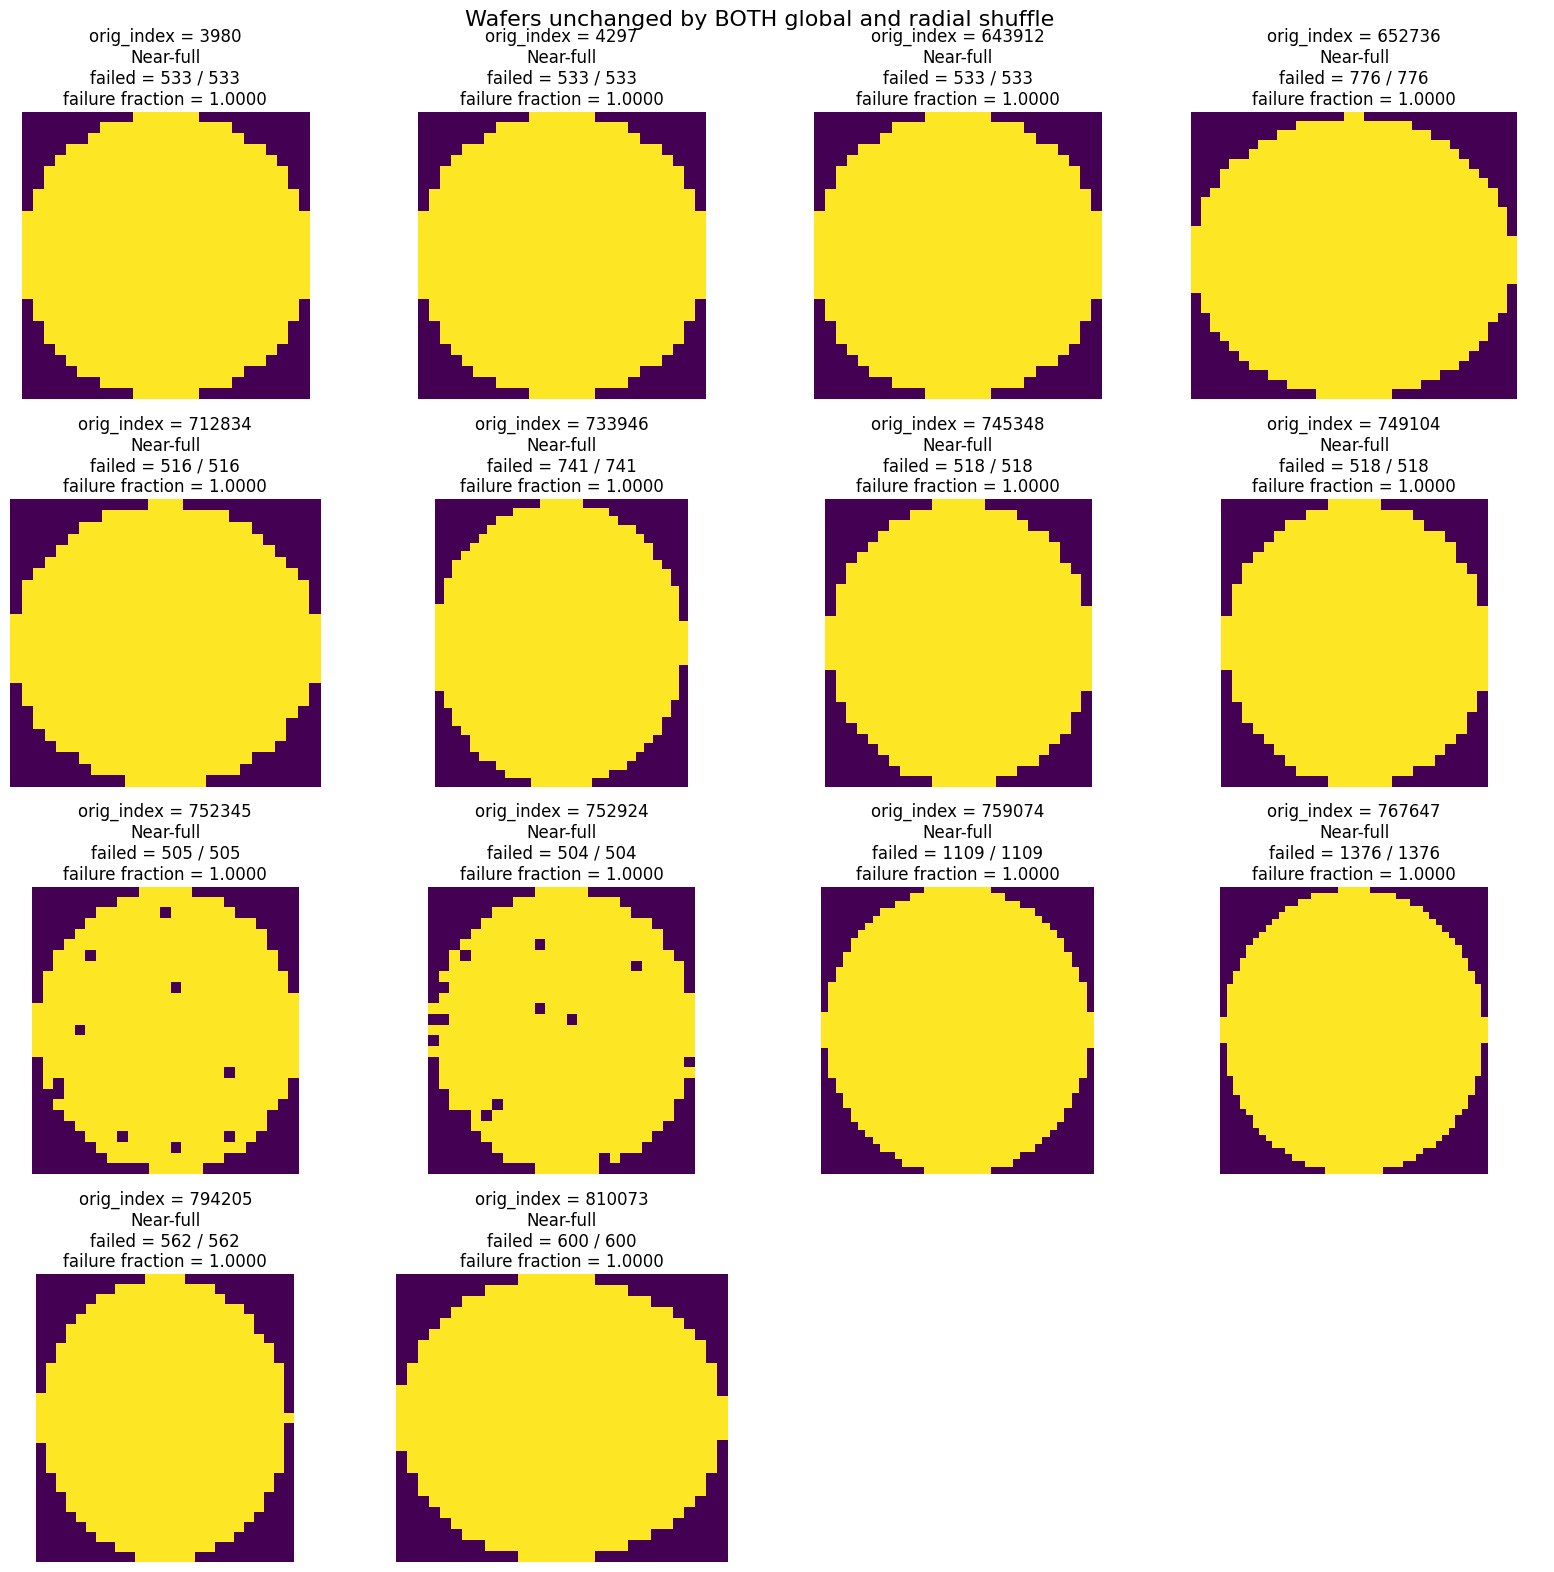


Unchanged-by-both wafers that are 100% failed: 14 / 14


In [ ]:
# ============================================================
# CHECK WHY 14 NEAR-FULL WAFERS WERE UNCHANGED
# + PLOT ALL OF THEM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Find wafers unchanged by at least one randomization
# ------------------------------------------------------------

unchanged_check = representation_audit[
    representation_audit[
        "global_identical_to_original"
    ]
    |
    representation_audit[
        "radial_identical_to_original"
    ]
][
    [
        "position",
        "orig_index",
        "label",
        "active_dies",
        "failed_dies",
        "failure_fraction",
        "global_identical_to_original",
        "radial_identical_to_original"
    ]
].copy()


print("Wafers unchanged by at least one randomization:")

display(
    unchanged_check
)


# ------------------------------------------------------------
# 2. Find wafers unchanged by BOTH methods
# ------------------------------------------------------------

same_both = (
    representation_audit[
        "global_identical_to_original"
    ]
    &
    representation_audit[
        "radial_identical_to_original"
    ]
)


n_same_both = int(
    same_both.sum()
)


print()
print("Same wafers unchanged by BOTH methods:")
print(n_same_both)


# ------------------------------------------------------------
# 3. Show their failure statistics
# ------------------------------------------------------------

same_both_table = (
    representation_audit.loc[
        same_both,
        [
            "position",
            "orig_index",
            "label",
            "active_dies",
            "failed_dies",
            "failure_fraction"
        ]
    ]
    .copy()
)


print()
print("Failure fractions of those wafers:")

display(
    same_both_table
)


# ------------------------------------------------------------
# 4. Plot all wafers unchanged by BOTH methods
#
# Encoding:
#
#   0 = background
#   1 = passing die
#   2 = failed die
#
# ------------------------------------------------------------

positions_to_plot = (
    same_both_table[
        "position"
    ]
    .astype(int)
    .tolist()
)


if len(positions_to_plot) == 0:

    print(
        "No wafers were unchanged by both methods."
    )

else:

    # 4 plots per row gives a reasonably readable grid.

    n_cols = 4

    n_rows = int(
        np.ceil(
            len(positions_to_plot)
            /
            n_cols
        )
    )


    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(
            4 * n_cols,
            4 * n_rows
        )
    )


    # Flatten axes so we can index them easily.
    axes = np.asarray(
        axes
    ).reshape(-1)


    for plot_index, position in enumerate(
        positions_to_plot
    ):

        ax = axes[
            plot_index
        ]


        # Retrieve the ORIGINAL native wafer map.
        wafer = get_native_wafer(
            position
        )


        row = representation_audit.loc[
            position
        ]


        ax.imshow(
            wafer,
            interpolation="nearest",
            vmin=0,
            vmax=2
        )


        ax.set_title(
            f"orig_index = {int(row['orig_index'])}\n"
            f"{row['label']}\n"
            f"failed = {int(row['failed_dies'])} / "
            f"{int(row['active_dies'])}\n"
            f"failure fraction = "
            f"{row['failure_fraction']:.4f}"
        )


        ax.axis(
            "off"
        )


    # Hide any unused subplot positions.

    for plot_index in range(
        len(positions_to_plot),
        len(axes)
    ):

        axes[
            plot_index
        ].axis(
            "off"
        )


    fig.suptitle(
        (
            "Wafers unchanged by BOTH "
            "global and radial shuffle"
        ),
        fontsize=16
    )


    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# 5. Extra diagnostic:
#
# How many of these wafers are literally 100% failed?
# ------------------------------------------------------------

fully_failed = (
    same_both_table[
        "failed_dies"
    ]
    ==
    same_both_table[
        "active_dies"
    ]
)


print()
print(
    "Unchanged-by-both wafers that are 100% failed:",
    f"{fully_failed.sum()} / {len(same_both_table)}"
)

SELECTED WAFERS FOR VISUAL INSPECTION


,label,position,orig_index,active_dies,failed_dies,failure_fraction,global_fraction_changed,radial_fraction_changed
0,Center,14275,525359,515,129,0.250485,0.361165,0.357282
1,Edge-Ring,5304,187907,3036,426,0.140316,0.235178,0.177866
2,Scratch,25194,810142,600,55,0.091667,0.173333,0.160000
3,Random,7940,243255,1638,781,0.476801,0.488400,0.484737
4,Near-full,19374,698366,516,453,0.877907,0.209302,0.201550


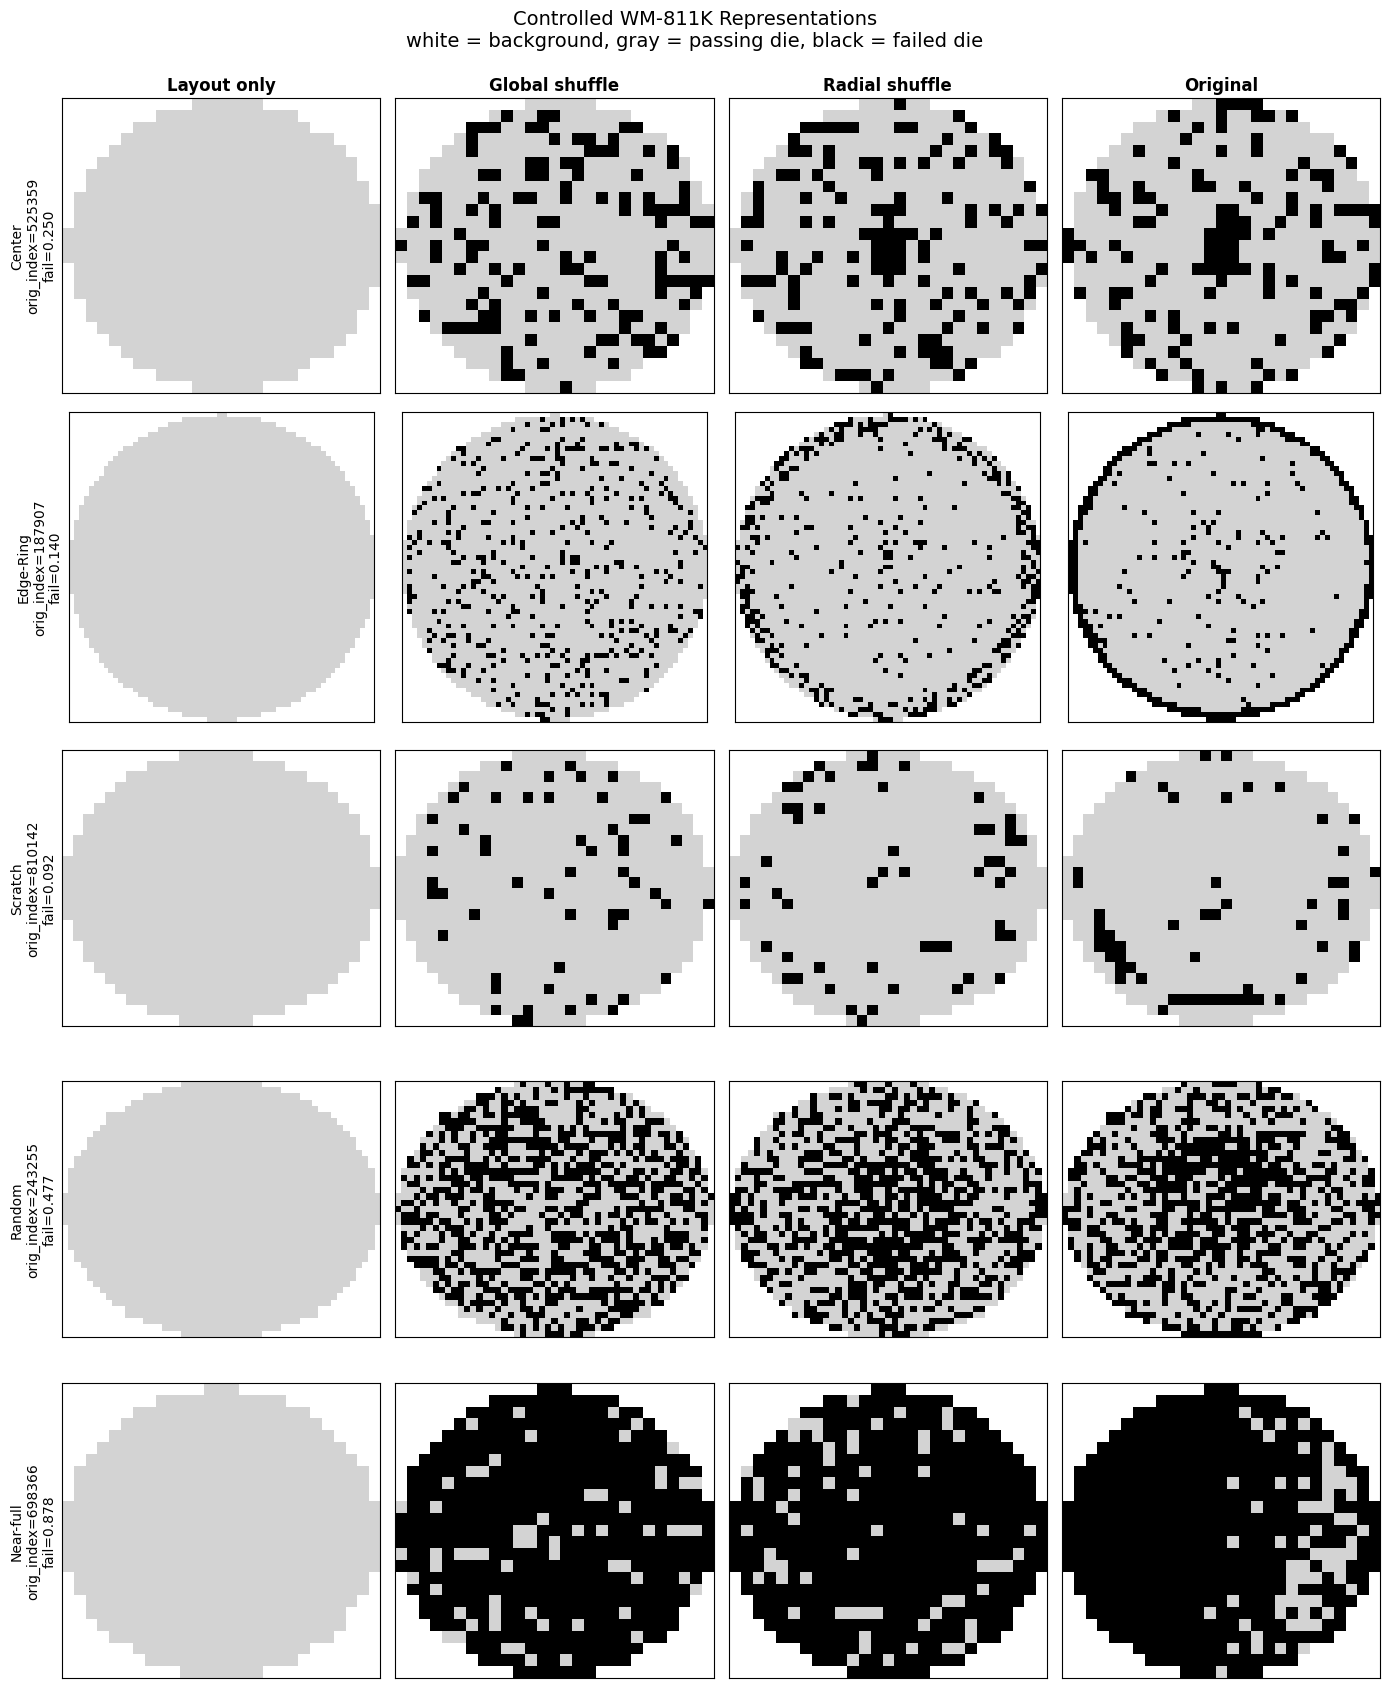

DISPLAYED-WAFER NUMERICAL CHECK


,label,orig_index,active_dies,original_failed,global_failed,radial_failed,layout_only_failed,global_fraction_changed,radial_fraction_changed
0,Center,525359,515,129,129,129,0,0.361165,0.357282
1,Edge-Ring,187907,3036,426,426,426,0,0.235178,0.177866
2,Scratch,810142,600,55,55,55,0,0.173333,0.160000
3,Random,243255,1638,781,781,781,0,0.488400,0.484737
4,Near-full,698366,516,453,453,453,0,0.209302,0.201550



RADIAL-BIN COUNTS FOR DISPLAYED WAFERS
Original failed-die counts:


radial_bin,0,1,2,3,4,5,6,7
label,,,,,,,,
Center,9,12,5,11,14,19,26,33
Edge-Ring,8,13,24,11,20,26,14,310
Scratch,2,2,0,2,3,12,27,7
Random,20,57,107,123,119,122,143,90
Near-full,8,26,40,60,66,75,95,83


Radial-shuffle failed-die counts:


radial_bin,0,1,2,3,4,5,6,7
label,,,,,,,,
Center,9,12,5,11,14,19,26,33
Edge-Ring,8,13,24,11,20,26,14,310
Scratch,2,2,0,2,3,12,27,7
Random,20,57,107,123,119,122,143,90
Near-full,8,26,40,60,66,75,95,83


PASS: all displayed radial-bin counts match exactly.

NOTEBOOK 2 — CELL 3 COMPLETE

Representation protocol:
521acba6f279b393ef3bfe47d134b2caddcd9d606b38fb353c8fa79a8ad25a8c

Visual selections saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/visual_sanity_checks/cell3_visual_selection.csv

No resizing performed.
No model trained.
No split assignment changed.


In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 3
# Visual inspection of controlled representations
# ============================================================
#
# PURPOSE
# -------
#
# Before resizing or training anything, visually verify that:
#
#   layout_only
#       shows geometry but no failures
#
#   global_shuffle
#       preserves total failure count but destroys location
#
#   radial_shuffle
#       preserves coarse radial distribution but destroys
#       fine spatial structure
#
#   original
#       retains the actual defect pattern
#
#
# We inspect five especially informative classes:
#
#   Center
#   Edge-Ring
#   Scratch
#   Random
#   Near-full
#
#
# The sample for each class is chosen automatically near that
# class's median failure fraction.
#
# This is ONLY for visualization.
#
# Sample selection here does NOT affect:
#
#   training
#   validation
#   testing
#   model selection
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [
    "metadata",
    "representation_audit",
    "get_representation",
    "REPRESENTATION_PROTOCOL_SHA256"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-2 first."
        )


# ------------------------------------------------------------
# 1. Classes chosen for visual inspection
# ------------------------------------------------------------

VISUAL_CLASSES = [

    "Center",

    "Edge-Ring",

    "Scratch",

    "Random",

    "Near-full"
]


REPRESENTATIONS_TO_SHOW = [

    "layout_only",

    "global_shuffle",

    "radial_shuffle",

    "original"
]


# ------------------------------------------------------------
# 2. Choose representative wafers.
#
# We select a wafer whose failure fraction is close to the
# class median.
#
# Whenever possible, avoid maps where radial_shuffle happens
# to be exactly identical to the original.
#
# This is useful particularly for Near-full.
# ------------------------------------------------------------

selected_rows = []


for label in VISUAL_CLASSES:

    class_rows = (
        representation_audit[
            representation_audit[
                "label"
            ] == label
        ]
        .copy()
    )


    class_median_failure_fraction = (
        class_rows[
            "failure_fraction"
        ]
        .median()
    )


    # Prefer examples whose radial shuffle really changed.

    changed_rows = class_rows[
        ~class_rows[
            "radial_identical_to_original"
        ]
    ]


    if len(changed_rows) > 0:

        candidate_rows = changed_rows

    else:

        candidate_rows = class_rows


    candidate_rows = (
        candidate_rows
        .assign(

            distance_from_class_median=lambda df:

                np.abs(
                    df[
                        "failure_fraction"
                    ]
                    -
                    class_median_failure_fraction
                )
        )
    )


    selected = (
        candidate_rows
        .sort_values(
            [
                "distance_from_class_median",
                "orig_index"
            ]
        )
        .iloc[0]
    )


    selected_rows.append(
        {

            "label":
                label,

            "position":
                int(
                    selected[
                        "position"
                    ]
                ),

            "orig_index":
                int(
                    selected[
                        "orig_index"
                    ]
                ),

            "active_dies":
                int(
                    selected[
                        "active_dies"
                    ]
                ),

            "failed_dies":
                int(
                    selected[
                        "failed_dies"
                    ]
                ),

            "failure_fraction":
                float(
                    selected[
                        "failure_fraction"
                    ]
                ),

            "global_fraction_changed":
                float(
                    selected[
                        "global_fraction_active_positions_changed"
                    ]
                ),

            "radial_fraction_changed":
                float(
                    selected[
                        "radial_fraction_active_positions_changed"
                    ]
                )
        }
    )


visual_selection = pd.DataFrame(
    selected_rows
)


print("=" * 78)
print("SELECTED WAFERS FOR VISUAL INSPECTION")
print("=" * 78)

display(
    visual_selection
)

print()


# ------------------------------------------------------------
# 3. Discrete wafer-map colour map.
#
# 0 = background
# 1 = passing die
# 2 = failed die
#
# The SAME colors are used for all four representations.
# ------------------------------------------------------------

wafer_cmap = ListedColormap(
    [
        "white",
        "lightgray",
        "black"
    ]
)


# ------------------------------------------------------------
# 4. Create 5 x 4 visualization.
#
# Rows:
#       defect classes
#
# Columns:
#       controlled representations
#
# ------------------------------------------------------------

n_rows = len(
    VISUAL_CLASSES
)


n_cols = len(
    REPRESENTATIONS_TO_SHOW
)


fig, axes = plt.subplots(

    n_rows,

    n_cols,

    figsize=(
        14,
        3.4 * n_rows
    )
)


# ------------------------------------------------------------
# 5. Draw each wafer
# ------------------------------------------------------------

for row_number, selected in visual_selection.iterrows():

    position = int(
        selected[
            "position"
        ]
    )


    label = str(
        selected[
            "label"
        ]
    )


    orig_index = int(
        selected[
            "orig_index"
        ]
    )


    for column_number, representation_name in enumerate(
        REPRESENTATIONS_TO_SHOW
    ):

        wafer = get_representation(

            position,

            representation_name
        )


        ax = axes[
            row_number,
            column_number
        ]


        ax.imshow(

            wafer,

            cmap=wafer_cmap,

            vmin=0,

            vmax=2,

            interpolation="nearest"
        )


        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )


        # Column titles only on the top row.

        if row_number == 0:

            title = {

                "layout_only":
                    "Layout only",

                "global_shuffle":
                    "Global shuffle",

                "radial_shuffle":
                    "Radial shuffle",

                "original":
                    "Original"

            }[
                representation_name
            ]


            ax.set_title(
                title,
                fontsize=12,
                fontweight="bold"
            )


        # Row labels only on first column.

        if column_number == 0:

            ax.set_ylabel(

                (
                    f"{label}\n"
                    f"orig_index={orig_index}\n"
                    f"fail={selected['failure_fraction']:.3f}"
                ),

                fontsize=10
            )


fig.suptitle(

    (
        "Controlled WM-811K Representations\n"
        "white = background, gray = passing die, "
        "black = failed die"
    ),

    fontsize=14,

    y=0.995
)


plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 6. Quantitative verification for ONLY these displayed wafers.
#
# This lets us compare what our eyes see with the actual
# preserved quantities.
# ------------------------------------------------------------

display_check_rows = []


for selected in selected_rows:

    position = int(
        selected[
            "position"
        ]
    )


    original = get_representation(
        position,
        "original"
    )


    global_shuffle = get_representation(
        position,
        "global_shuffle"
    )


    radial_shuffle = get_representation(
        position,
        "radial_shuffle"
    )


    layout_only = get_representation(
        position,
        "layout_only"
    )


    display_check_rows.append(
        {

            "label":
                selected[
                    "label"
                ],

            "orig_index":
                selected[
                    "orig_index"
                ],

            "active_dies":
                int(
                    np.count_nonzero(
                        original > 0
                    )
                ),

            "original_failed":
                int(
                    np.count_nonzero(
                        original == 2
                    )
                ),

            "global_failed":
                int(
                    np.count_nonzero(
                        global_shuffle == 2
                    )
                ),

            "radial_failed":
                int(
                    np.count_nonzero(
                        radial_shuffle == 2
                    )
                ),

            "layout_only_failed":
                int(
                    np.count_nonzero(
                        layout_only == 2
                    )
                ),

            "global_fraction_changed":
                selected[
                    "global_fraction_changed"
                ],

            "radial_fraction_changed":
                selected[
                    "radial_fraction_changed"
                ]
        }
    )


display_check = pd.DataFrame(
    display_check_rows
)


print("=" * 78)
print("DISPLAYED-WAFER NUMERICAL CHECK")
print("=" * 78)

display(
    display_check
)

print()


# ------------------------------------------------------------
# 7. Explicit radial-bin check for displayed wafers.
#
# This table shows:
#
#   original failures in radial bin 0..7
#   shuffled failures in radial bin 0..7
#
# They must be exactly identical.
# ------------------------------------------------------------

radial_display_rows = []


for selected in selected_rows:

    position = int(
        selected[
            "position"
        ]
    )


    label = selected[
        "label"
    ]


    original = get_representation(
        position,
        "original"
    )


    radial_shuffle = get_representation(
        position,
        "radial_shuffle"
    )


    valid_mask = (
        original > 0
    )


    radial_bins = compute_radial_bins(
        valid_mask
    )


    for radial_bin in range(
        N_RADIAL_BINS
    ):

        bin_mask = (
            radial_bins
            ==
            radial_bin
        )


        original_count = int(
            np.count_nonzero(

                (original == 2)
                &
                bin_mask
            )
        )


        shuffled_count = int(
            np.count_nonzero(

                (radial_shuffle == 2)
                &
                bin_mask
            )
        )


        radial_display_rows.append(
            {

                "label":
                    label,

                "radial_bin":
                    radial_bin,

                "original_failed":
                    original_count,

                "radial_shuffle_failed":
                    shuffled_count,

                "match":
                    (
                        original_count
                        ==
                        shuffled_count
                    )
            }
        )


radial_display_check = pd.DataFrame(
    radial_display_rows
)


print("=" * 78)
print("RADIAL-BIN COUNTS FOR DISPLAYED WAFERS")
print("=" * 78)


radial_pivot_original = (
    radial_display_check
    .pivot(
        index="label",
        columns="radial_bin",
        values="original_failed"
    )
    .reindex(
        VISUAL_CLASSES
    )
)


radial_pivot_shuffle = (
    radial_display_check
    .pivot(
        index="label",
        columns="radial_bin",
        values="radial_shuffle_failed"
    )
    .reindex(
        VISUAL_CLASSES
    )
)


print(
    "Original failed-die counts:"
)

display(
    radial_pivot_original
)


print(
    "Radial-shuffle failed-die counts:"
)

display(
    radial_pivot_shuffle
)


assert (
    radial_display_check[
        "match"
    ]
).all()


print(
    "PASS: all displayed radial-bin counts match exactly."
)

print()


# ------------------------------------------------------------
# 8. Save which wafers we displayed.
#
# This means figures can be reproduced later using exactly
# the same examples.
# ------------------------------------------------------------

visual_output_dir = (
    EXPERIMENT_DIR /
    "visual_sanity_checks"
)


visual_output_dir.mkdir(
    parents=True,
    exist_ok=True
)


selection_path = (
    visual_output_dir /
    "cell3_visual_selection.csv"
)


visual_selection.to_csv(
    selection_path,
    index=False
)


print("=" * 78)
print("NOTEBOOK 2 — CELL 3 COMPLETE")
print("=" * 78)

print()

print(
    "Representation protocol:"
)

print(
    REPRESENTATION_PROTOCOL_SHA256
)

print()

print(
    "Visual selections saved to:"
)

print(
    selection_path
)

print()

print(
    "No resizing performed."
)

print(
    "No model trained."
)

print(
    "No split assignment changed."
)

In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 4
# Audit candidate fixed-canvas preprocessing resolutions
# ============================================================
#
# PROBLEM
# -------
#
# CNNs need examples of a common size, but our native WM-811K
# maps have many different dimensions.
#
# A naive approach would resize EVERY wafer to a square.
#
# We do NOT want to do that because:
#
#   - it changes aspect ratio if stretched;
#   - it changes individual die counts;
#   - it can distort fine defect morphology;
#   - our experiment is specifically about spatial information.
#
#
# Instead we audit a:
#
#       PAD-IF-IT-FITS,
#       DOWNSCALE-ONLY-IF-NECESSARY
#
# strategy.
#
#
# For target canvas T x T:
#
#   If native height <= T AND native width <= T:
#
#       DO NOT resize.
#       Simply center-pad with zeros.
#
#   Otherwise:
#
#       shrink proportionally using nearest-neighbour
#       interpolation until it fits inside T x T,
#       then center-pad.
#
#
# Thus most wafers may remain pixel-for-pixel native.
#
#
# Candidate canvas sizes:
#
#       64 x 64
#       96 x 96
#       128 x 128
#
#
# We evaluate WITHOUT training any model:
#
#   1. percentage of wafers requiring resizing
#   2. round-trip layout fidelity
#   3. round-trip defect fidelity
#   4. preprocessing-induced exact-input collisions
#   5. whether processed test inputs exactly duplicate a
#      processed train/validation input
#   6. approximate memory/computational cost
#
#
# IMPORTANT:
#
# Resolution selection will use representation fidelity and
# computational practicality only.
#
# NO classifier accuracy is used.
# NO model is trained.
#
# ============================================================


from pathlib import Path

import hashlib
import json

import cv2
import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [
    "metadata",
    "get_native_wafer",
    "EXPECTED_HANDOFF_SHA256",
    "REPRESENTATION_PROTOCOL_SHA256",
    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-3 first."
        )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Candidate canvas sizes.
#
# We are NOT choosing one yet.
# ------------------------------------------------------------

CANDIDATE_CANVAS_SIZES = [
    64,
    96,
    128
]


print("=" * 78)
print("PREPROCESSING RESOLUTION AUDIT")
print("=" * 78)

print(
    "Wafers:",
    f"{len(metadata):,}"
)

print(
    "Candidate canvas sizes:",
    CANDIDATE_CANVAS_SIZES
)

print()

print(
    "Policy:"
)

print(
    "  fit inside canvas -> center-pad only"
)

print(
    "  too large         -> aspect-preserving nearest-neighbour downscale"
)

print()


# ------------------------------------------------------------
# 2. Convert one native wafer into two binary channels.
#
# M = valid-die mask
#
#       1 = physical die
#       0 = background
#
#
# D = failed-die mask
#
#       1 = failed die
#       0 = otherwise
#
#
# This representation is convenient for the controlled
# experiment:
#
#       layout_only -> [M, zero]
#
#       other representations -> [M, D]
#
#
# We are NOT claiming this two-channel representation itself
# is novel.
# ------------------------------------------------------------

def wafer_to_binary_channels(
    wafer
):

    wafer = np.asarray(
        wafer,
        dtype=np.uint8
    )


    valid_mask = (
        wafer > 0
    ).astype(
        np.uint8
    )


    failed_mask = (
        wafer == 2
    ).astype(
        np.uint8
    )


    assert np.all(
        failed_mask
        <=
        valid_mask
    )


    return (
        valid_mask,
        failed_mask
    )


# ------------------------------------------------------------
# 3. Bounded-canvas preprocessing.
#
# IMPORTANT:
#
# We NEVER enlarge a wafer.
#
# Small wafers retain their exact native pixels and are only
# padded.
#
# Only wafers exceeding the target canvas are downscaled.
# ------------------------------------------------------------

def preprocess_bounded_canvas(
    valid_mask,
    failed_mask,
    target_size
):

    valid_mask = np.asarray(
        valid_mask,
        dtype=np.uint8
    )


    failed_mask = np.asarray(
        failed_mask,
        dtype=np.uint8
    )


    h, w = valid_mask.shape


    if failed_mask.shape != (
        h,
        w
    ):

        raise ValueError(
            "Mask shapes do not match."
        )


    # --------------------------------------------------------
    # Case A:
    # Native wafer already fits.
    #
    # Keep it EXACTLY unchanged.
    # --------------------------------------------------------

    if (
        h <= target_size
        and
        w <= target_size
    ):

        resized = False

        new_h = h

        new_w = w

        scale = 1.0

        valid_small = valid_mask

        failed_small = failed_mask


    # --------------------------------------------------------
    # Case B:
    # Native wafer is too large.
    #
    # Downscale proportionally.
    # --------------------------------------------------------

    else:

        resized = True


        scale = min(
            target_size / h,
            target_size / w
        )


        new_h = max(
            1,
            min(
                target_size,
                int(
                    round(
                        h * scale
                    )
                )
            )
        )


        new_w = max(
            1,
            min(
                target_size,
                int(
                    round(
                        w * scale
                    )
                )
            )
        )


        valid_small = cv2.resize(

            valid_mask,

            (
                new_w,
                new_h
            ),

            interpolation=cv2.INTER_NEAREST
        )


        failed_small = cv2.resize(

            failed_mask,

            (
                new_w,
                new_h
            ),

            interpolation=cv2.INTER_NEAREST
        )


        valid_small = (
            valid_small > 0
        ).astype(
            np.uint8
        )


        failed_small = (
            failed_small > 0
        ).astype(
            np.uint8
        )


        # Safety:
        # a failed pixel must always remain on a valid die.

        failed_small = (
            failed_small
            *
            valid_small
        )


    # --------------------------------------------------------
    # Center padding.
    # --------------------------------------------------------

    pad_top = (
        target_size
        -
        new_h
    ) // 2


    pad_left = (
        target_size
        -
        new_w
    ) // 2


    pad_bottom = (
        target_size
        -
        new_h
        -
        pad_top
    )


    pad_right = (
        target_size
        -
        new_w
        -
        pad_left
    )


    valid_canvas = np.pad(

        valid_small,

        (
            (
                pad_top,
                pad_bottom
            ),

            (
                pad_left,
                pad_right
            )
        ),

        mode="constant",

        constant_values=0
    )


    failed_canvas = np.pad(

        failed_small,

        (
            (
                pad_top,
                pad_bottom
            ),

            (
                pad_left,
                pad_right
            )
        ),

        mode="constant",

        constant_values=0
    )


    assert valid_canvas.shape == (
        target_size,
        target_size
    )


    assert failed_canvas.shape == (
        target_size,
        target_size
    )


    assert np.all(
        failed_canvas
        <=
        valid_canvas
    )


    transform_info = {

        "native_height":
            int(
                h
            ),

        "native_width":
            int(
                w
            ),

        "processed_height":
            int(
                new_h
            ),

        "processed_width":
            int(
                new_w
            ),

        "scale":
            float(
                scale
            ),

        "resized":
            bool(
                resized
            ),

        "pad_top":
            int(
                pad_top
            ),

        "pad_left":
            int(
                pad_left
            )
    }


    return (
        valid_canvas,
        failed_canvas,
        transform_info
    )


# ------------------------------------------------------------
# 4. Round-trip reconstruction.
#
# This is only an AUDIT TOOL.
#
# We:
#
#   1. remove the padding;
#   2. resize the processed map back to its native dimensions;
#   3. compare it with the true native map.
#
#
# If no resize occurred, reconstruction should be exactly
# identical.
# ------------------------------------------------------------

def roundtrip_from_canvas(
    valid_canvas,
    failed_canvas,
    transform_info
):

    h = int(
        transform_info[
            "native_height"
        ]
    )


    w = int(
        transform_info[
            "native_width"
        ]
    )


    new_h = int(
        transform_info[
            "processed_height"
        ]
    )


    new_w = int(
        transform_info[
            "processed_width"
        ]
    )


    pad_top = int(
        transform_info[
            "pad_top"
        ]
    )


    pad_left = int(
        transform_info[
            "pad_left"
        ]
    )


    valid_crop = valid_canvas[

        pad_top:
        pad_top + new_h,

        pad_left:
        pad_left + new_w
    ]


    failed_crop = failed_canvas[

        pad_top:
        pad_top + new_h,

        pad_left:
        pad_left + new_w
    ]


    # No resize occurred.
    #
    # Return exact crop.

    if (
        new_h == h
        and
        new_w == w
    ):

        valid_back = (
            valid_crop.copy()
        )

        failed_back = (
            failed_crop.copy()
        )


    else:

        valid_back = cv2.resize(

            valid_crop,

            (
                w,
                h
            ),

            interpolation=cv2.INTER_NEAREST
        )


        failed_back = cv2.resize(

            failed_crop,

            (
                w,
                h
            ),

            interpolation=cv2.INTER_NEAREST
        )


        valid_back = (
            valid_back > 0
        ).astype(
            np.uint8
        )


        failed_back = (
            failed_back > 0
        ).astype(
            np.uint8
        )


        failed_back = (
            failed_back
            *
            valid_back
        )


    return (
        valid_back,
        failed_back
    )


# ------------------------------------------------------------
# 5. Binary IoU helper.
# ------------------------------------------------------------

def binary_iou(
    a,
    b
):

    a = np.asarray(
        a,
        dtype=bool
    )


    b = np.asarray(
        b,
        dtype=bool
    )


    intersection = np.count_nonzero(
        a
        &
        b
    )


    union = np.count_nonzero(
        a
        |
        b
    )


    if union == 0:

        return 1.0


    return (
        intersection
        /
        union
    )


# ------------------------------------------------------------
# 6. Hash one processed two-channel input.
#
# This identifies the EXACT input the CNN would receive.
#
# Hash content:
#
#       target size
#       M channel
#       D channel
# ------------------------------------------------------------

def hash_processed_input(
    valid_canvas,
    failed_canvas,
    target_size
):

    h = hashlib.blake2b(
        digest_size=16
    )


    h.update(
        int(
            target_size
        ).to_bytes(
            4,
            byteorder="little",
            signed=False
        )
    )


    h.update(
        np.ascontiguousarray(
            valid_canvas,
            dtype=np.uint8
        ).tobytes()
    )


    h.update(
        np.ascontiguousarray(
            failed_canvas,
            dtype=np.uint8
        ).tobytes()
    )


    return h.hexdigest()


# ------------------------------------------------------------
# 7. Audit all three candidate resolutions.
#
# NOTE:
#
# We use ORIGINAL maps for this resolution audit.
#
# We are studying the observation/preprocessing operator,
# not yet comparing experimental representations.
#
# Once a resolution is frozen, we will audit all four
# representations at that chosen resolution.
# ------------------------------------------------------------

all_preprocessing_rows = []

resolution_summary_rows = []

processed_hashes_by_size = {}


for target_size in CANDIDATE_CANVAS_SIZES:

    print("=" * 78)

    print(
        f"AUDITING {target_size} x {target_size}"
    )

    print("=" * 78)


    rows_for_size = []

    processed_hashes = []


    for position in tqdm(

        range(
            len(
                metadata
            )
        ),

        desc=f"{target_size}x{target_size}"
    ):

        wafer = get_native_wafer(
            position
        )


        (
            valid_native,
            failed_native

        ) = wafer_to_binary_channels(
            wafer
        )


        (
            valid_canvas,
            failed_canvas,
            info

        ) = preprocess_bounded_canvas(

            valid_native,

            failed_native,

            target_size
        )


        (
            valid_back,
            failed_back

        ) = roundtrip_from_canvas(

            valid_canvas,

            failed_canvas,

            info
        )


        # ----------------------------------------------------
        # Layout fidelity.
        # ----------------------------------------------------

        layout_iou = binary_iou(

            valid_native,

            valid_back
        )


        # ----------------------------------------------------
        # Failed-die fidelity.
        # ----------------------------------------------------

        failed_iou = binary_iou(

            failed_native,

            failed_back
        )


        # ----------------------------------------------------
        # Exact native reconstruction?
        # ----------------------------------------------------

        layout_exact = np.array_equal(

            valid_native,

            valid_back
        )


        failed_exact = np.array_equal(

            failed_native,

            failed_back
        )


        ternary_exact = (
            layout_exact
            and
            failed_exact
        )


        # ----------------------------------------------------
        # Processed input fingerprint.
        # ----------------------------------------------------

        processed_hash = hash_processed_input(

            valid_canvas,

            failed_canvas,

            target_size
        )


        processed_hashes.append(
            processed_hash
        )


        row = {

            "target_size":
                target_size,

            "position":
                position,

            "orig_index":
                int(
                    metadata.loc[
                        position,
                        "orig_index"
                    ]
                ),

            "exact_map_hash":
                str(
                    metadata.loc[
                        position,
                        "exact_map_hash"
                    ]
                ),

            "outer_fold":
                int(
                    metadata.loc[
                        position,
                        "outer_fold"
                    ]
                ),

            "native_height":
                int(
                    valid_native.shape[0]
                ),

            "native_width":
                int(
                    valid_native.shape[1]
                ),

            "resized":
                bool(
                    info[
                        "resized"
                    ]
                ),

            "scale":
                float(
                    info[
                        "scale"
                    ]
                ),

            "processed_height":
                int(
                    info[
                        "processed_height"
                    ]
                ),

            "processed_width":
                int(
                    info[
                        "processed_width"
                    ]
                ),

            "layout_iou_roundtrip":
                float(
                    layout_iou
                ),

            "failed_iou_roundtrip":
                float(
                    failed_iou
                ),

            "layout_exact_roundtrip":
                bool(
                    layout_exact
                ),

            "failed_exact_roundtrip":
                bool(
                    failed_exact
                ),

            "complete_exact_roundtrip":
                bool(
                    ternary_exact
                ),

            "processed_original_hash":
                processed_hash
        }


        rows_for_size.append(
            row
        )


    size_df = pd.DataFrame(
        rows_for_size
    )


    processed_hashes = np.asarray(
        processed_hashes,
        dtype=object
    )


    processed_hashes_by_size[
        target_size
    ] = processed_hashes


    all_preprocessing_rows.append(
        size_df
    )


    # --------------------------------------------------------
    # 8. Collision audit.
    #
    # Native exact duplicates are already expected.
    #
    # What we care about here is whether DIFFERENT native maps
    # become the SAME processed CNN input.
    # --------------------------------------------------------

    collision_frame = pd.DataFrame(
        {

            "processed_hash":
                processed_hashes,

            "native_exact_hash":
                metadata[
                    "exact_map_hash"
                ].astype(
                    str
                ).to_numpy()
        }
    )


    collision_groups = (

        collision_frame

        .groupby(
            "processed_hash",
            observed=True
        )

        .agg(

            rows=(
                "native_exact_hash",
                "size"
            ),

            distinct_native_maps=(
                "native_exact_hash",
                "nunique"
            )
        )
    )


    induced_collisions = (
        collision_groups[
            collision_groups[
                "distinct_native_maps"
            ] > 1
        ]
    )


    induced_collision_hashes = set(
        induced_collisions.index
    )


    rows_in_induced_collisions = int(
        collision_frame[
            "processed_hash"
        ]
        .isin(
            induced_collision_hashes
        )
        .sum()
    )


    # --------------------------------------------------------
    # 9. Does a processed TEST input exactly occur in the
    #    corresponding train+validation pool?
    #
    # Native exact maps were already made group-disjoint.
    #
    # Therefore any such overlap here is created by
    # preprocessing itself.
    # --------------------------------------------------------

    fold_collision_percentages = []


    for outer_fold in [
        1,
        2,
        3
    ]:

        is_test = (
            metadata[
                "outer_fold"
            ].to_numpy()
            ==
            outer_fold
        )


        trainval_hashes = set(
            processed_hashes[
                ~is_test
            ]
        )


        test_hashes = processed_hashes[
            is_test
        ]


        test_seen = np.asarray(
            [
                value in trainval_hashes

                for value
                in test_hashes
            ],
            dtype=bool
        )


        percent_seen = float(

            100
            *
            test_seen.mean()
        )


        fold_collision_percentages.append(
            percent_seen
        )


    # --------------------------------------------------------
    # 10. Memory estimate for a full cached dataset.
    #
    # Our actual implementation can stream batches, but these
    # numbers help us understand the scale.
    # --------------------------------------------------------

    n_wafers = len(
        metadata
    )


    two_channel_uint8_mib = (

        n_wafers
        *
        target_size
        *
        target_size
        *
        2
        /
        1024**2
    )


    two_channel_float32_mib = (

        two_channel_uint8_mib
        *
        4
    )


    relative_pixel_cost_vs_64 = (
        target_size
        /
        64
    ) ** 2


    native_unique_maps = (
        metadata[
            "exact_map_hash"
        ]
        .nunique()
    )


    processed_unique_inputs = int(
        collision_frame[
            "processed_hash"
        ]
        .nunique()
    )


    # --------------------------------------------------------
    # 11. Summary row.
    # --------------------------------------------------------

    resolution_summary_rows.append(
        {

            "target_size":
                target_size,

            "wafers":
                int(
                    len(
                        size_df
                    )
                ),

            "wafers_not_resized":
                int(
                    (
                        ~size_df[
                            "resized"
                        ]
                    ).sum()
                ),

            "percent_not_resized":
                float(

                    100
                    *
                    (
                        ~size_df[
                            "resized"
                        ]
                    ).mean()
                ),

            "wafers_downscaled":
                int(
                    size_df[
                        "resized"
                    ].sum()
                ),

            "percent_downscaled":
                float(

                    100
                    *
                    size_df[
                        "resized"
                    ].mean()
                ),

            "percent_complete_exact_roundtrip":
                float(

                    100
                    *
                    size_df[
                        "complete_exact_roundtrip"
                    ].mean()
                ),

            "median_layout_iou":
                float(
                    size_df[
                        "layout_iou_roundtrip"
                    ].median()
                ),

            "minimum_layout_iou":
                float(
                    size_df[
                        "layout_iou_roundtrip"
                    ].min()
                ),

            "median_failed_iou":
                float(
                    size_df[
                        "failed_iou_roundtrip"
                    ].median()
                ),

            "p01_failed_iou":
                float(
                    size_df[
                        "failed_iou_roundtrip"
                    ].quantile(
                        0.01
                    )
                ),

            "minimum_failed_iou":
                float(
                    size_df[
                        "failed_iou_roundtrip"
                    ].min()
                ),

            "native_unique_exact_maps":
                int(
                    native_unique_maps
                ),

            "processed_unique_inputs":
                int(
                    processed_unique_inputs
                ),

            "induced_collision_clusters":
                int(
                    len(
                        induced_collisions
                    )
                ),

            "rows_in_induced_collision_clusters":
                int(
                    rows_in_induced_collisions
                ),

            "largest_distinct_native_maps_in_one_processed_input":
                (
                    int(
                        induced_collisions[
                            "distinct_native_maps"
                        ].max()
                    )

                    if len(
                        induced_collisions
                    ) > 0

                    else 1
                ),

            "outer_fold_1_test_processed_seen_in_trainval_percent":
                float(
                    fold_collision_percentages[
                        0
                    ]
                ),

            "outer_fold_2_test_processed_seen_in_trainval_percent":
                float(
                    fold_collision_percentages[
                        1
                    ]
                ),

            "outer_fold_3_test_processed_seen_in_trainval_percent":
                float(
                    fold_collision_percentages[
                        2
                    ]
                ),

            "max_test_processed_seen_in_trainval_percent":
                float(
                    max(
                        fold_collision_percentages
                    )
                ),

            "two_channel_uint8_cache_MiB":
                float(
                    two_channel_uint8_mib
                ),

            "two_channel_float32_cache_MiB":
                float(
                    two_channel_float32_mib
                ),

            "relative_pixel_cost_vs_64":
                float(
                    relative_pixel_cost_vs_64
                )
        }
    )


# ------------------------------------------------------------
# 12. Combine per-wafer audit data.
# ------------------------------------------------------------

preprocessing_audit = pd.concat(
    all_preprocessing_rows,
    ignore_index=True
)


resolution_summary = pd.DataFrame(
    resolution_summary_rows
)


# ------------------------------------------------------------
# 13. Main comparison table.
# ------------------------------------------------------------

print("=" * 78)
print("CANDIDATE RESOLUTION COMPARISON")
print("=" * 78)


comparison_columns = [

    "target_size",

    "percent_not_resized",

    "wafers_downscaled",

    "percent_complete_exact_roundtrip",

    "median_layout_iou",

    "minimum_layout_iou",

    "median_failed_iou",

    "p01_failed_iou",

    "minimum_failed_iou",

    "induced_collision_clusters",

    "rows_in_induced_collision_clusters",

    "max_test_processed_seen_in_trainval_percent",

    "two_channel_uint8_cache_MiB",

    "relative_pixel_cost_vs_64"
]


display(
    resolution_summary[
        comparison_columns
    ]
)


print()


# ------------------------------------------------------------
# 14. Native-size distribution.
#
# This tells us WHY certain resolutions require resizing.
# ------------------------------------------------------------

max_native_dimension = np.maximum(

    metadata[
        "height"
    ].to_numpy(),

    metadata[
        "width"
    ].to_numpy()
)


native_size_summary = pd.Series(
    max_native_dimension,
    name="maximum_native_dimension"
).describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.995,
        0.999
    ]
)


print("=" * 78)
print("NATIVE MAXIMUM-DIMENSION DISTRIBUTION")
print("=" * 78)

display(
    native_size_summary
)

print()


for target_size in CANDIDATE_CANVAS_SIZES:

    number_fitting = int(
        np.count_nonzero(
            max_native_dimension
            <=
            target_size
        )
    )


    print(
        f"{target_size:3d} x {target_size:3d}: "
        f"{number_fitting:6,d} / {len(metadata):,} "
        f"({100 * number_fitting / len(metadata):.3f}%) "
        f"fit without resizing"
    )


print()


# ------------------------------------------------------------
# 15. Focus specifically on wafers that WERE downscaled.
#
# Otherwise the many exact pad-only maps can make median IoU
# look artificially perfect.
# ------------------------------------------------------------

downscaled_summary_rows = []


for target_size in CANDIDATE_CANVAS_SIZES:

    subset = preprocessing_audit[
        (
            preprocessing_audit[
                "target_size"
            ]
            ==
            target_size
        )
        &
        (
            preprocessing_audit[
                "resized"
            ]
        )
    ]


    if len(
        subset
    ) == 0:

        downscaled_summary_rows.append(
            {

                "target_size":
                    target_size,

                "downscaled_wafers":
                    0,

                "median_layout_iou":
                    np.nan,

                "p05_layout_iou":
                    np.nan,

                "median_failed_iou":
                    np.nan,

                "p05_failed_iou":
                    np.nan,

                "minimum_failed_iou":
                    np.nan
            }
        )


    else:

        downscaled_summary_rows.append(
            {

                "target_size":
                    target_size,

                "downscaled_wafers":
                    int(
                        len(
                            subset
                        )
                    ),

                "median_layout_iou":
                    float(
                        subset[
                            "layout_iou_roundtrip"
                        ].median()
                    ),

                "p05_layout_iou":
                    float(
                        subset[
                            "layout_iou_roundtrip"
                        ].quantile(
                            0.05
                        )
                    ),

                "median_failed_iou":
                    float(
                        subset[
                            "failed_iou_roundtrip"
                        ].median()
                    ),

                "p05_failed_iou":
                    float(
                        subset[
                            "failed_iou_roundtrip"
                        ].quantile(
                            0.05
                        )
                    ),

                "minimum_failed_iou":
                    float(
                        subset[
                            "failed_iou_roundtrip"
                        ].min()
                    )
            }
        )


downscaled_summary = pd.DataFrame(
    downscaled_summary_rows
)


print("=" * 78)
print("FIDELITY AMONG DOWNSCALED WAFERS ONLY")
print("=" * 78)

display(
    downscaled_summary
)

print()


# ------------------------------------------------------------
# 16. Check that ALL maps fitting inside the canvas really are
#     recovered exactly after pad-only processing.
# ------------------------------------------------------------

for target_size in CANDIDATE_CANVAS_SIZES:

    fit_subset = preprocessing_audit[
        (
            preprocessing_audit[
                "target_size"
            ]
            ==
            target_size
        )
        &
        (
            ~preprocessing_audit[
                "resized"
            ]
        )
    ]


    assert (
        fit_subset[
            "complete_exact_roundtrip"
        ]
    ).all()


print(
    "PASS: every pad-only wafer is exactly recoverable."
)

print()


# ------------------------------------------------------------
# 17. Save this audit.
#
# IMPORTANT:
#
# We are NOT freezing a resolution here.
#
# This cell only measures the candidates.
# ------------------------------------------------------------

PREPROCESSING_AUDIT_DIR = (
    EXPERIMENT_DIR /
    "preprocessing_audit"
)


PREPROCESSING_AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


resolution_summary_path = (
    PREPROCESSING_AUDIT_DIR /
    "cell4_candidate_resolution_summary.csv"
)


downscaled_summary_path = (
    PREPROCESSING_AUDIT_DIR /
    "cell4_downscaled_fidelity_summary.csv"
)


per_wafer_path = (
    PREPROCESSING_AUDIT_DIR /
    "cell4_per_wafer_preprocessing_audit.csv"
)


native_dimension_path = (
    PREPROCESSING_AUDIT_DIR /
    "cell4_native_dimension_summary.json"
)


resolution_summary.to_csv(
    resolution_summary_path,
    index=False
)


downscaled_summary.to_csv(
    downscaled_summary_path,
    index=False
)


preprocessing_audit.to_csv(
    per_wafer_path,
    index=False
)


native_dimension_record = {

    "n_wafers":
        int(
            len(
                metadata
            )
        ),

    "minimum_max_dimension":
        int(
            max_native_dimension.min()
        ),

    "median_max_dimension":
        float(
            np.median(
                max_native_dimension
            )
        ),

    "maximum_max_dimension":
        int(
            max_native_dimension.max()
        ),

    "candidate_sizes":
        CANDIDATE_CANVAS_SIZES,

    "representation_protocol_sha256":
        REPRESENTATION_PROTOCOL_SHA256,

    "resolution_selected":
        None,

    "model_performance_used":
        False
}


with open(
    native_dimension_path,
    "w"
) as f:

    json.dump(
        native_dimension_record,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 18. Final summary
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 4 COMPLETE")
print("=" * 78)

print()

print(
    "Canvas sizes audited:",
    CANDIDATE_CANVAS_SIZES
)

print()

print(
    "Preprocessing method:"
)

print(
    "  native-size center padding whenever possible"
)

print(
    "  aspect-preserving nearest-neighbour downscale "
    "only when required"
)

print()

print(
    "Resolution has NOT been selected yet."
)

print(
    "No labels were used to optimize preprocessing."
)

print(
    "No model was trained."
)

print(
    "No train/validation/test assignment was changed."
)

print()

print(
    "Saved to:"
)

print(
    PREPROCESSING_AUDIT_DIR
)

PREPROCESSING RESOLUTION AUDIT
Wafers: 25,513
Candidate canvas sizes: [64, 96, 128]

Policy:
  fit inside canvas -> center-pad only
  too large         -> aspect-preserving nearest-neighbour downscale

AUDITING 64 x 64


64x64:   0%|          | 0/25513 [00:00<?, ?it/s]

AUDITING 96 x 96


96x96:   0%|          | 0/25513 [00:00<?, ?it/s]

AUDITING 128 x 128


128x128:   0%|          | 0/25513 [00:00<?, ?it/s]

... (3 outputs left out)

,maximum_native_dimension
count,25513.000000
mean,45.377415
std,22.215159
min,26.000000
50%,39.000000
75%,53.000000
90%,63.000000
95%,76.000000
99%,150.000000
99.5%,150.000000



 64 x  64: 23,278 / 25,513 (91.240%) fit without resizing
 96 x  96: 24,620 / 25,513 (96.500%) fit without resizing
128 x 128: 24,848 / 25,513 (97.393%) fit without resizing

FIDELITY AMONG DOWNSCALED WAFERS ONLY


,target_size,downscaled_wafers,median_layout_iou,p05_layout_iou,median_failed_iou,p05_failed_iou,minimum_failed_iou
0,64,2235,0.958450,0.949925,0.152542,0.054320,0.000000
1,96,893,0.969319,0.961923,0.140940,0.070474,0.010526
2,128,665,0.973555,0.973555,0.141399,0.076911,0.015603



PASS: every pad-only wafer is exactly recoverable.

NOTEBOOK 2 — CELL 4 COMPLETE

Canvas sizes audited: [64, 96, 128]

Preprocessing method:
  native-size center padding whenever possible
  aspect-preserving nearest-neighbour downscale only when required

Resolution has NOT been selected yet.
No labels were used to optimize preprocessing.
No model was trained.
No train/validation/test assignment was changed.

Saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/preprocessing_audit


In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 5
# Detailed audit of wafers downscaled to 96 x 96
# ============================================================
#
# Cell 4 made 96 x 96 the strongest candidate resolution.
#
# Of our 25,513 wafers:
#
#       24,620 fit inside 96 x 96 unchanged
#          893 require actual downscaling
#
#
# For the 24,620 pad-only wafers, preprocessing cannot alter
# the wafer itself: it merely surrounds the native map with 0s.
#
# Therefore this cell focuses on the difficult 893 wafers.
#
#
# QUESTIONS
# ---------
#
# 1. Does any defect completely disappear after downscaling?
#
# 2. How much does the FAILURE FRACTION change?
#
#       native:
#           failed dies / active dies
#
#       processed:
#           failed pixels / valid pixels
#
#
# 3. How much does the coarse radial failure profile change?
#
# 4. Do original / global_shuffle / radial_shuffle remain
#    comparable after downscaling?
#
# 5. Are certain defect classes affected much more strongly?
#
#
# IMPORTANT:
#
# Raw failed-pixel count is NOT directly comparable before
# and after resizing.
#
# Example:
#
#       150 x 150 -> 96 x 96
#
# naturally contains fewer pixels after resizing.
#
# Therefore FAILURE FRACTION is the more meaningful quantity.
#
#
# No model is trained.
# 96 x 96 is still a candidate, not yet formally frozen.
#
# ============================================================


from pathlib import Path

import json

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [
    "metadata",
    "get_representation",
    "wafer_to_binary_channels",
    "preprocess_bounded_canvas",
    "compute_radial_bins",
    "N_RADIAL_BINS",
    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-4 first."
        )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Candidate resolution being examined
# ------------------------------------------------------------

AUDIT_TARGET_SIZE = 96


# Only these three contain failure information.
#
# layout_only is not included because, by definition,
# its failure channel contains zero failed dies.

FAILURE_REPRESENTATIONS = [

    "original",

    "global_shuffle",

    "radial_shuffle"
]


# ------------------------------------------------------------
# 2. Identify exactly which wafers need downscaling.
# ------------------------------------------------------------

needs_downscaling = (

    (metadata["height"] > AUDIT_TARGET_SIZE)

    |

    (metadata["width"] > AUDIT_TARGET_SIZE)
)


downscaled_positions = np.flatnonzero(
    needs_downscaling.to_numpy()
)


n_downscaled = len(
    downscaled_positions
)


print("=" * 78)
print("96 x 96 DOWNSCALING AUDIT")
print("=" * 78)

print(
    "Total primary wafers:",
    f"{len(metadata):,}"
)

print(
    "Pad-only wafers:",
    f"{len(metadata) - n_downscaled:,}"
)

print(
    "Actually downscaled:",
    f"{n_downscaled:,}"
)

print(
    "Percent downscaled:",
    f"{100 * n_downscaled / len(metadata):.3f}%"
)

print()


# This should reproduce Cell 4.

assert n_downscaled == 893


# ------------------------------------------------------------
# 3. Show which classes contain the 893 large wafers.
# ------------------------------------------------------------

downscaled_metadata = (
    metadata.iloc[
        downscaled_positions
    ]
    .copy()
)


downscaled_class_counts = (
    downscaled_metadata[
        "label"
    ]
    .value_counts()
    .reindex(
        DEFECT_CLASSES,
        fill_value=0
    )
)


class_total_counts = (
    metadata[
        "label"
    ]
    .value_counts()
    .reindex(
        DEFECT_CLASSES,
        fill_value=0
    )
)


downscaled_class_table = pd.DataFrame(
    {

        "class_total_wafers":
            class_total_counts,

        "downscaled_wafers":
            downscaled_class_counts
    }
)


downscaled_class_table[
    "percent_of_class_downscaled"
] = (

    100

    *

    downscaled_class_table[
        "downscaled_wafers"
    ]

    /

    downscaled_class_table[
        "class_total_wafers"
    ]
)


print("=" * 78)
print("WHICH CLASSES REQUIRE DOWNSCALING?")
print("=" * 78)

display(
    downscaled_class_table
)

print()


# ------------------------------------------------------------
# 4. Helper: radial distribution of FAILURE pixels.
#
# We convert the radial counts into proportions summing to 1.
#
# Example:
#
#       [0.00, 0.05, 0.10, 0.20, ...]
#
# This describes WHERE failures occur radially, independently
# of the total number of failure pixels.
# ------------------------------------------------------------

def radial_failure_distribution(
    valid_mask,
    failed_mask,
    n_bins=N_RADIAL_BINS
):

    valid_mask = np.asarray(
        valid_mask,
        dtype=bool
    )


    failed_mask = np.asarray(
        failed_mask,
        dtype=bool
    )


    radial_bins = compute_radial_bins(
        valid_mask,
        n_bins=n_bins
    )


    counts = np.zeros(
        n_bins,
        dtype=np.float64
    )


    for radial_bin in range(
        n_bins
    ):

        counts[
            radial_bin
        ] = np.count_nonzero(

            failed_mask

            &

            (
                radial_bins
                ==
                radial_bin
            )
        )


    total = counts.sum()


    if total == 0:

        return None


    return (
        counts
        /
        total
    )


# ------------------------------------------------------------
# 5. Helper: Total Variation distance.
#
# This compares two distributions.
#
#       0.0 = exactly the same
#       1.0 = completely different
#
# Example:
#
# native radial profile:
#
#       [0.1, 0.2, 0.4, 0.3]
#
# processed profile:
#
#       [0.1, 0.2, 0.4, 0.3]
#
# TV distance = 0.
# ------------------------------------------------------------

def total_variation_distance(
    distribution_a,
    distribution_b
):

    if (
        distribution_a is None
        or
        distribution_b is None
    ):

        # If the processed image lost every failure pixel,
        # treat radial-profile distortion as maximal.

        return 1.0


    return float(

        0.5

        *

        np.abs(
            distribution_a
            -
            distribution_b
        ).sum()
    )


# ------------------------------------------------------------
# 6. Audit every downscaled wafer under all three
#    failure-bearing representations.
# ------------------------------------------------------------

audit_rows = []


print("=" * 78)
print("AUDITING THE 893 DOWNSCALED WAFERS")
print("=" * 78)


for position in tqdm(

    downscaled_positions,

    total=n_downscaled,

    desc="96x96 downscale audit"
):

    position = int(
        position
    )


    orig_index = int(
        metadata.loc[
            position,
            "orig_index"
        ]
    )


    label = str(
        metadata.loc[
            position,
            "label"
        ]
    )


    # --------------------------------------------------------
    # All three representations have exactly the same valid
    # physical wafer layout.
    #
    # We will use this later to verify processed-layout
    # equality as well.
    # --------------------------------------------------------

    processed_valid_reference = None


    for representation_name in FAILURE_REPRESENTATIONS:

        wafer = get_representation(

            position,

            representation_name
        )


        (
            valid_native,
            failed_native

        ) = wafer_to_binary_channels(
            wafer
        )


        native_active = int(
            valid_native.sum()
        )


        native_failed = int(
            failed_native.sum()
        )


        native_failure_fraction = (

            native_failed
            /
            native_active
        )


        # ----------------------------------------------------
        # Apply the candidate 96x96 preprocessing.
        # ----------------------------------------------------

        (
            valid_processed,
            failed_processed,
            transform_info

        ) = preprocess_bounded_canvas(

            valid_native,

            failed_native,

            AUDIT_TARGET_SIZE
        )


        # All wafers in this cell MUST really have been resized.

        assert transform_info[
            "resized"
        ]


        processed_active = int(
            valid_processed.sum()
        )


        processed_failed = int(
            failed_processed.sum()
        )


        processed_failure_fraction = (

            processed_failed
            /
            processed_active

            if processed_active > 0

            else np.nan
        )


        # ----------------------------------------------------
        # Because all representations share the same physical
        # wafer geometry, their processed layout masks should
        # also be EXACTLY identical.
        # ----------------------------------------------------

        if processed_valid_reference is None:

            processed_valid_reference = (
                valid_processed.copy()
            )

        else:

            assert np.array_equal(

                processed_valid_reference,

                valid_processed
            )


        # ----------------------------------------------------
        # FAILURE FRACTION distortion
        #
        # This is much more meaningful than:
        #
        #       processed failed pixels
        #       -----------------------
        #       native failed dies
        #
        # because the total number of pixels necessarily
        # decreases when a wafer is shrunk.
        # ----------------------------------------------------

        failure_fraction_error = (

            processed_failure_fraction

            -
            native_failure_fraction
        )


        absolute_failure_fraction_error = abs(
            failure_fraction_error
        )


        # Ratio around 1.0 means failure density is preserved.
        #
        # 0.9 means processed failure fraction is 10% lower.
        # 1.1 means it is 10% higher.

        failure_fraction_ratio = (

            processed_failure_fraction

            /
            native_failure_fraction

            if native_failure_fraction > 0

            else np.nan
        )


        # ----------------------------------------------------
        # Raw count ratio.
        #
        # We record this for completeness, but DO NOT interpret
        # it as "fraction of information retained".
        #
        # A smaller image naturally has fewer pixels.
        # ----------------------------------------------------

        raw_failed_pixel_count_ratio = (

            processed_failed

            /
            native_failed

            if native_failed > 0

            else np.nan
        )


        active_pixel_count_ratio = (

            processed_active

            /
            native_active
        )


        # ----------------------------------------------------
        # A normalized count-retention measure.
        #
        # If failed pixels shrink at exactly the same rate as
        # active pixels:
        #
        #       normalized ratio = 1
        #
        # Algebraically this is also:
        #
        #       processed failure fraction
        #       --------------------------
        #       native failure fraction
        # ----------------------------------------------------

        normalized_failure_retention = (

            raw_failed_pixel_count_ratio

            /
            active_pixel_count_ratio

            if (
                active_pixel_count_ratio > 0
                and
                native_failed > 0
            )

            else np.nan
        )


        # ----------------------------------------------------
        # Radial-profile distortion.
        # ----------------------------------------------------

        native_radial_distribution = (
            radial_failure_distribution(

                valid_native,

                failed_native
            )
        )


        processed_radial_distribution = (
            radial_failure_distribution(

                valid_processed,

                failed_processed
            )
        )


        radial_tv_distance = (
            total_variation_distance(

                native_radial_distribution,

                processed_radial_distribution
            )
        )


        # ----------------------------------------------------
        # Record results.
        # ----------------------------------------------------

        audit_rows.append(
            {

                "position":
                    position,

                "orig_index":
                    orig_index,

                "label":
                    label,

                "representation":
                    representation_name,

                "native_height":
                    int(
                        valid_native.shape[0]
                    ),

                "native_width":
                    int(
                        valid_native.shape[1]
                    ),

                "processed_height":
                    int(
                        transform_info[
                            "processed_height"
                        ]
                    ),

                "processed_width":
                    int(
                        transform_info[
                            "processed_width"
                        ]
                    ),

                "scale":
                    float(
                        transform_info[
                            "scale"
                        ]
                    ),

                "native_active_dies":
                    native_active,

                "native_failed_dies":
                    native_failed,

                "processed_active_pixels":
                    processed_active,

                "processed_failed_pixels":
                    processed_failed,

                "native_failure_fraction":
                    float(
                        native_failure_fraction
                    ),

                "processed_failure_fraction":
                    float(
                        processed_failure_fraction
                    ),

                "failure_fraction_error":
                    float(
                        failure_fraction_error
                    ),

                "absolute_failure_fraction_error":
                    float(
                        absolute_failure_fraction_error
                    ),

                "failure_fraction_ratio":
                    float(
                        failure_fraction_ratio
                    ),

                "raw_failed_pixel_count_ratio":
                    float(
                        raw_failed_pixel_count_ratio
                    ),

                "active_pixel_count_ratio":
                    float(
                        active_pixel_count_ratio
                    ),

                "normalized_failure_retention":
                    float(
                        normalized_failure_retention
                    ),

                "zero_failures_after_downscaling":
                    bool(
                        processed_failed == 0
                    ),

                "one_or_fewer_failure_pixels":
                    bool(
                        processed_failed <= 1
                    ),

                "five_or_fewer_failure_pixels":
                    bool(
                        processed_failed <= 5
                    ),

                "radial_profile_tv_distance":
                    float(
                        radial_tv_distance
                    )
            }
        )


downscale_audit = pd.DataFrame(
    audit_rows
)


assert len(
    downscale_audit
) == (
    n_downscaled
    *
    len(
        FAILURE_REPRESENTATIONS
    )
)


print()

print(
    "PASS: processed wafer-layout masks are identical "
    "across original/global/radial representations."
)

print()


# ------------------------------------------------------------
# 7. FAILURE SIGNAL SURVIVAL
#
# First ask the simplest and most important question:
#
# Does the defect disappear completely?
# ------------------------------------------------------------

signal_survival_summary = (

    downscale_audit

    .groupby(
        "representation",
        observed=True
    )

    .agg(

        wafers=(
            "orig_index",
            "size"
        ),

        zero_failure_pixels=(
            "zero_failures_after_downscaling",
            "sum"
        ),

        one_or_fewer_failure_pixels=(
            "one_or_fewer_failure_pixels",
            "sum"
        ),

        five_or_fewer_failure_pixels=(
            "five_or_fewer_failure_pixels",
            "sum"
        ),

        minimum_processed_failure_pixels=(
            "processed_failed_pixels",
            "min"
        ),

        median_processed_failure_pixels=(
            "processed_failed_pixels",
            "median"
        )
    )

    .reindex(
        FAILURE_REPRESENTATIONS
    )
)


print("=" * 78)
print("FAILURE SIGNAL SURVIVAL AFTER 96 x 96 DOWNSCALING")
print("=" * 78)

display(
    signal_survival_summary
)

print()


# ------------------------------------------------------------
# 8. FAILURE FRACTION preservation
#
# This is one of our most meaningful checks.
# ------------------------------------------------------------

fraction_preservation_rows = []


for representation_name in FAILURE_REPRESENTATIONS:

    subset = downscale_audit[
        downscale_audit[
            "representation"
        ]
        ==
        representation_name
    ]


    absolute_error = (
        subset[
            "absolute_failure_fraction_error"
        ]
    )


    ratio = (
        subset[
            "failure_fraction_ratio"
        ]
    )


    fraction_preservation_rows.append(
        {

            "representation":
                representation_name,

            "median_native_failure_fraction":
                float(
                    subset[
                        "native_failure_fraction"
                    ].median()
                ),

            "median_processed_failure_fraction":
                float(
                    subset[
                        "processed_failure_fraction"
                    ].median()
                ),

            "median_absolute_error":
                float(
                    absolute_error.median()
                ),

            "p90_absolute_error":
                float(
                    absolute_error.quantile(
                        0.90
                    )
                ),

            "p95_absolute_error":
                float(
                    absolute_error.quantile(
                        0.95
                    )
                ),

            "p99_absolute_error":
                float(
                    absolute_error.quantile(
                        0.99
                    )
                ),

            "maximum_absolute_error":
                float(
                    absolute_error.max()
                ),

            "median_fraction_ratio":
                float(
                    ratio.median()
                ),

            "p05_fraction_ratio":
                float(
                    ratio.quantile(
                        0.05
                    )
                ),

            "p95_fraction_ratio":
                float(
                    ratio.quantile(
                        0.95
                    )
                )
        }
    )


fraction_preservation_summary = pd.DataFrame(
    fraction_preservation_rows
)


print("=" * 78)
print("FAILURE-FRACTION PRESERVATION")
print("=" * 78)

display(
    fraction_preservation_summary
)

print()


# ------------------------------------------------------------
# 9. RADIAL PROFILE preservation
#
# Total Variation distance:
#
#       0 = perfect preservation
#       1 = maximally different
# ------------------------------------------------------------

radial_preservation_rows = []


for representation_name in FAILURE_REPRESENTATIONS:

    subset = downscale_audit[
        downscale_audit[
            "representation"
        ]
        ==
        representation_name
    ]


    distances = (
        subset[
            "radial_profile_tv_distance"
        ]
    )


    radial_preservation_rows.append(
        {

            "representation":
                representation_name,

            "median_radial_TV":
                float(
                    distances.median()
                ),

            "p90_radial_TV":
                float(
                    distances.quantile(
                        0.90
                    )
                ),

            "p95_radial_TV":
                float(
                    distances.quantile(
                        0.95
                    )
                ),

            "p99_radial_TV":
                float(
                    distances.quantile(
                        0.99
                    )
                ),

            "maximum_radial_TV":
                float(
                    distances.max()
                )
        }
    )


radial_preservation_summary = pd.DataFrame(
    radial_preservation_rows
)


print("=" * 78)
print("RADIAL-PROFILE DISTORTION")
print("=" * 78)

display(
    radial_preservation_summary
)

print()


# ------------------------------------------------------------
# 10. CRITICAL EXPERIMENTAL-CONTROL CHECK
#
# At NATIVE resolution:
#
#       original
#       global_shuffle
#       radial_shuffle
#
# all have EXACTLY the same failed-die count.
#
#
# After downscaling, nearest-neighbour sampling might produce:
#
#       original       -> 37 failed pixels
#       global_shuffle -> 34 failed pixels
#       radial_shuffle -> 36 failed pixels
#
#
# That would mean the total-count control is no longer exact
# at the final CNN input for that wafer.
#
# We quantify how often that happens.
# ------------------------------------------------------------

processed_failure_count_wide = (

    downscale_audit

    .pivot(
        index="position",
        columns="representation",
        values="processed_failed_pixels"
    )

    [
        [
            "original",
            "global_shuffle",
            "radial_shuffle"
        ]
    ]
)


processed_failure_fraction_wide = (

    downscale_audit

    .pivot(
        index="position",
        columns="representation",
        values="processed_failure_fraction"
    )

    [
        [
            "original",
            "global_shuffle",
            "radial_shuffle"
        ]
    ]
)


count_spread = (

    processed_failure_count_wide.max(
        axis=1
    )

    -

    processed_failure_count_wide.min(
        axis=1
    )
)


fraction_spread = (

    processed_failure_fraction_wide.max(
        axis=1
    )

    -

    processed_failure_fraction_wide.min(
        axis=1
    )
)


all_three_counts_equal = (

    count_spread
    ==
    0
)


print("=" * 78)
print("DO THE THREE REPRESENTATIONS STILL HAVE THE SAME")
print("FAILED-PIXEL COUNT AFTER 96 x 96 DOWNSCALING?")
print("=" * 78)

print(
    "Downscaled wafers:",
    f"{n_downscaled:,}"
)

print(
    "Same processed failure count in all 3:",
    f"{all_three_counts_equal.sum():,}"
)

print(
    "Different processed failure count:",
    f"{(~all_three_counts_equal).sum():,}"
)

print(
    "Percentage still exactly count-matched:",
    f"{100 * all_three_counts_equal.mean():.3f}%"
)

print()

print(
    "Median maximum count difference:",
    f"{count_spread.median():.1f}",
    "pixels"
)

print(
    "95th percentile maximum count difference:",
    f"{count_spread.quantile(0.95):.1f}",
    "pixels"
)

print(
    "Maximum count difference:",
    f"{count_spread.max():.0f}",
    "pixels"
)

print()

print(
    "Median failure-fraction spread:",
    f"{fraction_spread.median():.6f}"
)

print(
    "95th percentile failure-fraction spread:",
    f"{fraction_spread.quantile(0.95):.6f}"
)

print(
    "Maximum failure-fraction spread:",
    f"{fraction_spread.max():.6f}"
)

print()


# ------------------------------------------------------------
# 11. Compare global/radial directly with original AFTER
#     preprocessing.
# ------------------------------------------------------------

postprocess_control_rows = []


for representation_name in [
    "global_shuffle",
    "radial_shuffle"
]:

    count_difference = (

        processed_failure_count_wide[
            representation_name
        ]

        -

        processed_failure_count_wide[
            "original"
        ]
    )


    fraction_difference = (

        processed_failure_fraction_wide[
            representation_name
        ]

        -

        processed_failure_fraction_wide[
            "original"
        ]
    )


    postprocess_control_rows.append(
        {

            "representation":
                representation_name,

            "exact_same_processed_failed_count":
                int(
                    (
                        count_difference
                        ==
                        0
                    ).sum()
                ),

            "percent_exact_same_processed_failed_count":
                float(

                    100
                    *
                    (
                        count_difference
                        ==
                        0
                    ).mean()
                ),

            "median_absolute_count_difference":
                float(
                    np.abs(
                        count_difference
                    ).median()
                ),

            "p95_absolute_count_difference":
                float(
                    np.abs(
                        count_difference
                    ).quantile(
                        0.95
                    )
                ),

            "maximum_absolute_count_difference":
                int(
                    np.abs(
                        count_difference
                    ).max()
                ),

            "median_absolute_failure_fraction_difference":
                float(
                    np.abs(
                        fraction_difference
                    ).median()
                ),

            "p95_absolute_failure_fraction_difference":
                float(
                    np.abs(
                        fraction_difference
                    ).quantile(
                        0.95
                    )
                ),

            "maximum_absolute_failure_fraction_difference":
                float(
                    np.abs(
                        fraction_difference
                    ).max()
                )
        }
    )


postprocess_control_summary = pd.DataFrame(
    postprocess_control_rows
)


print("=" * 78)
print("POST-PREPROCESSING CONTROL DIFFERENCES")
print("=" * 78)

display(
    postprocess_control_summary
)

print()


# ------------------------------------------------------------
# 12. ORIGINAL representation distortion by defect class.
#
# This tells us whether particular labels are disproportionately
# affected by the 96x96 downscaling.
# ------------------------------------------------------------

original_downscale = (
    downscale_audit[
        downscale_audit[
            "representation"
        ]
        ==
        "original"
    ]
    .copy()
)


class_distortion_summary = (

    original_downscale

    .groupby(
        "label",
        observed=True
    )

    .agg(

        downscaled_wafers=(
            "orig_index",
            "size"
        ),

        median_native_failure_fraction=(
            "native_failure_fraction",
            "median"
        ),

        median_processed_failure_fraction=(
            "processed_failure_fraction",
            "median"
        ),

        median_absolute_fraction_error=(
            "absolute_failure_fraction_error",
            "median"
        ),

        p95_absolute_fraction_error=(
            "absolute_failure_fraction_error",
            lambda x:
                x.quantile(
                    0.95
                )
        ),

        maximum_absolute_fraction_error=(
            "absolute_failure_fraction_error",
            "max"
        ),

        minimum_processed_failure_pixels=(
            "processed_failed_pixels",
            "min"
        ),

        zero_failure_outputs=(
            "zero_failures_after_downscaling",
            "sum"
        ),

        median_radial_TV=(
            "radial_profile_tv_distance",
            "median"
        )
    )

    .reindex(
        DEFECT_CLASSES
    )
)


print("=" * 78)
print("96 x 96 DOWNSCALING DISTORTION BY DEFECT CLASS")
print("=" * 78)

display(
    class_distortion_summary
)

print()


# ------------------------------------------------------------
# 13. Show the 20 ORIGINAL wafers with the largest change in
#     failure fraction.
#
# These are worth inspecting if anything looks concerning.
# ------------------------------------------------------------

worst_original_cases = (

    original_downscale

    .sort_values(
        "absolute_failure_fraction_error",
        ascending=False
    )

    [
        [
            "position",
            "orig_index",
            "label",
            "native_height",
            "native_width",
            "processed_height",
            "processed_width",
            "scale",
            "native_active_dies",
            "native_failed_dies",
            "processed_active_pixels",
            "processed_failed_pixels",
            "native_failure_fraction",
            "processed_failure_fraction",
            "absolute_failure_fraction_error",
            "failure_fraction_ratio",
            "radial_profile_tv_distance"
        ]
    ]

    .head(
        20
    )
)


print("=" * 78)
print("20 WORST ORIGINAL-MAP CASES BY FAILURE-FRACTION ERROR")
print("=" * 78)

display(
    worst_original_cases
)

print()


# ------------------------------------------------------------
# 14. Explicitly list any wafer where all failure signal was
#     lost in ANY representation.
# ------------------------------------------------------------

zero_signal_cases = (

    downscale_audit[
        downscale_audit[
            "zero_failures_after_downscaling"
        ]
    ]

    [
        [
            "position",
            "orig_index",
            "label",
            "representation",
            "native_height",
            "native_width",
            "native_failed_dies",
            "processed_failed_pixels",
            "native_failure_fraction"
        ]
    ]

    .copy()
)


print("=" * 78)
print("CASES WHERE DOWNSCALING REMOVED ALL FAILURE PIXELS")
print("=" * 78)

print(
    "Number of representation-wafer cases:",
    f"{len(zero_signal_cases):,}"
)

if len(
    zero_signal_cases
) > 0:

    display(
        zero_signal_cases
    )

else:

    print(
        "None."
    )

print()


# ------------------------------------------------------------
# 15. Save audit files.
# ------------------------------------------------------------

PREPROCESSING_AUDIT_DIR = (
    EXPERIMENT_DIR /
    "preprocessing_audit"
)


PREPROCESSING_AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


downscale_audit.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_downscaled_wafer_audit.csv",

    index=False
)


downscaled_class_table.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_downscaled_class_counts.csv"
)


signal_survival_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_failure_signal_survival.csv"
)


fraction_preservation_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_failure_fraction_preservation.csv",

    index=False
)


radial_preservation_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_radial_profile_preservation.csv",

    index=False
)


postprocess_control_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_postprocess_control_summary.csv",

    index=False
)


class_distortion_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_distortion_by_class.csv"
)


worst_original_cases.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_worst_original_cases.csv",

    index=False
)


zero_signal_cases.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_zero_failure_cases.csv",

    index=False
)


# ------------------------------------------------------------
# 16. Save compact JSON summary.
# ------------------------------------------------------------

cell5_summary = {

    "target_size":
        AUDIT_TARGET_SIZE,

    "primary_wafers":
        int(
            len(
                metadata
            )
        ),

    "downscaled_wafers":
        int(
            n_downscaled
        ),

    "percent_downscaled":
        float(

            100
            *
            n_downscaled
            /
            len(
                metadata
            )
        ),

    "zero_failure_cases_original":
        int(
            signal_survival_summary.loc[
                "original",
                "zero_failure_pixels"
            ]
        ),

    "zero_failure_cases_global_shuffle":
        int(
            signal_survival_summary.loc[
                "global_shuffle",
                "zero_failure_pixels"
            ]
        ),

    "zero_failure_cases_radial_shuffle":
        int(
            signal_survival_summary.loc[
                "radial_shuffle",
                "zero_failure_pixels"
            ]
        ),

    "downscaled_wafers_with_exact_same_failure_count_all_three":
        int(
            all_three_counts_equal.sum()
        ),

    "percent_downscaled_wafers_with_exact_same_failure_count_all_three":
        float(

            100
            *
            all_three_counts_equal.mean()
        ),

    "median_postprocess_failure_fraction_spread":
        float(
            fraction_spread.median()
        ),

    "p95_postprocess_failure_fraction_spread":
        float(
            fraction_spread.quantile(
                0.95
            )
        ),

    "max_postprocess_failure_fraction_spread":
        float(
            fraction_spread.max()
        ),

    "resolution_frozen":
        False,

    "model_performance_used":
        False
}


summary_path = (
    PREPROCESSING_AUDIT_DIR /
    "cell5_96x96_downscale_summary.json"
)


with open(
    summary_path,
    "w"
) as f:

    json.dump(
        cell5_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 17. Final summary
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 5 COMPLETE")
print("=" * 78)

print()

for key, value in cell5_summary.items():

    print(
        f"{key:68s}: {value}"
    )

print()

print(
    "96 x 96 has NOT yet been formally frozen."
)

print(
    "No model was trained."
)

print(
    "No train/validation/test assignment was changed."
)

print()

print(
    "Saved to:"
)

print(
    PREPROCESSING_AUDIT_DIR
)

96 x 96 DOWNSCALING AUDIT
Total primary wafers: 25,513
Pad-only wafers: 24,620
Actually downscaled: 893
Percent downscaled: 3.500%

WHICH CLASSES REQUIRE DOWNSCALING?


,class_total_wafers,downscaled_wafers,percent_of_class_downscaled
label,,,
Center,4293,42,0.978337
Donut,555,0,0.000000
Edge-Loc,5187,29,0.559090
Edge-Ring,9678,689,7.119240
Loc,3592,63,1.753898
Near-full,149,0,0.000000
Random,866,10,1.154734
Scratch,1193,60,5.029338



AUDITING THE 893 DOWNSCALED WAFERS


96x96 downscale audit:   0%|          | 0/893 [00:00<?, ?it/s]


PASS: processed wafer-layout masks are identical across original/global/radial representations.

FAILURE SIGNAL SURVIVAL AFTER 96 x 96 DOWNSCALING


,wafers,zero_failure_pixels,one_or_fewer_failure_pixels,five_or_fewer_failure_pixels,minimum_processed_failure_pixels,median_processed_failure_pixels
representation,,,,,,
original,893,0,0,0,32,276.0
global_shuffle,893,0,0,0,27,266.0
radial_shuffle,893,0,0,0,28,270.0


... (7 outputs left out)

,downscaled_wafers,median_native_failure_fraction,median_processed_failure_fraction,median_absolute_fraction_error,p95_absolute_fraction_error,maximum_absolute_fraction_error,minimum_processed_failure_pixels,zero_failure_outputs,median_radial_TV
label,,,,,,,,,
Center,42.0,0.044780,0.044814,0.000846,0.002804,0.003495,66.0,0.0,0.029114
Donut,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edge-Loc,29.0,0.063791,0.059686,0.001732,0.005412,0.006327,45.0,0.0,0.041707
Edge-Ring,689.0,0.054178,0.055707,0.001609,0.003600,0.006712,98.0,0.0,0.042796
Loc,63.0,0.025309,0.024382,0.001169,0.003209,0.006419,32.0,0.0,0.059595
Near-full,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random,10.0,0.239852,0.238548,0.001705,0.002655,0.002695,944.0,0.0,0.014998
Scratch,60.0,0.017812,0.017606,0.000920,0.002427,0.004153,37.0,0.0,0.058781



20 WORST ORIGINAL-MAP CASES BY FAILURE-FRACTION ERROR


,position,orig_index,label,native_height,native_width,processed_height,processed_width,scale,native_active_dies,native_failed_dies,processed_active_pixels,processed_failed_pixels,native_failure_fraction,processed_failure_fraction,absolute_failure_fraction_error,failure_fraction_ratio,radial_profile_tv_distance
660,8536,264681,Edge-Ring,133,97,96,70,0.721805,10173,1237,5301,609,0.121596,0.114884,0.006712,0.944798,0.021434
594,8514,264627,Loc,133,97,96,70,0.721805,10173,1756,5301,881,0.172614,0.166195,0.006419,0.962815,0.020117
585,8504,264313,Edge-Loc,133,97,96,70,0.721805,10173,1235,5301,610,0.121400,0.115073,0.006327,0.947882,0.013274
2202,10853,329811,Edge-Ring,107,150,68,96,0.640000,12662,665,5152,299,0.052519,0.058036,0.005516,1.105035,0.063771
603,8517,264632,Edge-Loc,133,97,96,70,0.721805,10173,1115,5301,552,0.109604,0.104131,0.005473,0.950070,0.024334
1014,9575,281925,Edge-Ring,107,150,68,96,0.640000,12662,634,5152,286,0.050071,0.055512,0.005441,1.108672,0.077044
1095,9602,282434,Edge-Ring,107,150,68,96,0.640000,12662,890,5152,390,0.070289,0.075699,0.005410,1.076964,0.039009
705,8600,265948,Edge-Loc,98,64,96,63,0.979592,4938,321,4842,289,0.065006,0.059686,0.005320,0.918162,0.033341
1245,9652,282520,Edge-Ring,107,150,68,96,0.640000,12662,725,5152,322,0.057258,0.062500,0.005242,1.091552,0.027869
2142,10833,329669,Edge-Ring,107,150,68,96,0.640000,12662,613,5152,276,0.048413,0.053571,0.005159,1.106560,0.056487



CASES WHERE DOWNSCALING REMOVED ALL FAILURE PIXELS
Number of representation-wafer cases: 0
None.

NOTEBOOK 2 — CELL 5 COMPLETE

target_size                                                         : 96
primary_wafers                                                      : 25513
downscaled_wafers                                                   : 893
percent_downscaled                                                  : 3.5001763806686785
zero_failure_cases_original                                         : 0
zero_failure_cases_global_shuffle                                   : 0
zero_failure_cases_radial_shuffle                                   : 0
downscaled_wafers_with_exact_same_failure_count_all_three           : 2
percent_downscaled_wafers_with_exact_same_failure_count_all_three   : 0.22396416573348266
median_postprocess_failure_fraction_spread                          : 0.0032996894409937916
p95_postprocess_failure_fraction_spread                             : 0.00719773134014106

In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 6
# Compare 96 x 96 vs 160 x 160 vs 224 x 224
# before freezing the preprocessing resolution
# ============================================================
#
# WHY THIS CELL?
# --------------
#
# Cell 5 showed that 96x96 is generally faithful, but:
#
#   - 893 wafers require real downscaling;
#   - downscaling slightly breaks the exact failed-die-count
#     control between:
#
#         original
#         global_shuffle
#         radial_shuffle
#
# We therefore examine larger canvases:
#
#       160 x 160
#       224 x 224
#
#
# 224 is especially interesting because the maximum native
# dimension observed in the clean cohort is 212.
#
# Therefore, IF our previous audit is correct:
#
#       every wafer should fit inside 224 x 224
#
#       -> no resizing
#       -> only zero-padding
#
#
# THIS CELL CHECKS:
#
#   1. number and percentage of wafers downscaled
#   2. class distribution of downscaled wafers
#   3. exact reconstruction rate
#   4. preprocessing-induced collisions
#   5. train/test processed-input overlap
#   6. failure-signal survival
#   7. post-preprocessing control mismatch between
#      original/global/radial representations
#   8. memory / pixel-computation cost
#
#
# NO MODEL IS TRAINED.
#
# Resolution is NOT frozen until we inspect the results.
# ============================================================


from pathlib import Path

import hashlib
import json

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [

    "metadata",

    "get_native_wafer",

    "get_representation",

    "wafer_to_binary_channels",

    "preprocess_bounded_canvas",

    "roundtrip_from_canvas",

    "binary_iou",

    "DEFECT_CLASSES",

    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-5 first."
        )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Candidate resolutions
#
# Re-audit 96 as a baseline so all three sizes are measured
# using exactly the same code in this cell.
# ------------------------------------------------------------

AUDIT_CANVAS_SIZES = [

    96,

    160,

    224
]


FAILURE_REPRESENTATIONS = [

    "original",

    "global_shuffle",

    "radial_shuffle"
]


print("=" * 78)
print("LARGE-CANVAS PREPROCESSING AUDIT")
print("=" * 78)

print(
    "Wafers:",
    f"{len(metadata):,}"
)

print(
    "Canvas sizes:",
    AUDIT_CANVAS_SIZES
)

print()


# ------------------------------------------------------------
# 2. Helper: processed-input hash
#
# Hash the actual two-channel CNN input:
#
#       channel 1 = valid-die mask
#       channel 2 = failed-die mask
#
# Two different native maps that become exactly identical
# after preprocessing will therefore receive the same hash.
# ------------------------------------------------------------

def processed_input_hash(
    valid_canvas,
    failed_canvas,
    target_size
):

    h = hashlib.blake2b(
        digest_size=16
    )


    h.update(
        int(
            target_size
        ).to_bytes(
            4,
            byteorder="little",
            signed=False
        )
    )


    h.update(
        np.ascontiguousarray(
            valid_canvas,
            dtype=np.uint8
        ).tobytes()
    )


    h.update(
        np.ascontiguousarray(
            failed_canvas,
            dtype=np.uint8
        ).tobytes()
    )


    return h.hexdigest()


# ------------------------------------------------------------
# 3. First audit:
#
# ORIGINAL representation across ALL 25,513 wafers.
#
# This measures:
#
#   - which wafers need resizing
#   - round-trip fidelity
#   - processed input collisions
#   - train/test processed-input overlap
# ------------------------------------------------------------

all_original_rows = []

resolution_summary_rows = []

class_downscale_tables = {}


for target_size in AUDIT_CANVAS_SIZES:

    print("=" * 78)

    print(
        f"AUDITING ORIGINAL MAPS AT "
        f"{target_size} x {target_size}"
    )

    print("=" * 78)


    rows = []

    processed_hashes = []


    for position in tqdm(

        range(
            len(metadata)
        ),

        desc=f"Original {target_size}x{target_size}"
    ):

        wafer = get_native_wafer(
            position
        )


        (
            valid_native,
            failed_native

        ) = wafer_to_binary_channels(
            wafer
        )


        (
            valid_canvas,
            failed_canvas,
            transform_info

        ) = preprocess_bounded_canvas(

            valid_native,

            failed_native,

            target_size
        )


        (
            valid_back,
            failed_back

        ) = roundtrip_from_canvas(

            valid_canvas,

            failed_canvas,

            transform_info
        )


        processed_hash = processed_input_hash(

            valid_canvas,

            failed_canvas,

            target_size
        )


        processed_hashes.append(
            processed_hash
        )


        native_active = int(
            valid_native.sum()
        )


        native_failed = int(
            failed_native.sum()
        )


        processed_active = int(
            valid_canvas.sum()
        )


        processed_failed = int(
            failed_canvas.sum()
        )


        native_failure_fraction = (

            native_failed
            /
            native_active
        )


        processed_failure_fraction = (

            processed_failed
            /
            processed_active
        )


        rows.append(
            {

                "target_size":
                    target_size,

                "position":
                    position,

                "orig_index":
                    int(
                        metadata.loc[
                            position,
                            "orig_index"
                        ]
                    ),

                "label":
                    str(
                        metadata.loc[
                            position,
                            "label"
                        ]
                    ),

                "exact_map_hash":
                    str(
                        metadata.loc[
                            position,
                            "exact_map_hash"
                        ]
                    ),

                "outer_fold":
                    int(
                        metadata.loc[
                            position,
                            "outer_fold"
                        ]
                    ),

                "native_height":
                    int(
                        valid_native.shape[0]
                    ),

                "native_width":
                    int(
                        valid_native.shape[1]
                    ),

                "resized":
                    bool(
                        transform_info[
                            "resized"
                        ]
                    ),

                "scale":
                    float(
                        transform_info[
                            "scale"
                        ]
                    ),

                "processed_height":
                    int(
                        transform_info[
                            "processed_height"
                        ]
                    ),

                "processed_width":
                    int(
                        transform_info[
                            "processed_width"
                        ]
                    ),

                "native_active_dies":
                    native_active,

                "native_failed_dies":
                    native_failed,

                "processed_active_pixels":
                    processed_active,

                "processed_failed_pixels":
                    processed_failed,

                "native_failure_fraction":
                    float(
                        native_failure_fraction
                    ),

                "processed_failure_fraction":
                    float(
                        processed_failure_fraction
                    ),

                "absolute_failure_fraction_error":
                    float(
                        abs(
                            processed_failure_fraction
                            -
                            native_failure_fraction
                        )
                    ),

                "layout_iou_roundtrip":
                    float(
                        binary_iou(

                            valid_native,

                            valid_back
                        )
                    ),

                "failed_iou_roundtrip":
                    float(
                        binary_iou(

                            failed_native,

                            failed_back
                        )
                    ),

                "complete_exact_roundtrip":
                    bool(

                        np.array_equal(
                            valid_native,
                            valid_back
                        )

                        and

                        np.array_equal(
                            failed_native,
                            failed_back
                        )
                    ),

                "zero_failures_after_preprocessing":
                    bool(
                        processed_failed == 0
                    ),

                "processed_hash":
                    processed_hash
            }
        )


    size_df = pd.DataFrame(
        rows
    )


    all_original_rows.append(
        size_df
    )


    processed_hashes = np.asarray(
        processed_hashes,
        dtype=object
    )


    # --------------------------------------------------------
    # 4. Class distribution of downscaled wafers.
    # --------------------------------------------------------

    downscaled_only = size_df[
        size_df[
            "resized"
        ]
    ]


    class_downscaled_counts = (

        downscaled_only[
            "label"
        ]

        .value_counts()

        .reindex(
            DEFECT_CLASSES,
            fill_value=0
        )
    )


    total_class_counts = (

        metadata[
            "label"
        ]

        .value_counts()

        .reindex(
            DEFECT_CLASSES,
            fill_value=0
        )
    )


    class_table = pd.DataFrame(
        {

            "class_total_wafers":
                total_class_counts,

            "downscaled_wafers":
                class_downscaled_counts
        }
    )


    class_table[
        "percent_of_class_downscaled"
    ] = (

        100

        *

        class_table[
            "downscaled_wafers"
        ]

        /

        class_table[
            "class_total_wafers"
        ]
    )


    class_downscale_tables[
        target_size
    ] = class_table


    # --------------------------------------------------------
    # 5. Preprocessing-induced collision audit.
    #
    # We only count a collision as "induced" when a processed
    # input corresponds to more than one DISTINCT native map.
    # --------------------------------------------------------

    collision_frame = pd.DataFrame(
        {

            "processed_hash":
                processed_hashes,

            "native_exact_hash":
                metadata[
                    "exact_map_hash"
                ]
                .astype(
                    str
                )
                .to_numpy()
        }
    )


    collision_groups = (

        collision_frame

        .groupby(
            "processed_hash",
            observed=True
        )

        .agg(

            rows=(
                "native_exact_hash",
                "size"
            ),

            distinct_native_maps=(
                "native_exact_hash",
                "nunique"
            )
        )
    )


    induced_collisions = (

        collision_groups[
            collision_groups[
                "distinct_native_maps"
            ] > 1
        ]
    )


    induced_collision_hashes = set(
        induced_collisions.index
    )


    rows_in_induced_collisions = int(

        collision_frame[
            "processed_hash"
        ]

        .isin(
            induced_collision_hashes
        )

        .sum()
    )


    # --------------------------------------------------------
    # 6. Processed test-input overlap with train+validation.
    #
    # Do this separately for all three frozen outer folds.
    # --------------------------------------------------------

    fold_overlap_rows = []


    for outer_fold in [
        1,
        2,
        3
    ]:

        is_test = (

            metadata[
                "outer_fold"
            ]
            .to_numpy()

            ==
            outer_fold
        )


        trainval_hash_set = set(

            processed_hashes[
                ~is_test
            ]
        )


        test_hashes = (

            processed_hashes[
                is_test
            ]
        )


        test_seen = np.asarray(
            [

                value
                in
                trainval_hash_set

                for value
                in test_hashes
            ],

            dtype=bool
        )


        fold_overlap_rows.append(
            {

                "outer_fold":
                    outer_fold,

                "test_wafers":
                    int(
                        is_test.sum()
                    ),

                "test_processed_seen_in_trainval":
                    int(
                        test_seen.sum()
                    ),

                "percent_test_processed_seen_in_trainval":
                    float(

                        100
                        *
                        test_seen.mean()
                    )
            }
        )


    fold_overlap_df = pd.DataFrame(
        fold_overlap_rows
    )


    # --------------------------------------------------------
    # 7. Memory / computation estimates.
    # --------------------------------------------------------

    n_wafers = len(
        metadata
    )


    two_channel_uint8_mib = (

        n_wafers
        *
        target_size
        *
        target_size
        *
        2

        /
        1024**2
    )


    two_channel_float32_mib = (

        4
        *
        two_channel_uint8_mib
    )


    relative_cost_vs_96 = (

        target_size
        /
        96
    ) ** 2


    # --------------------------------------------------------
    # 8. Summary for this resolution.
    # --------------------------------------------------------

    n_downscaled = int(
        size_df[
            "resized"
        ].sum()
    )


    percent_downscaled = float(

        100
        *
        size_df[
            "resized"
        ].mean()
    )


    resolution_summary_rows.append(
        {

            "target_size":
                target_size,

            "wafers":
                int(
                    len(
                        size_df
                    )
                ),

            "wafers_pad_only":
                int(
                    (
                        ~size_df[
                            "resized"
                        ]
                    ).sum()
                ),

            "wafers_downscaled":
                n_downscaled,

            "percent_downscaled":
                percent_downscaled,

            "percent_exact_roundtrip":
                float(

                    100
                    *
                    size_df[
                        "complete_exact_roundtrip"
                    ].mean()
                ),

            "zero_failure_outputs":
                int(
                    size_df[
                        "zero_failures_after_preprocessing"
                    ].sum()
                ),

            "median_absolute_failure_fraction_error":
                float(
                    size_df[
                        "absolute_failure_fraction_error"
                    ].median()
                ),

            "p95_absolute_failure_fraction_error":
                float(
                    size_df[
                        "absolute_failure_fraction_error"
                    ].quantile(
                        0.95
                    )
                ),

            "max_absolute_failure_fraction_error":
                float(
                    size_df[
                        "absolute_failure_fraction_error"
                    ].max()
                ),

            "minimum_layout_iou":
                float(
                    size_df[
                        "layout_iou_roundtrip"
                    ].min()
                ),

            "minimum_failed_iou":
                float(
                    size_df[
                        "failed_iou_roundtrip"
                    ].min()
                ),

            "processed_unique_inputs":
                int(
                    collision_frame[
                        "processed_hash"
                    ].nunique()
                ),

            "induced_collision_clusters":
                int(
                    len(
                        induced_collisions
                    )
                ),

            "rows_in_induced_collision_clusters":
                int(
                    rows_in_induced_collisions
                ),

            "fold1_test_seen_percent":
                float(
                    fold_overlap_df.loc[
                        fold_overlap_df[
                            "outer_fold"
                        ] == 1,
                        "percent_test_processed_seen_in_trainval"
                    ].iloc[0]
                ),

            "fold2_test_seen_percent":
                float(
                    fold_overlap_df.loc[
                        fold_overlap_df[
                            "outer_fold"
                        ] == 2,
                        "percent_test_processed_seen_in_trainval"
                    ].iloc[0]
                ),

            "fold3_test_seen_percent":
                float(
                    fold_overlap_df.loc[
                        fold_overlap_df[
                            "outer_fold"
                        ] == 3,
                        "percent_test_processed_seen_in_trainval"
                    ].iloc[0]
                ),

            "max_test_seen_percent":
                float(
                    fold_overlap_df[
                        "percent_test_processed_seen_in_trainval"
                    ].max()
                ),

            "two_channel_uint8_cache_MiB":
                float(
                    two_channel_uint8_mib
                ),

            "two_channel_float32_cache_MiB":
                float(
                    two_channel_float32_mib
                ),

            "relative_pixel_cost_vs_96":
                float(
                    relative_cost_vs_96
                )
        }
    )


original_resolution_audit = pd.concat(

    all_original_rows,

    ignore_index=True
)


resolution_comparison = pd.DataFrame(
    resolution_summary_rows
)


# ------------------------------------------------------------
# 9. Main original-map comparison.
# ------------------------------------------------------------

print("=" * 78)
print("ORIGINAL-MAP PREPROCESSING COMPARISON")
print("=" * 78)


display_columns = [

    "target_size",

    "wafers_pad_only",

    "wafers_downscaled",

    "percent_downscaled",

    "percent_exact_roundtrip",

    "zero_failure_outputs",

    "induced_collision_clusters",

    "rows_in_induced_collision_clusters",

    "max_test_seen_percent",

    "two_channel_uint8_cache_MiB",

    "two_channel_float32_cache_MiB",

    "relative_pixel_cost_vs_96"
]


display(
    resolution_comparison[
        display_columns
    ]
)

print()


# ------------------------------------------------------------
# 10. Class-by-class downscaling.
# ------------------------------------------------------------

for target_size in AUDIT_CANVAS_SIZES:

    print("=" * 78)

    print(
        f"CLASS DISTRIBUTION OF WAFERS DOWNSCALED "
        f"AT {target_size} x {target_size}"
    )

    print("=" * 78)

    display(
        class_downscale_tables[
            target_size
        ]
    )

    print()


# ------------------------------------------------------------
# 11. Now examine EXPERIMENTAL CONTROL preservation.
#
# Only wafers actually requiring downscaling need this test.
#
# Pad-only wafers preserve:
#
#       exact failure count
#       exact failure fraction
#       exact failure locations
#
# by definition.
# ------------------------------------------------------------

control_summary_rows = []

control_detail_rows = []


for target_size in AUDIT_CANVAS_SIZES:

    needs_resize = (

        (
            metadata[
                "height"
            ]
            >
            target_size
        )

        |

        (
            metadata[
                "width"
            ]
            >
            target_size
        )
    )


    positions = np.flatnonzero(
        needs_resize.to_numpy()
    )


    print("=" * 78)

    print(
        f"CONTROL AUDIT AT {target_size} x {target_size}"
    )

    print("=" * 78)

    print(
        "Wafers requiring actual downscaling:",
        f"{len(positions):,}"
    )


    # --------------------------------------------------------
    # If every wafer fits, experimental controls are exact.
    # --------------------------------------------------------

    if len(
        positions
    ) == 0:

        control_summary_rows.append(
            {

                "target_size":
                    target_size,

                "downscaled_wafers":
                    0,

                "all_three_exact_count_match":
                    0,

                "percent_all_three_exact_count_match":
                    100.0,

                "median_count_spread":
                    0.0,

                "p95_count_spread":
                    0.0,

                "maximum_count_spread":
                    0,

                "median_failure_fraction_spread":
                    0.0,

                "p95_failure_fraction_spread":
                    0.0,

                "maximum_failure_fraction_spread":
                    0.0,

                "zero_failure_cases_original":
                    0,

                "zero_failure_cases_global":
                    0,

                "zero_failure_cases_radial":
                    0
            }
        )


        print(
            "No wafer requires resizing."
        )

        print(
            "Therefore all three representation controls "
            "remain exact after preprocessing."
        )

        print()

        continue


    # --------------------------------------------------------
    # Process every resized wafer under:
    #
    #       original
    #       global_shuffle
    #       radial_shuffle
    # --------------------------------------------------------

    per_size_rows = []


    for position in tqdm(

        positions,

        desc=f"Controls {target_size}x{target_size}"
    ):

        position = int(
            position
        )


        processed_valid_reference = None


        for representation_name in FAILURE_REPRESENTATIONS:

            wafer = get_representation(

                position,

                representation_name
            )


            (
                valid_native,
                failed_native

            ) = wafer_to_binary_channels(
                wafer
            )


            (
                valid_processed,
                failed_processed,
                info

            ) = preprocess_bounded_canvas(

                valid_native,

                failed_native,

                target_size
            )


            assert info[
                "resized"
            ]


            # Same physical layout must remain identical
            # across all three representations.

            if processed_valid_reference is None:

                processed_valid_reference = (
                    valid_processed.copy()
                )

            else:

                assert np.array_equal(

                    processed_valid_reference,

                    valid_processed
                )


            native_active = int(
                valid_native.sum()
            )


            native_failed = int(
                failed_native.sum()
            )


            processed_active = int(
                valid_processed.sum()
            )


            processed_failed = int(
                failed_processed.sum()
            )


            native_failure_fraction = (

                native_failed
                /
                native_active
            )


            processed_failure_fraction = (

                processed_failed
                /
                processed_active
            )


            row = {

                "target_size":
                    target_size,

                "position":
                    position,

                "orig_index":
                    int(
                        metadata.loc[
                            position,
                            "orig_index"
                        ]
                    ),

                "label":
                    str(
                        metadata.loc[
                            position,
                            "label"
                        ]
                    ),

                "representation":
                    representation_name,

                "native_failed_dies":
                    native_failed,

                "processed_failed_pixels":
                    processed_failed,

                "native_failure_fraction":
                    float(
                        native_failure_fraction
                    ),

                "processed_failure_fraction":
                    float(
                        processed_failure_fraction
                    ),

                "absolute_failure_fraction_error":
                    float(

                        abs(
                            processed_failure_fraction
                            -
                            native_failure_fraction
                        )
                    ),

                "zero_failure_after_preprocessing":
                    bool(
                        processed_failed == 0
                    )
            }


            per_size_rows.append(
                row
            )


    per_size_df = pd.DataFrame(
        per_size_rows
    )


    control_detail_rows.append(
        per_size_df
    )


    # --------------------------------------------------------
    # Pivot processed failure count.
    # --------------------------------------------------------

    count_wide = (

        per_size_df

        .pivot(
            index="position",
            columns="representation",
            values="processed_failed_pixels"
        )

        [
            [
                "original",
                "global_shuffle",
                "radial_shuffle"
            ]
        ]
    )


    fraction_wide = (

        per_size_df

        .pivot(
            index="position",
            columns="representation",
            values="processed_failure_fraction"
        )

        [
            [
                "original",
                "global_shuffle",
                "radial_shuffle"
            ]
        ]
    )


    count_spread = (

        count_wide.max(
            axis=1
        )

        -

        count_wide.min(
            axis=1
        )
    )


    fraction_spread = (

        fraction_wide.max(
            axis=1
        )

        -

        fraction_wide.min(
            axis=1
        )
    )


    exact_count_match = (

        count_spread
        ==
        0
    )


    zero_counts = (

        per_size_df

        .groupby(
            "representation",
            observed=True
        )

        [
            "zero_failure_after_preprocessing"
        ]

        .sum()
    )


    control_summary_rows.append(
        {

            "target_size":
                target_size,

            "downscaled_wafers":
                int(
                    len(
                        positions
                    )
                ),

            "all_three_exact_count_match":
                int(
                    exact_count_match.sum()
                ),

            "percent_all_three_exact_count_match":
                float(

                    100
                    *
                    exact_count_match.mean()
                ),

            "median_count_spread":
                float(
                    count_spread.median()
                ),

            "p95_count_spread":
                float(
                    count_spread.quantile(
                        0.95
                    )
                ),

            "maximum_count_spread":
                int(
                    count_spread.max()
                ),

            "median_failure_fraction_spread":
                float(
                    fraction_spread.median()
                ),

            "p95_failure_fraction_spread":
                float(
                    fraction_spread.quantile(
                        0.95
                    )
                ),

            "maximum_failure_fraction_spread":
                float(
                    fraction_spread.max()
                ),

            "zero_failure_cases_original":
                int(
                    zero_counts.get(
                        "original",
                        0
                    )
                ),

            "zero_failure_cases_global":
                int(
                    zero_counts.get(
                        "global_shuffle",
                        0
                    )
                ),

            "zero_failure_cases_radial":
                int(
                    zero_counts.get(
                        "radial_shuffle",
                        0
                    )
                )
        }
    )


    print(
        "PASS: processed layout masks match "
        "across all three representations."
    )

    print()


control_comparison = pd.DataFrame(
    control_summary_rows
)


if len(
    control_detail_rows
) > 0:

    control_details = pd.concat(

        control_detail_rows,

        ignore_index=True
    )

else:

    control_details = pd.DataFrame()


# ------------------------------------------------------------
# 12. Main CONTROL comparison.
# ------------------------------------------------------------

print("=" * 78)
print("EXPERIMENTAL-CONTROL PRESERVATION")
print("=" * 78)

display(
    control_comparison
)

print()


# ------------------------------------------------------------
# 13. Native dimension thresholds.
#
# Explicitly verify how many wafers exceed:
#
#       96
#       160
#       224
# ------------------------------------------------------------

maximum_native_dimension = np.maximum(

    metadata[
        "height"
    ].to_numpy(),

    metadata[
        "width"
    ].to_numpy()
)


dimension_threshold_rows = []


for target_size in AUDIT_CANVAS_SIZES:

    n_exceed = int(
        np.count_nonzero(
            maximum_native_dimension
            >
            target_size
        )
    )


    dimension_threshold_rows.append(
        {

            "target_size":
                target_size,

            "wafers_that_fit":
                int(
                    len(
                        metadata
                    )
                    -
                    n_exceed
                ),

            "wafers_that_exceed_canvas":
                n_exceed,

            "percent_fit_without_resizing":
                float(

                    100
                    *
                    (
                        len(
                            metadata
                        )
                        -
                        n_exceed
                    )
                    /
                    len(
                        metadata
                    )
                )
        }
    )


dimension_threshold_summary = pd.DataFrame(
    dimension_threshold_rows
)


print("=" * 78)
print("NATIVE DIMENSION THRESHOLDS")
print("=" * 78)

display(
    dimension_threshold_summary
)

print()

print(
    "Maximum native dimension:",
    int(
        maximum_native_dimension.max()
    )
)

print()


# ------------------------------------------------------------
# 14. Verify the expected special property of 224.
#
# Since max native dimension was previously 212, 224 should
# require ZERO resizing.
# ------------------------------------------------------------

n_over_224 = int(
    np.count_nonzero(
        maximum_native_dimension
        >
        224
    )
)


assert n_over_224 == 0


row_224 = resolution_comparison[
    resolution_comparison[
        "target_size"
    ] == 224
].iloc[0]


assert int(
    row_224[
        "wafers_downscaled"
    ]
) == 0


assert float(
    row_224[
        "percent_exact_roundtrip"
    ]
) == 100.0


print(
    "PASS: every one of the 25,513 wafers fits inside "
    "224 x 224 without resizing."
)

print()


# ------------------------------------------------------------
# 15. Compact decision table.
#
# This is the most important table for selecting a final
# resolution.
# ------------------------------------------------------------

decision_table = (

    resolution_comparison[
        [
            "target_size",
            "wafers_downscaled",
            "percent_downscaled",
            "percent_exact_roundtrip",
            "induced_collision_clusters",
            "rows_in_induced_collision_clusters",
            "max_test_seen_percent",
            "two_channel_uint8_cache_MiB",
            "relative_pixel_cost_vs_96"
        ]
    ]

    .merge(

        control_comparison[
            [
                "target_size",
                "percent_all_three_exact_count_match",
                "median_failure_fraction_spread",
                "p95_failure_fraction_spread",
                "maximum_failure_fraction_spread"
            ]
        ],

        on="target_size",

        how="left"
    )
)


print("=" * 78)
print("FINAL PREPROCESSING DECISION TABLE")
print("=" * 78)

display(
    decision_table
)

print()


# ------------------------------------------------------------
# 16. Save outputs.
# ------------------------------------------------------------

PREPROCESSING_AUDIT_DIR = (
    EXPERIMENT_DIR /
    "preprocessing_audit"
)


PREPROCESSING_AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


resolution_comparison.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell6_96_160_224_resolution_comparison.csv",

    index=False
)


control_comparison.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell6_96_160_224_control_comparison.csv",

    index=False
)


decision_table.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell6_preprocessing_decision_table.csv",

    index=False
)


dimension_threshold_summary.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell6_native_dimension_thresholds.csv",

    index=False
)


original_resolution_audit.to_csv(

    PREPROCESSING_AUDIT_DIR /
    "cell6_per_wafer_original_resolution_audit.csv",

    index=False
)


if len(
    control_details
) > 0:

    control_details.to_csv(

        PREPROCESSING_AUDIT_DIR /
        "cell6_downscaled_representation_control_details.csv",

        index=False
    )


for target_size, table in (
    class_downscale_tables.items()
):

    table.to_csv(

        PREPROCESSING_AUDIT_DIR /
        (
            f"cell6_{target_size}x{target_size}_"
            f"downscaled_classes.csv"
        )
    )


# ------------------------------------------------------------
# 17. Save compact JSON summary.
# ------------------------------------------------------------

cell6_summary = {

    "candidate_sizes":
        AUDIT_CANVAS_SIZES,

    "maximum_native_dimension":
        int(
            maximum_native_dimension.max()
        ),

    "all_wafers_fit_224":
        bool(
            n_over_224 == 0
        ),

    "resolution_frozen":
        False,

    "model_performance_used":
        False,

    "note":
        (
            "Resolution selection must be based on "
            "representation fidelity and computational cost, "
            "not classification performance."
        )
}


with open(

    PREPROCESSING_AUDIT_DIR /
    "cell6_preprocessing_comparison_summary.json",

    "w"

) as f:

    json.dump(
        cell6_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 18. Final output.
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 6 COMPLETE")
print("=" * 78)

print()

print(
    "Candidate resolutions compared:",
    AUDIT_CANVAS_SIZES
)

print(
    "Maximum native wafer dimension:",
    int(
        maximum_native_dimension.max()
    )
)

print(
    "All wafers fit inside 224x224:",
    n_over_224 == 0
)

print()

print(
    "Resolution has NOT yet been frozen."
)

print(
    "No classifier has been trained."
)

print(
    "No model performance was used."
)

print(
    "No split assignment was changed."
)

print()

print(
    "Saved to:"
)

print(
    PREPROCESSING_AUDIT_DIR
)

LARGE-CANVAS PREPROCESSING AUDIT
Wafers: 25,513
Canvas sizes: [96, 160, 224]

AUDITING ORIGINAL MAPS AT 96 x 96


Original 96x96:   0%|          | 0/25513 [00:00<?, ?it/s]

AUDITING ORIGINAL MAPS AT 160 x 160


Original 160x160:   0%|          | 0/25513 [00:00<?, ?it/s]

AUDITING ORIGINAL MAPS AT 224 x 224


Original 224x224:   0%|          | 0/25513 [00:00<?, ?it/s]

... (15 outputs left out)

,target_size,wafers_that_fit,wafers_that_exceed_canvas,percent_fit_without_resizing
0,96,24620,893,96.499824
1,160,25489,24,99.905930
2,224,25513,0,100.000000



Maximum native dimension: 212

PASS: every one of the 25,513 wafers fits inside 224 x 224 without resizing.

FINAL PREPROCESSING DECISION TABLE


,target_size,wafers_downscaled,percent_downscaled,percent_exact_roundtrip,induced_collision_clusters,rows_in_induced_collision_clusters,max_test_seen_percent,two_channel_uint8_cache_MiB,relative_pixel_cost_vs_96,percent_all_three_exact_count_match,median_failure_fraction_spread,p95_failure_fraction_spread,maximum_failure_fraction_spread
0,96,893,3.500176,96.499824,0,0,0.0,448.470703,1.000000,0.223964,0.003300,0.007198,0.013582
1,160,24,0.094070,99.905930,0,0,0.0,1245.751953,2.777778,0.000000,0.001142,0.003128,0.007130
2,224,0,0.000000,100.000000,0,0,0.0,2441.673828,5.444444,100.000000,0.000000,0.000000,0.000000



NOTEBOOK 2 — CELL 6 COMPLETE

Candidate resolutions compared: [96, 160, 224]
Maximum native wafer dimension: 212
All wafers fit inside 224x224: True

Resolution has NOT yet been frozen.
No classifier has been trained.
No model performance was used.
No split assignment was changed.

Saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/preprocessing_audit


In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 7
# Freeze the PRIMARY preprocessing protocol
# ============================================================
#
# DECISION
# --------
#
# Primary CNN canvas:
#
#                   160 x 160
#
#
# WHY 160?
# --------
#
# 96 x 96:
#
#   - 893 / 25,513 wafers require downscaling
#   - 3.500% of dataset
#   - post-downscale experimental controls are slightly altered
#
#
# 160 x 160:
#
#   - only 24 / 25,513 require downscaling
#   - 0.094% of dataset
#   - 99.906% of wafers remain pixel-for-pixel native
#   - zero preprocessing-induced collisions
#   - zero processed train/test exact overlap
#
#
# 224 x 224:
#
#   - fully lossless
#   - zero downscaling
#   - but ~1.96x the pixel computation of 160 x 160
#
#
# Therefore 160 x 160 is frozen as the primary compromise:
#
#       almost completely lossless
#       substantially cheaper than 224 x 224
#
#
# IMPORTANT:
#
# This decision is being frozen BEFORE any classifier
# performance has been observed.
#
#
# Later sensitivity analysis:
#
# We will additionally report final evaluation metrics after
# removing the 24 resized wafers from the relevant TEST fold.
#
# That sensitivity analysis will NOT replace the primary
# results. It will simply check that these 24 special cases
# are not driving our conclusions.
#
# ============================================================


from pathlib import Path

import hashlib
import json

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [

    "metadata",

    "get_representation",

    "wafer_to_binary_channels",

    "preprocess_bounded_canvas",

    "resolution_comparison",

    "control_comparison",

    "EXPECTED_HANDOFF_SHA256",

    "REPRESENTATION_PROTOCOL_SHA256",

    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-6 first."
        )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Freeze primary preprocessing constants
# ------------------------------------------------------------

PRIMARY_CANVAS_SIZE = 160


PRIMARY_INPUT_CHANNELS = [

    "valid_die_mask",

    "failed_die_mask"
]


PRIMARY_INPUT_SHAPE = (

    PRIMARY_CANVAS_SIZE,

    PRIMARY_CANVAS_SIZE,

    2
)


PRIMARY_PREPROCESSING_METHOD = (
    "center-pad if native map fits; "
    "otherwise aspect-preserving nearest-neighbour downscale "
    "followed by center-padding"
)


PRIMARY_INTERPOLATION = (
    "nearest-neighbour"
)


print("=" * 78)
print("FREEZING PRIMARY PREPROCESSING PROTOCOL")
print("=" * 78)

print()

print(
    "Primary canvas:",
    f"{PRIMARY_CANVAS_SIZE} x {PRIMARY_CANVAS_SIZE}"
)

print(
    "Input shape:",
    PRIMARY_INPUT_SHAPE
)

print(
    "Channels:",
    PRIMARY_INPUT_CHANNELS
)

print()


# ------------------------------------------------------------
# 2. Reconfirm the Cell 6 decision numerically.
# ------------------------------------------------------------

row_160 = (

    resolution_comparison[
        resolution_comparison[
            "target_size"
        ]
        ==
        160
    ]

    .iloc[0]
)


control_160 = (

    control_comparison[
        control_comparison[
            "target_size"
        ]
        ==
        160
    ]

    .iloc[0]
)


assert int(
    row_160[
        "wafers_downscaled"
    ]
) == 24


assert np.isclose(

    float(
        row_160[
            "percent_downscaled"
        ]
    ),

    0.094070,

    atol=1e-5
)


assert np.isclose(

    float(
        row_160[
            "percent_exact_roundtrip"
        ]
    ),

    99.905930,

    atol=1e-5
)


assert int(
    row_160[
        "induced_collision_clusters"
    ]
) == 0


assert int(
    row_160[
        "rows_in_induced_collision_clusters"
    ]
) == 0


assert np.isclose(

    float(
        row_160[
            "max_test_seen_percent"
        ]
    ),

    0.0
)


assert int(
    control_160[
        "downscaled_wafers"
    ]
) == 24


assert int(
    control_160[
        "zero_failure_cases_original"
    ]
) == 0


assert int(
    control_160[
        "zero_failure_cases_global"
    ]
) == 0


assert int(
    control_160[
        "zero_failure_cases_radial"
    ]
) == 0


print(
    "PASS: Cell 6 measurements reproduce the "
    "160x160 decision."
)

print()


# ------------------------------------------------------------
# 3. Identify the EXACT 24 wafers that exceed the canvas.
#
# This list is now scientifically important.
#
# We freeze it so that later sensitivity analysis uses exactly
# the same exceptional-wafer definition.
# ------------------------------------------------------------

primary_requires_downscaling = (

    (
        metadata[
            "height"
        ]
        >
        PRIMARY_CANVAS_SIZE
    )

    |

    (
        metadata[
            "width"
        ]
        >
        PRIMARY_CANVAS_SIZE
    )
)


oversized_160 = (

    metadata.loc[
        primary_requires_downscaling,
        [
            "orig_index",
            "lotName",
            "waferIndex",
            "label",
            "class_id",
            "height",
            "width",
            "active_dies",
            "failed_dies",
            "exact_map_hash",
            "strict_group",
            "outer_fold",
            "role_outer_1",
            "role_outer_2",
            "role_outer_3"
        ]
    ]

    .copy()

    .sort_values(
        "orig_index"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    oversized_160
) == 24


print("=" * 78)
print("THE 24 WAFERS REQUIRING DOWNSCALING")
print("=" * 78)

display(
    oversized_160
)

print()


# ------------------------------------------------------------
# 4. Summarize those 24 by class.
# ------------------------------------------------------------

oversized_class_summary = (

    oversized_160[
        "label"
    ]

    .value_counts()

    .reindex(
        DEFECT_CLASSES,
        fill_value=0
    )

    .rename(
        "wafers"
    )

    .to_frame()
)


print("=" * 78)
print("24 EXCEPTIONAL WAFERS BY CLASS")
print("=" * 78)

display(
    oversized_class_summary
)

print()


# ------------------------------------------------------------
# 5. Summarize them by frozen outer test fold.
#
# Remember:
#
# outer_fold tells us which fold uses that wafer as TEST.
#
# Therefore each exceptional wafer contributes to the
# sensitivity exclusion in exactly one outer test evaluation.
# ------------------------------------------------------------

oversized_outer_fold_summary = (

    oversized_160[
        "outer_fold"
    ]

    .value_counts()

    .sort_index()

    .rename_axis(
        "outer_fold"
    )

    .rename(
        "oversized_test_wafers"
    )

    .to_frame()
)


print("=" * 78)
print("24 EXCEPTIONAL WAFERS BY OUTER TEST FOLD")
print("=" * 78)

display(
    oversized_outer_fold_summary
)

print()


# ------------------------------------------------------------
# 6. Primary preprocessing function.
#
# IMPORTANT:
#
# This is now THE preprocessing function later model cells
# should use.
#
#
# Input:
#
#       native valid-die mask
#       native failed-die mask
#
#
# Output:
#
#       160 x 160 x 2 uint8 array
#
#
# Channel 0:
#
#       valid_die_mask
#
# Channel 1:
#
#       failed_die_mask
#
#
# These two channels retain all information in the original
# ternary encoding:
#
#       background -> [0, 0]
#       passing die -> [1, 0]
#       failed die  -> [1, 1]
# ------------------------------------------------------------

def preprocess_primary_channels(
    valid_mask,
    failed_mask,
    output_dtype=np.uint8
):

    (
        valid_canvas,
        failed_canvas,
        transform_info

    ) = preprocess_bounded_canvas(

        valid_mask,

        failed_mask,

        PRIMARY_CANVAS_SIZE
    )


    model_input = np.stack(

        [
            valid_canvas,
            failed_canvas
        ],

        axis=-1
    )


    model_input = model_input.astype(
        output_dtype,
        copy=False
    )


    assert model_input.shape == (
        PRIMARY_CANVAS_SIZE,
        PRIMARY_CANVAS_SIZE,
        2
    )


    return (
        model_input,
        transform_info
    )


# ------------------------------------------------------------
# 7. Convenient accessor for any controlled representation.
#
# Example:
#
#       x, info = get_primary_model_input(
#           position=123,
#           representation_name="original"
#       )
#
# ------------------------------------------------------------

def get_primary_model_input(
    position,
    representation_name,
    output_dtype=np.uint8
):

    position = int(
        position
    )


    wafer = get_representation(

        position,

        representation_name
    )


    (
        valid_mask,
        failed_mask

    ) = wafer_to_binary_channels(
        wafer
    )


    return preprocess_primary_channels(

        valid_mask,

        failed_mask,

        output_dtype=output_dtype
    )


# ------------------------------------------------------------
# 8. Helper to crop a pad-only 160x160 representation back
#    to its native dimensions.
#
# This is an AUDIT helper, not part of training.
# ------------------------------------------------------------

def crop_primary_canvas_to_native(
    canvas_channel,
    native_height,
    native_width
):

    native_height = int(
        native_height
    )


    native_width = int(
        native_width
    )


    if (
        native_height > PRIMARY_CANVAS_SIZE
        or
        native_width > PRIMARY_CANVAS_SIZE
    ):

        raise ValueError(
            "This helper is only for pad-only wafers."
        )


    pad_top = (

        PRIMARY_CANVAS_SIZE
        -
        native_height

    ) // 2


    pad_left = (

        PRIMARY_CANVAS_SIZE
        -
        native_width

    ) // 2


    return canvas_channel[

        pad_top:
        pad_top + native_height,

        pad_left:
        pad_left + native_width
    ]


# ------------------------------------------------------------
# 9. FULL audit of all ORIGINAL maps.
#
# For the 25,489 pad-only maps:
#
#       recovery must be pixel-for-pixel exact.
#
# For the 24 resized maps:
#
#       failure signal must remain non-zero.
# ------------------------------------------------------------

full_audit_rows = []


print("=" * 78)
print("FULL 160 x 160 PRIMARY-INPUT AUDIT")
print("=" * 78)


for position in tqdm(

    range(
        len(
            metadata
        )
    ),

    desc="Primary input audit"
):

    original_wafer = get_representation(

        position,

        "original"
    )


    (
        valid_native,
        failed_native

    ) = wafer_to_binary_channels(
        original_wafer
    )


    (
        x,
        info

    ) = get_primary_model_input(

        position,

        "original",

        output_dtype=np.uint8
    )


    assert x.shape == PRIMARY_INPUT_SHAPE


    valid_processed = x[
        :,
        :,
        0
    ]


    failed_processed = x[
        :,
        :,
        1
    ]


    # Every failed pixel must also be a physical die.

    assert np.all(
        failed_processed
        <=
        valid_processed
    )


    if not info[
        "resized"
    ]:

        valid_recovered = (
            crop_primary_canvas_to_native(

                valid_processed,

                valid_native.shape[0],

                valid_native.shape[1]
            )
        )


        failed_recovered = (
            crop_primary_canvas_to_native(

                failed_processed,

                failed_native.shape[0],

                failed_native.shape[1]
            )
        )


        assert np.array_equal(

            valid_recovered,

            valid_native
        )


        assert np.array_equal(

            failed_recovered,

            failed_native
        )


        exact_recovery = True


    else:

        # These are the 24 known exceptions.

        assert np.count_nonzero(
            failed_processed
        ) > 0


        exact_recovery = False


    full_audit_rows.append(
        {

            "position":
                position,

            "orig_index":
                int(
                    metadata.loc[
                        position,
                        "orig_index"
                    ]
                ),

            "label":
                str(
                    metadata.loc[
                        position,
                        "label"
                    ]
                ),

            "resized":
                bool(
                    info[
                        "resized"
                    ]
                ),

            "exact_native_recovery":
                bool(
                    exact_recovery
                ),

            "native_failed":
                int(
                    failed_native.sum()
                ),

            "processed_failed":
                int(
                    failed_processed.sum()
                )
        }
    )


primary_input_audit = pd.DataFrame(
    full_audit_rows
)


assert int(
    primary_input_audit[
        "resized"
    ].sum()
) == 24


assert int(
    primary_input_audit[
        "exact_native_recovery"
    ].sum()
) == 25_489


assert (

    primary_input_audit.loc[
        primary_input_audit[
            "resized"
        ],
        "processed_failed"
    ]

    >
    0

).all()


print()

print(
    "PASS: 25,489 pad-only wafers recover exactly."
)

print(
    "PASS: all 24 downscaled wafers retain failures."
)

print()


# ------------------------------------------------------------
# 10. Verify all FOUR controlled representations on a
#     deterministic test set.
#
# Include:
#
#       all 24 oversized wafers
#
# plus:
#
#       200 positions spread across the dataset.
#
#
# This verifies that the final model-input function behaves
# correctly for:
#
#       layout_only
#       global_shuffle
#       radial_shuffle
#       original
# ------------------------------------------------------------

verification_positions = np.unique(

    np.concatenate(
        [

            np.flatnonzero(
                primary_requires_downscaling.to_numpy()
            ),

            np.linspace(

                0,

                len(
                    metadata
                ) - 1,

                num=200,

                dtype=int
            )
        ]
    )
)


FINAL_REPRESENTATIONS = [

    "layout_only",

    "global_shuffle",

    "radial_shuffle",

    "original"
]


for position in tqdm(

    verification_positions,

    desc="Four-representation verification"
):

    valid_reference = None


    for representation_name in FINAL_REPRESENTATIONS:

        (
            x,
            info
        ) = get_primary_model_input(

            position,

            representation_name,

            output_dtype=np.uint8
        )


        assert x.shape == PRIMARY_INPUT_SHAPE


        valid_channel = x[
            :,
            :,
            0
        ]


        failed_channel = x[
            :,
            :,
            1
        ]


        assert np.all(
            failed_channel
            <=
            valid_channel
        )


        # All representations must have identical physical
        # wafer geometry.

        if valid_reference is None:

            valid_reference = (
                valid_channel.copy()
            )

        else:

            assert np.array_equal(

                valid_reference,

                valid_channel
            )


        if representation_name == "layout_only":

            assert int(
                failed_channel.sum()
            ) == 0


        else:

            assert int(
                failed_channel.sum()
            ) > 0


print()

print(
    "PASS: all four representations behave correctly "
    f"on {len(verification_positions):,} verification wafers."
)

print()


# ------------------------------------------------------------
# 11. Freeze the 24-wafer list FIRST.
#
# Its hash becomes part of the preprocessing protocol.
# ------------------------------------------------------------

PREPROCESSING_PROTOCOL_DIR = (

    EXPERIMENT_DIR /
    "preprocessing_protocol"
)


PREPROCESSING_PROTOCOL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


oversized_path = (

    PREPROCESSING_PROTOCOL_DIR /
    "FROZEN_160x160_downscaled_wafers.tsv"
)


oversized_160.to_csv(

    oversized_path,

    sep="\t",

    index=False,

    lineterminator="\n"
)


def file_sha256(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            sha.update(
                chunk
            )


    return sha.hexdigest()


OVERSIZED_LIST_SHA256 = file_sha256(
    oversized_path
)


print("=" * 78)
print("FROZEN 24-WAFER EXCEPTION LIST")
print("=" * 78)

print(
    "SHA-256:"
)

print(
    OVERSIZED_LIST_SHA256
)

print()


# ------------------------------------------------------------
# 12. Build the frozen preprocessing protocol.
# ------------------------------------------------------------

preprocessing_protocol = {

    "protocol_version":
        1,

    "project":
        "WM811K Spatial Information Audit",

    "input_handoff_sha256":
        EXPECTED_HANDOFF_SHA256,

    "representation_protocol_sha256":
        REPRESENTATION_PROTOCOL_SHA256,

    "primary_canvas_height":
        PRIMARY_CANVAS_SIZE,

    "primary_canvas_width":
        PRIMARY_CANVAS_SIZE,

    "primary_input_shape":
        list(
            PRIMARY_INPUT_SHAPE
        ),

    "channel_order":
        PRIMARY_INPUT_CHANNELS,

    "channel_semantics":

        {

            "valid_die_mask":
                {
                    "background": 0,
                    "physical_die": 1
                },

            "failed_die_mask":
                {
                    "not_failed": 0,
                    "failed": 1
                }
        },

    "preprocessing_method":
        PRIMARY_PREPROCESSING_METHOD,

    "upscaling_allowed":
        False,

    "aspect_ratio_preserved":
        True,

    "downscale_interpolation":
        PRIMARY_INTERPOLATION,

    "padding_value":
        0,

    "padding_alignment":
        (
            "centered; odd extra pixel assigned to "
            "bottom/right side"
        ),

    "n_primary_wafers":
        int(
            len(
                metadata
            )
        ),

    "n_pad_only_wafers":
        int(
            (
                ~primary_requires_downscaling
            ).sum()
        ),

    "n_downscaled_wafers":
        int(
            primary_requires_downscaling.sum()
        ),

    "percent_downscaled":
        float(

            100
            *
            primary_requires_downscaling.mean()
        ),

    "percent_exact_native_roundtrip":
        float(

            100
            *
            (
                ~primary_requires_downscaling
            ).mean()
        ),

    "maximum_native_dimension":
        int(

            np.maximum(

                metadata[
                    "height"
                ].to_numpy(),

                metadata[
                    "width"
                ].to_numpy()

            ).max()
        ),

    "induced_collision_clusters":
        int(
            row_160[
                "induced_collision_clusters"
            ]
        ),

    "rows_in_induced_collision_clusters":
        int(
            row_160[
                "rows_in_induced_collision_clusters"
            ]
        ),

    "maximum_test_processed_seen_in_trainval_percent":
        float(
            row_160[
                "max_test_seen_percent"
            ]
        ),

    "downscaled_wafers_all_three_exact_count_match":
        int(
            control_160[
                "all_three_exact_count_match"
            ]
        ),

    "downscaled_wafers_median_failure_fraction_spread":
        float(
            control_160[
                "median_failure_fraction_spread"
            ]
        ),

    "downscaled_wafers_p95_failure_fraction_spread":
        float(
            control_160[
                "p95_failure_fraction_spread"
            ]
        ),

    "downscaled_wafers_maximum_failure_fraction_spread":
        float(
            control_160[
                "maximum_failure_fraction_spread"
            ]
        ),

    "downscaled_wafer_list_file":
        oversized_path.name,

    "downscaled_wafer_list_sha256":
        OVERSIZED_LIST_SHA256,

    "primary_resolution_selected_before_model_training":
        True,

    "model_performance_used_in_resolution_selection":
        False,

    "selection_rationale":
        (
            "160x160 preserves native inputs exactly for "
            "25,489/25,513 wafers (99.906%), creates no "
            "processed-input collisions or train/test exact "
            "overlap, and requires substantially fewer pixels "
            "than the completely lossless 224x224 alternative. "
            "Only 24 wafers require downscaling."
        ),

    "planned_sensitivity_analysis":
        (
            "Report final test metrics both on the complete "
            "primary test folds and after excluding the frozen "
            "24 wafers that require 160x160 downscaling."
        ),

    "full_dataset_float32_cache_required":
        False,

    "training_memory_policy":
        (
            "retain/generate compact uint8 inputs and cast "
            "individual training batches to float32; do not "
            "cache the complete dataset as float32"
        )
}


# ------------------------------------------------------------
# 13. Canonical protocol SHA-256.
# ------------------------------------------------------------

canonical_protocol_text = json.dumps(

    preprocessing_protocol,

    sort_keys=True,

    separators=(
        ",",
        ":"
    )
)


PREPROCESSING_PROTOCOL_SHA256 = (

    hashlib.sha256(

        canonical_protocol_text.encode(
            "utf-8"
        )
    )

    .hexdigest()
)


print("=" * 78)
print("FROZEN PREPROCESSING PROTOCOL")
print("=" * 78)

print(
    "SHA-256:"
)

print(
    PREPROCESSING_PROTOCOL_SHA256
)

print()


# ------------------------------------------------------------
# 14. Overall experiment-input fingerprint.
#
# This connects:
#
#       Notebook 1 frozen handoff
#               +
#       Cell 2 representation protocol
#               +
#       Cell 7 preprocessing protocol
#
# into one compact identifier.
# ------------------------------------------------------------

pipeline_fingerprint_text = (

    EXPECTED_HANDOFF_SHA256
    +
    "|"
    +
    REPRESENTATION_PROTOCOL_SHA256
    +
    "|"
    +
    PREPROCESSING_PROTOCOL_SHA256
)


EXPERIMENT_INPUT_PIPELINE_SHA256 = (

    hashlib.sha256(

        pipeline_fingerprint_text.encode(
            "utf-8"
        )
    )

    .hexdigest()
)


print(
    "Overall experiment-input pipeline SHA-256:"
)

print(
    EXPERIMENT_INPUT_PIPELINE_SHA256
)

print()


# ------------------------------------------------------------
# 15. Save frozen files.
# ------------------------------------------------------------

protocol_path = (

    PREPROCESSING_PROTOCOL_DIR /
    "FROZEN_preprocessing_protocol.json"
)


protocol_hash_path = (

    PREPROCESSING_PROTOCOL_DIR /
    "FROZEN_preprocessing_protocol_sha256.txt"
)


pipeline_hash_path = (

    PREPROCESSING_PROTOCOL_DIR /
    "FROZEN_experiment_input_pipeline_sha256.txt"
)


audit_path = (

    PREPROCESSING_PROTOCOL_DIR /
    "cell7_primary_160x160_input_audit.csv"
)


with open(
    protocol_path,
    "w"
) as f:

    json.dump(

        preprocessing_protocol,

        f,

        indent=2,

        sort_keys=True
    )


protocol_hash_path.write_text(

    PREPROCESSING_PROTOCOL_SHA256
    +
    "\n",

    encoding="utf-8"
)


pipeline_hash_path.write_text(

    EXPERIMENT_INPUT_PIPELINE_SHA256
    +
    "\n",

    encoding="utf-8"
)


primary_input_audit.to_csv(

    audit_path,

    index=False
)


# ------------------------------------------------------------
# 16. Final frozen summary.
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 7 COMPLETE")
print("=" * 78)

print()

print(
    "PRIMARY INPUT RESOLUTION        :",
    "160 x 160"
)

print(
    "Primary input shape             :",
    PRIMARY_INPUT_SHAPE
)

print(
    "Pad-only / exactly preserved    :",
    f"{(~primary_requires_downscaling).sum():,}"
)

print(
    "Downscaled wafers               :",
    f"{primary_requires_downscaling.sum():,}"
)

print(
    "Percent requiring downscaling   :",
    f"{100 * primary_requires_downscaling.mean():.6f}%"
)

print()

print(
    "Preprocessing-induced collisions:",
    int(
        row_160[
            "induced_collision_clusters"
        ]
    )
)

print(
    "Processed test/trainval overlap :",
    float(
        row_160[
            "max_test_seen_percent"
        ]
    ),
    "%"
)

print()

print(
    "Preprocessing protocol SHA-256:"
)

print(
    PREPROCESSING_PROTOCOL_SHA256
)

print()

print(
    "Experiment-input pipeline SHA-256:"
)

print(
    EXPERIMENT_INPUT_PIPELINE_SHA256
)

print()

print(
    "Frozen protocol directory:"
)

print(
    PREPROCESSING_PROTOCOL_DIR
)

print()

print(
    "160 x 160 IS NOW FROZEN as the primary model input."
)

print(
    "We will NOT change resolution based on later "
    "classification performance."
)

print()

print(
    "No model has been trained yet."
)

print(
    "No train/validation/test assignment was changed."
)

FREEZING PRIMARY PREPROCESSING PROTOCOL

Primary canvas: 160 x 160
Input shape: (160, 160, 2)
Channels: ['valid_die_mask', 'failed_die_mask']

PASS: Cell 6 measurements reproduce the 160x160 decision.

THE 24 WAFERS REQUIRING DOWNSCALING


,orig_index,lotName,waferIndex,label,class_id,height,width,active_dies,failed_dies,exact_map_hash,strict_group,outer_fold,role_outer_1,role_outer_2,role_outer_3
0,147238,lot9437,16,Loc,4,212,84,14116,389,cf06c16471a32e11050d1e42dccaef1d,G07917,1,test,train,train
1,147248,lot9438,1,Loc,4,212,84,14116,439,f69f110703fc0eb784aa9ccd83879cac,G07918,1,test,train,train
2,147273,lot9439,1,Loc,4,212,84,14116,469,bd7f8a1f8fb2c053b38aaaee0a12b4b2,G07919,3,train,train,test
3,147359,lot9442,12,Scratch,7,212,84,14116,644,dac60c95b1aa4ddcb019d5bbd5e49599,G07920,2,validation,test,train
4,164102,lot10528,6,Scratch,7,212,84,14116,2235,1fc7b3fb2e72b9f079f8e011bc7cbebd,G00056,3,train,validation,test
5,210910,lot13460,17,Center,0,212,84,14116,345,bc5a6a8887e9ebc2a6bc97193c81fbb2,G00379,1,test,train,validation
6,210935,lot13461,17,Center,0,212,84,14116,541,260be3906d0c2bba2b80768500386c7c,G00380,3,train,train,test
7,211374,lot13479,8,Scratch,7,212,84,14116,229,ddc2856535315dcd141ccbae241af56a,G00381,3,train,validation,test
8,243954,lot15262,3,Edge-Ring,3,122,204,19694,1583,eced4088e70e26ead3c006f8c1a7d82f,G00635,3,train,validation,test
9,243965,lot15263,2,Edge-Ring,3,122,204,19694,1531,cb70a6cebfaf5d68dcf5e9a28ee21086,G00636,3,train,train,test



24 EXCEPTIONAL WAFERS BY CLASS


,wafers
label,
Center,2
Donut,0
Edge-Loc,0
Edge-Ring,7
Loc,12
Near-full,0
Random,0
Scratch,3



24 EXCEPTIONAL WAFERS BY OUTER TEST FOLD


,oversized_test_wafers
outer_fold,
1,10
2,6
3,8



FULL 160 x 160 PRIMARY-INPUT AUDIT


Primary input audit:   0%|          | 0/25513 [00:00<?, ?it/s]


PASS: 25,489 pad-only wafers recover exactly.
PASS: all 24 downscaled wafers retain failures.



Four-representation verification:   0%|          | 0/224 [00:00<?, ?it/s]


PASS: all four representations behave correctly on 224 verification wafers.

FROZEN 24-WAFER EXCEPTION LIST
SHA-256:
f33ad3e5fbd4e39bd9f15ee930ecc176c62b07f59ed1240fdb6174fe155c81b2

FROZEN PREPROCESSING PROTOCOL
SHA-256:
181061c977260e1a20546d02382fdbcceb15d39acd3d158ecab02d5e87db9804

Overall experiment-input pipeline SHA-256:
4bb87c80ea23aadd4752de827e6721af43cd6b8b097060a9a9d28659ca79d06f

NOTEBOOK 2 — CELL 7 COMPLETE

PRIMARY INPUT RESOLUTION        : 160 x 160
Primary input shape             : (160, 160, 2)
Pad-only / exactly preserved    : 25,489
Downscaled wafers               : 24
Percent requiring downscaling   : 0.094070%

Preprocessing-induced collisions: 0
Processed test/trainval overlap : 0.0 %

Preprocessing protocol SHA-256:
181061c977260e1a20546d02382fdbcceb15d39acd3d158ecab02d5e87db9804

Experiment-input pipeline SHA-256:
4bb87c80ea23aadd4752de827e6721af43cd6b8b097060a9a9d28659ca79d06f

Frozen protocol directory:
/content/drive/MyDrive/WM811K_Spatial_Information_Audi

In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 8
# Freeze the MODEL + TRAINING protocol
# ============================================================
#
# PURPOSE
# -------
#
# We now freeze the classifier and training rules BEFORE
# looking at any classification results.
#
#
# PRIMARY SCIENTIFIC PRINCIPLE
# ----------------------------
#
# Exactly the SAME:
#
#       architecture
#       optimizer
#       loss
#       class weighting
#       epoch budget
#       early-stopping rule
#       model seeds
#
# will be used for:
#
#       layout_only
#       global_shuffle
#       radial_shuffle
#       original
#
#
# Therefore differences in performance should come from the
# INFORMATION PRESENT IN THE REPRESENTATION, rather than
# giving one representation a stronger model.
#
#
# TRAINING PLAN
# -------------
#
# 4 representations
# x
# 3 outer folds
# x
# 3 independent model seeds
#
# = 36 training runs
#
#
# No model is trained in this cell.
# ============================================================


# ------------------------------------------------------------
# 0. Deterministic TensorFlow setup
# ------------------------------------------------------------

import os

os.environ["TF_DETERMINISTIC_OPS"] = "1"


from pathlib import Path

import gc
import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd
import tensorflow as tf


# Ask TensorFlow to use deterministic implementations where
# available.

try:

    tf.config.experimental.enable_op_determinism()

except Exception as exc:

    print(
        "Warning: could not explicitly enable "
        "TensorFlow op determinism:"
    )

    print(
        exc
    )


# ------------------------------------------------------------
# 1. Safety checks
# ------------------------------------------------------------

required_variables = [

    "metadata",

    "DEFECT_CLASSES",

    "CLASS_TO_ID",

    "PRIMARY_CANVAS_SIZE",

    "PRIMARY_INPUT_SHAPE",

    "PREPROCESSING_PROTOCOL_SHA256",

    "EXPERIMENT_INPUT_PIPELINE_SHA256",

    "REPRESENTATION_PROTOCOL_SHA256",

    "EXPERIMENT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Notebook 2 Cells 1-7 first."
        )


assert PRIMARY_CANVAS_SIZE == 160

assert PRIMARY_INPUT_SHAPE == (
    160,
    160,
    2
)

assert len(
    metadata
) == 25_513


# ------------------------------------------------------------
# 2. Freeze experimental representations
# ------------------------------------------------------------

PRIMARY_REPRESENTATIONS = [

    "layout_only",

    "global_shuffle",

    "radial_shuffle",

    "original"
]


# ------------------------------------------------------------
# 3. Freeze MODEL random seeds
#
# These are independent training repetitions.
#
# The representation randomization itself was already frozen
# earlier and is NOT regenerated from these model seeds.
# ------------------------------------------------------------

MODEL_SEEDS = [

    42,

    123,

    456
]


# ------------------------------------------------------------
# 4. Freeze training hyperparameters
# ------------------------------------------------------------

BATCH_SIZE = 64


MAX_EPOCHS = 40


INITIAL_LEARNING_RATE = 3e-4


WEIGHT_DECAY = 1e-4


EARLY_STOPPING_PATIENCE = 8


EARLY_STOPPING_MIN_DELTA = 1e-4


DROPOUT_RATE = 0.30


# ------------------------------------------------------------
# IMPORTANT:
#
# We use NO image augmentation in the primary experiment.
#
# Why?
#
# The entire scientific experiment is based on carefully
# controlled spatial information.
#
# Adding rotations/flips/noise would introduce another
# transformation layer and make interpretation less direct.
# ------------------------------------------------------------

USE_DATA_AUGMENTATION = False


# ------------------------------------------------------------
# 5. Primary model-selection and evaluation metrics
# ------------------------------------------------------------

MODEL_SELECTION_METRIC = (
    "validation_macro_f1"
)


PRIMARY_EVALUATION_METRICS = [

    "macro_f1",

    "balanced_accuracy"
]


SECONDARY_EVALUATION_METRICS = [

    "accuracy",

    "weighted_f1",

    "per_class_precision",

    "per_class_recall",

    "per_class_f1",

    "confusion_matrix"
]


print("=" * 78)
print("MODEL + TRAINING PROTOCOL")
print("=" * 78)

print()

print(
    "Input shape:",
    PRIMARY_INPUT_SHAPE
)

print(
    "Representations:",
    PRIMARY_REPRESENTATIONS
)

print(
    "Outer folds:",
    3
)

print(
    "Model seeds:",
    MODEL_SEEDS
)

print(
    "Planned primary training runs:",
    (
        len(
            PRIMARY_REPRESENTATIONS
        )
        *
        3
        *
        len(
            MODEL_SEEDS
        )
    )
)

print()

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Learning rate:",
    INITIAL_LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Data augmentation:",
    USE_DATA_AUGMENTATION
)

print()


# ============================================================
# 6. CLASS WEIGHTS
# ============================================================
#
# WM-811K is very imbalanced.
#
# Example:
#
#       Edge-Ring  -> thousands
#       Near-full  -> only about one hundred total
#
#
# We therefore use standard "balanced" class weights:
#
#
#                   number of training wafers
# weight(class) = --------------------------------
#                 8 x number in that class
#
#
# IMPORTANT:
#
# The weights are calculated ONLY from the TRAIN portion of
# each frozen outer fold.
#
# Validation and test labels do NOT determine the weights.
#
#
# The same fold-specific weights will be used for ALL:
#
#       representations
#       model seeds
#
# ============================================================


class_weight_rows = []


FOLD_CLASS_WEIGHTS = {}


for outer_fold in [
    1,
    2,
    3
]:

    role_column = (
        f"role_outer_{outer_fold}"
    )


    train_mask = (

        metadata[
            role_column
        ]
        ==
        "train"
    )


    y_train = (

        metadata.loc[
            train_mask,
            "class_id"
        ]

        .astype(
            int
        )

        .to_numpy()
    )


    counts = np.bincount(

        y_train,

        minlength=len(
            DEFECT_CLASSES
        )
    )


    assert np.all(
        counts > 0
    )


    n_train = int(
        len(
            y_train
        )
    )


    n_classes = len(
        DEFECT_CLASSES
    )


    weights = (

        n_train

        /

        (
            n_classes
            *
            counts
        )
    )


    fold_weights = {}


    for class_id in range(
        n_classes
    ):

        label = DEFECT_CLASSES[
            class_id
        ]


        weight = float(
            weights[
                class_id
            ]
        )


        fold_weights[
            class_id
        ] = weight


        class_weight_rows.append(
            {

                "outer_fold":
                    outer_fold,

                "class_id":
                    class_id,

                "label":
                    label,

                "training_wafers":
                    int(
                        counts[
                            class_id
                        ]
                    ),

                "class_weight":
                    weight
            }
        )


    FOLD_CLASS_WEIGHTS[
        outer_fold
    ] = fold_weights


class_weight_table = pd.DataFrame(
    class_weight_rows
)


print("=" * 78)
print("FROZEN TRAINING CLASS WEIGHTS")
print("=" * 78)

display(
    class_weight_table
)

print()


# ------------------------------------------------------------
# 7. Sanity check class-weight formula
#
# Under balanced weighting, each class contributes the same
# total effective weight:
#
#       class_count x class_weight
#
# ------------------------------------------------------------

class_weight_table[
    "effective_total_weight"
] = (

    class_weight_table[
        "training_wafers"
    ]

    *

    class_weight_table[
        "class_weight"
    ]
)


for outer_fold in [
    1,
    2,
    3
]:

    subset = class_weight_table[
        class_weight_table[
            "outer_fold"
        ]
        ==
        outer_fold
    ]


    assert np.allclose(

        subset[
            "effective_total_weight"
        ].to_numpy(),

        subset[
            "effective_total_weight"
        ].iloc[
            0
        ]
    )


print(
    "PASS: balanced class weighting gives equal "
    "effective class contribution within every training fold."
)

print()


# ============================================================
# 8. DEFINE THE PRIMARY CNN
# ============================================================
#
# Architecture philosophy:
#
#   - small enough for Colab / T4
#   - strong enough to detect wafer morphology
#   - spatial information is retained
#   - no ImageNet pretraining
#   - no architecture changes between representations
#
#
# 160 x 160 x 2
#
#       ↓
#
# Conv block: 16 filters
#       ↓ 80 x 80
#
# Conv block: 32 filters
#       ↓ 40 x 40
#
# Conv block: 64 filters
#       ↓ 20 x 20
#
# Conv block: 128 filters
#       ↓ 10 x 10
#
# Flatten
#       ↓
#
# Dense 256
#       ↓
#
# Dropout
#       ↓
#
# 8-class output
#
#
# We deliberately use Flatten rather than only global average
# pooling because absolute spatial location is scientifically
# relevant:
#
#       Center
#       Edge-Loc
#       Edge-Ring
#       etc.
#
# ============================================================


def build_primary_cnn(
    seed
):

    seed = int(
        seed
    )


    # Clear old Keras model state.

    tf.keras.backend.clear_session()


    # Reproducible Python / NumPy / TensorFlow RNG setup.

    tf.keras.utils.set_random_seed(
        seed
    )


    inputs = tf.keras.Input(

        shape=PRIMARY_INPUT_SHAPE,

        name="wafer_input"
    )


    x = inputs


    # --------------------------------------------------------
    # Convolution block helper
    # --------------------------------------------------------

    def conv_block(
        x,
        filters,
        block_number
    ):

        x = tf.keras.layers.Conv2D(

            filters=filters,

            kernel_size=3,

            padding="same",

            use_bias=False,

            kernel_initializer="he_normal",

            name=(
                f"block{block_number}_conv1"
            )
        )(
            x
        )


        x = tf.keras.layers.BatchNormalization(

            name=(
                f"block{block_number}_bn1"
            )

        )(
            x
        )


        x = tf.keras.layers.ReLU(

            name=(
                f"block{block_number}_relu1"
            )

        )(
            x
        )


        x = tf.keras.layers.Conv2D(

            filters=filters,

            kernel_size=3,

            padding="same",

            use_bias=False,

            kernel_initializer="he_normal",

            name=(
                f"block{block_number}_conv2"
            )

        )(
            x
        )


        x = tf.keras.layers.BatchNormalization(

            name=(
                f"block{block_number}_bn2"
            )

        )(
            x
        )


        x = tf.keras.layers.ReLU(

            name=(
                f"block{block_number}_relu2"
            )

        )(
            x
        )


        x = tf.keras.layers.MaxPooling2D(

            pool_size=2,

            name=(
                f"block{block_number}_pool"
            )

        )(
            x
        )


        return x


    # 160 -> 80

    x = conv_block(
        x,
        filters=16,
        block_number=1
    )


    # 80 -> 40

    x = conv_block(
        x,
        filters=32,
        block_number=2
    )


    # 40 -> 20

    x = conv_block(
        x,
        filters=64,
        block_number=3
    )


    # 20 -> 10

    x = conv_block(
        x,
        filters=128,
        block_number=4
    )


    # --------------------------------------------------------
    # Spatially aware classifier head
    # --------------------------------------------------------

    x = tf.keras.layers.Flatten(

        name="flatten_spatial_features"

    )(
        x
    )


    x = tf.keras.layers.Dense(

        256,

        activation="relu",

        kernel_initializer="he_normal",

        name="dense_256"

    )(
        x
    )


    x = tf.keras.layers.Dropout(

        DROPOUT_RATE,

        seed=seed,

        name="dropout"

    )(
        x
    )


    outputs = tf.keras.layers.Dense(

        len(
            DEFECT_CLASSES
        ),

        activation="softmax",

        name="class_probabilities"

    )(
        x
    )


    model = tf.keras.Model(

        inputs=inputs,

        outputs=outputs,

        name="WM811K_SpatialAudit_CNN"
    )


    return model


# ============================================================
# 9. Instantiate ONE UNTRAINED model for architecture audit.
#
# This does NOT train the model.
# ============================================================

audit_model = build_primary_cnn(
    MODEL_SEEDS[
        0
    ]
)


print("=" * 78)
print("PRIMARY CNN ARCHITECTURE")
print("=" * 78)

print()


audit_model.summary()


PRIMARY_MODEL_PARAMETER_COUNT = int(
    audit_model.count_params()
)


print()

print(
    "Total parameters:",
    f"{PRIMARY_MODEL_PARAMETER_COUNT:,}"
)

print()


# ------------------------------------------------------------
# 10. Forward-pass shape test.
#
# Feed two completely synthetic tensors.
#
# No real wafer is used.
# No learning occurs.
# ------------------------------------------------------------

dummy_input = tf.zeros(

    (
        2,
        PRIMARY_CANVAS_SIZE,
        PRIMARY_CANVAS_SIZE,
        2
    ),

    dtype=tf.float32
)


dummy_output = audit_model(

    dummy_input,

    training=False
)


assert dummy_output.shape == (
    2,
    len(
        DEFECT_CLASSES
    )
)


assert np.allclose(

    tf.reduce_sum(
        dummy_output,
        axis=1
    ).numpy(),

    np.ones(
        2
    ),

    atol=1e-6
)


print(
    "PASS: untrained forward pass has correct "
    "8-class output shape."
)

print()


# ============================================================
# 11. Freeze training semantics
# ============================================================
#
# INPUT:
#
# Stored input:
#
#       uint8 values {0, 1}
#
# During batching:
#
#       cast to float32
#
# No image-wise normalization is needed because both channels
# are already binary.
#
#
# LOSS:
#
#       Sparse categorical cross-entropy
#       +
#       fold-specific balanced class weights
#
#
# OPTIMIZER:
#
#       AdamW
#
#
# CHECKPOINT SELECTION:
#
#       highest validation macro-F1
#
#
# TEST:
#
# The outer test fold is evaluated ONLY AFTER:
#
#       training is finished
#       best validation checkpoint is selected
#
# ============================================================


training_protocol = {

    "protocol_version":
        1,

    "project":
        "WM811K Spatial Information Audit",

    "experiment_input_pipeline_sha256":
        EXPERIMENT_INPUT_PIPELINE_SHA256,

    "preprocessing_protocol_sha256":
        PREPROCESSING_PROTOCOL_SHA256,

    "representation_protocol_sha256":
        REPRESENTATION_PROTOCOL_SHA256,


    # --------------------------------------------------------
    # Experimental design
    # --------------------------------------------------------

    "representations":
        PRIMARY_REPRESENTATIONS,

    "outer_folds":
        [
            1,
            2,
            3
        ],

    "model_seeds":
        MODEL_SEEDS,

    "n_primary_training_runs":
        int(

            len(
                PRIMARY_REPRESENTATIONS
            )

            *
            3

            *
            len(
                MODEL_SEEDS
            )
        ),


    # --------------------------------------------------------
    # Input
    # --------------------------------------------------------

    "input_shape":
        list(
            PRIMARY_INPUT_SHAPE
        ),

    "input_channels":

        [
            "valid_die_mask",
            "failed_die_mask"
        ],

    "stored_input_dtype":
        "uint8",

    "training_input_dtype":
        "float32",

    "input_normalization":
        (
            "none beyond uint8 {0,1} -> float32 {0.0,1.0}"
        ),


    # --------------------------------------------------------
    # Architecture
    # --------------------------------------------------------

    "model_name":
        "WM811K_SpatialAudit_CNN",

    "model_family":
        "custom compact CNN",

    "pretrained_weights":
        False,

    "conv_blocks":

        [
            {
                "filters": 16,
                "convolutions": 2,
                "kernel": "3x3",
                "padding": "same",
                "pool": "2x2 max"
            },

            {
                "filters": 32,
                "convolutions": 2,
                "kernel": "3x3",
                "padding": "same",
                "pool": "2x2 max"
            },

            {
                "filters": 64,
                "convolutions": 2,
                "kernel": "3x3",
                "padding": "same",
                "pool": "2x2 max"
            },

            {
                "filters": 128,
                "convolutions": 2,
                "kernel": "3x3",
                "padding": "same",
                "pool": "2x2 max"
            }
        ],

    "normalization":
        "BatchNormalization after every convolution",

    "activation":
        "ReLU",

    "classifier_head":

        {
            "spatial_readout":
                "Flatten",

            "dense_units":
                256,

            "dropout":
                DROPOUT_RATE,

            "output_units":
                len(
                    DEFECT_CLASSES
                ),

            "output_activation":
                "softmax"
        },

    "parameter_count":
        PRIMARY_MODEL_PARAMETER_COUNT,


    # --------------------------------------------------------
    # Optimization
    # --------------------------------------------------------

    "optimizer":
        "AdamW",

    "initial_learning_rate":
        INITIAL_LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "learning_rate_schedule":
        None,

    "batch_size":
        BATCH_SIZE,

    "maximum_epochs":
        MAX_EPOCHS,

    "data_augmentation":
        False,

    "training_from_scratch":
        True,


    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    "loss":
        "SparseCategoricalCrossentropy",

    "class_weighting":
        "balanced training-fold-only weights",

    "class_weight_formula":
        (
            "n_train / "
            "(n_classes * n_training_samples_in_class)"
        ),

    "class_weights_by_outer_fold":

        {

            str(
                fold
            ):
                {

                    str(
                        class_id
                    ):
                        float(
                            weight
                        )

                    for class_id, weight
                    in FOLD_CLASS_WEIGHTS[
                        fold
                    ].items()
                }

            for fold in [
                1,
                2,
                3
            ]
        },


    # --------------------------------------------------------
    # Checkpoint / early stopping
    # --------------------------------------------------------

    "checkpoint_selection_metric":
        MODEL_SELECTION_METRIC,

    "checkpoint_selection_direction":
        "maximize",

    "early_stopping_metric":
        MODEL_SELECTION_METRIC,

    "early_stopping_patience_epochs":
        EARLY_STOPPING_PATIENCE,

    "early_stopping_min_delta":
        EARLY_STOPPING_MIN_DELTA,

    "restore_best_validation_checkpoint":
        True,


    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    "primary_evaluation_metrics":
        PRIMARY_EVALUATION_METRICS,

    "secondary_evaluation_metrics":
        SECONDARY_EVALUATION_METRICS,

    "primary_aggregation":
        (
            "report each outer fold and seed; "
            "then summarize across all completed "
            "outer-fold/seed evaluations"
        ),

    "paired_representation_comparison":
        True,

    "test_evaluation_rule":
        (
            "Outer test data are evaluated only after "
            "training and validation-based checkpoint "
            "selection are complete."
        ),


    # --------------------------------------------------------
    # 24-wafer sensitivity check
    # --------------------------------------------------------

    "downscaled_160x160_sensitivity_analysis":
        (
            "Repeat final TEST metric calculation after "
            "excluding the frozen 24 wafers that required "
            "160x160 downscaling. This is a sensitivity "
            "analysis only and does not replace primary "
            "full-test metrics."
        ),


    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    "tensorflow_version":
        tf.__version__,

    "numpy_version":
        np.__version__,

    "python_version":
        sys.version.split()[0],

    "deterministic_ops_requested":
        True,

    "resolution_or_model_selected_using_test_performance":
        False
}


# ============================================================
# 12. Save the class weights FIRST and hash them.
# ============================================================

MODEL_PROTOCOL_DIR = (

    EXPERIMENT_DIR /
    "model_training_protocol"
)


MODEL_PROTOCOL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


class_weights_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_training_class_weights.tsv"
)


class_weight_table.to_csv(

    class_weights_path,

    sep="\t",

    index=False,

    lineterminator="\n"
)


def local_file_sha256(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            sha.update(
                chunk
            )


    return sha.hexdigest()


CLASS_WEIGHTS_SHA256 = local_file_sha256(
    class_weights_path
)


training_protocol[
    "class_weights_file"
] = class_weights_path.name


training_protocol[
    "class_weights_file_sha256"
] = CLASS_WEIGHTS_SHA256


# ============================================================
# 13. Freeze the model/training protocol fingerprint
# ============================================================

canonical_training_protocol = json.dumps(

    training_protocol,

    sort_keys=True,

    separators=(
        ",",
        ":"
    )
)


MODEL_TRAINING_PROTOCOL_SHA256 = (

    hashlib.sha256(

        canonical_training_protocol.encode(
            "utf-8"
        )
    )

    .hexdigest()
)


# ------------------------------------------------------------
# Connect ALL upstream protocol hashes into a final
# pre-training experiment fingerprint.
# ------------------------------------------------------------

pretraining_fingerprint_text = (

    EXPERIMENT_INPUT_PIPELINE_SHA256
    +
    "|"
    +
    MODEL_TRAINING_PROTOCOL_SHA256
)


PRETRAINING_EXPERIMENT_SHA256 = (

    hashlib.sha256(

        pretraining_fingerprint_text.encode(
            "utf-8"
        )
    )

    .hexdigest()
)


print("=" * 78)
print("FROZEN MODEL/TRAINING PROTOCOL")
print("=" * 78)

print()

print(
    "Class-weight file SHA-256:"
)

print(
    CLASS_WEIGHTS_SHA256
)

print()

print(
    "Model/training protocol SHA-256:"
)

print(
    MODEL_TRAINING_PROTOCOL_SHA256
)

print()

print(
    "Complete PRE-TRAINING experiment SHA-256:"
)

print(
    PRETRAINING_EXPERIMENT_SHA256
)

print()


# ============================================================
# 14. Save protocol files
# ============================================================

protocol_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_model_training_protocol.json"
)


protocol_hash_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_model_training_protocol_sha256.txt"
)


pretraining_hash_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_pretraining_experiment_sha256.txt"
)


model_summary_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_primary_model_summary.txt"
)


with open(
    protocol_path,
    "w"
) as f:

    json.dump(

        training_protocol,

        f,

        indent=2,

        sort_keys=True
    )


protocol_hash_path.write_text(

    MODEL_TRAINING_PROTOCOL_SHA256
    +
    "\n",

    encoding="utf-8"
)


pretraining_hash_path.write_text(

    PRETRAINING_EXPERIMENT_SHA256
    +
    "\n",

    encoding="utf-8"
)


# Save architecture summary.

summary_lines = []


audit_model.summary(

    print_fn=lambda line:
        summary_lines.append(
            line
        )
)


model_summary_path.write_text(

    "\n".join(
        summary_lines
    )
    +
    "\n",

    encoding="utf-8"
)


# ------------------------------------------------------------
# 15. Save compact run manifest.
#
# This lists every training run we intend to perform.
# ------------------------------------------------------------

planned_run_rows = []


for representation_name in PRIMARY_REPRESENTATIONS:

    for outer_fold in [
        1,
        2,
        3
    ]:

        for model_seed in MODEL_SEEDS:

            run_id = (

                f"{representation_name}"
                f"__fold{outer_fold}"
                f"__seed{model_seed}"
            )


            planned_run_rows.append(
                {

                    "run_id":
                        run_id,

                    "representation":
                        representation_name,

                    "outer_fold":
                        outer_fold,

                    "model_seed":
                        model_seed,

                    "status":
                        "PLANNED"
                }
            )


planned_runs = pd.DataFrame(
    planned_run_rows
)


assert len(
    planned_runs
) == 36


planned_runs_path = (

    MODEL_PROTOCOL_DIR /
    "FROZEN_planned_primary_runs.csv"
)


planned_runs.to_csv(

    planned_runs_path,

    index=False
)


print("=" * 78)
print("PLANNED PRIMARY RUNS")
print("=" * 78)

display(
    planned_runs
)

print()


# ------------------------------------------------------------
# 16. GPU / runtime information
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices(
    "GPU"
)


print("=" * 78)
print("TRAINING ENVIRONMENT CHECK")
print("=" * 78)

print(
    "TensorFlow:",
    tf.__version__
)

print(
    "Python:",
    sys.version.split()[0]
)

print(
    "GPU devices:",
    gpus
)

print()


# ------------------------------------------------------------
# 17. Clean up untrained audit tensors/model.
# ------------------------------------------------------------

del dummy_input
del dummy_output

gc.collect()


# ------------------------------------------------------------
# 18. FINAL confirmation
# ------------------------------------------------------------

print("=" * 78)
print("NOTEBOOK 2 — CELL 8 COMPLETE")
print("=" * 78)

print()

print(
    "Primary representations       :",
    len(
        PRIMARY_REPRESENTATIONS
    )
)

print(
    "Outer folds                   :",
    3
)

print(
    "Model seeds                   :",
    len(
        MODEL_SEEDS
    )
)

print(
    "Planned training runs         :",
    len(
        planned_runs
    )
)

print(
    "Primary model parameters      :",
    f"{PRIMARY_MODEL_PARAMETER_COUNT:,}"
)

print(
    "Maximum epochs / run          :",
    MAX_EPOCHS
)

print(
    "Batch size                    :",
    BATCH_SIZE
)

print()

print(
    "Model/training protocol SHA-256:"
)

print(
    MODEL_TRAINING_PROTOCOL_SHA256
)

print()

print(
    "Complete PRE-TRAINING experiment SHA-256:"
)

print(
    PRETRAINING_EXPERIMENT_SHA256
)

print()

print(
    "Saved to:"
)

print(
    MODEL_PROTOCOL_DIR
)

print()

print(
    "MODEL AND TRAINING PROTOCOL ARE NOW FROZEN."
)

print(
    "No classifier has been trained yet."
)

print(
    "No validation/test performance has been observed."
)

MODEL + TRAINING PROTOCOL

Input shape: (160, 160, 2)
Representations: ['layout_only', 'global_shuffle', 'radial_shuffle', 'original']
Outer folds: 3
Model seeds: [42, 123, 456]
Planned primary training runs: 36

Batch size: 64
Maximum epochs: 40
Learning rate: 0.0003
Weight decay: 0.0001
Data augmentation: False

FROZEN TRAINING CLASS WEIGHTS


,outer_fold,class_id,label,training_wafers,class_weight
0,1,0,Center,2260,0.762942
1,1,1,Donut,338,5.101331
2,1,2,Edge-Loc,2818,0.611870
3,1,3,Edge-Ring,5327,0.323681
4,1,4,Loc,1970,0.875254
5,1,5,Near-full,73,23.619863
6,1,6,Random,407,4.236486
7,1,7,Scratch,601,2.868968
8,2,0,Center,2357,0.716430
9,2,1,Donut,261,6.469828



PASS: balanced class weighting gives equal effective class contribution within every training fold.

PRIMARY CNN ARCHITECTURE



Model: "WM811K_SpatialAudit_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ wafer_input (InputLayer)        │ (None, 160, 160, 2)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 160, 160, 16)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 160, 160, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (ReLU)             │ (None, 160, 160, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 160, 160, 16)   │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 160, 160, 16)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (ReLU)             │ (None, 160, 160, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 80, 80, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 80, 80, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (ReLU)             │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 80, 80, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 80, 80, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (ReLU)             │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 40, 40, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 40, 40, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (ReLU)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 40, 40, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 40, 40, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (ReLU)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 20, 20, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 20, 20, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu1 (ReLU)             │ (None, 20, 20, 128)    │             

 Total params: 3,573,928 (13.63 MB)

... (2 outputs left out)


Total parameters: 3,573,928

PASS: untrained forward pass has correct 8-class output shape.

FROZEN MODEL/TRAINING PROTOCOL

Class-weight file SHA-256:
1864053379052be8bfc0bc368b0c869bf1a4bb7fc83676ec428b6e1dd2d0af0d

Model/training protocol SHA-256:
9f426f1774f19fdf4c6f92bc6eecf9f050437cbd92faddcd7b799f67c071bd42

Complete PRE-TRAINING experiment SHA-256:
e806023eb4544bf91f28605bce10f4032139b8ad7249d123c1e07453df04e5d0



PLANNED PRIMARY RUNS


,run_id,representation,outer_fold,model_seed,status
0,layout_only__fold1__seed42,layout_only,1,42,PLANNED
1,layout_only__fold1__seed123,layout_only,1,123,PLANNED
2,layout_only__fold1__seed456,layout_only,1,456,PLANNED
3,layout_only__fold2__seed42,layout_only,2,42,PLANNED
4,layout_only__fold2__seed123,layout_only,2,123,PLANNED
5,layout_only__fold2__seed456,layout_only,2,456,PLANNED
6,layout_only__fold3__seed42,layout_only,3,42,PLANNED
7,layout_only__fold3__seed123,layout_only,3,123,PLANNED
8,layout_only__fold3__seed456,layout_only,3,456,PLANNED
9,global_shuffle__fold1__seed42,global_shuffle,1,42,PLANNED



TRAINING ENVIRONMENT CHECK
TensorFlow: 2.20.0
Python: 3.13.15
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

NOTEBOOK 2 — CELL 8 COMPLETE

Primary representations       : 4
Outer folds                   : 3
Model seeds                   : 3
Planned training runs         : 36
Primary model parameters      : 3,573,928
Maximum epochs / run          : 40
Batch size                    : 64

Model/training protocol SHA-256:
9f426f1774f19fdf4c6f92bc6eecf9f050437cbd92faddcd7b799f67c071bd42

Complete PRE-TRAINING experiment SHA-256:
e806023eb4544bf91f28605bce10f4032139b8ad7249d123c1e07453df04e5d0

Saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/model_training_protocol

MODEL AND TRAINING PROTOCOL ARE NOW FROZEN.
No classifier has been trained yet.
No validation/test performance has been observed.


In [ ]:
# ============================================================
# GPU DIAGNOSTIC — DO NOT TRAIN YET
# ============================================================

import os
import subprocess
import tensorflow as tf

print("=" * 70)
print("TENSORFLOW GPU CHECK")
print("=" * 70)

print("TensorFlow version:")
print(tf.__version__)

print()

print("TensorFlow physical GPUs:")
gpus = tf.config.list_physical_devices("GPU")
print(gpus)

print()

print("CUDA build information:")

build_info = tf.sysconfig.get_build_info()

for key, value in build_info.items():
    print(f"{key}: {value}")

print()

print("=" * 70)
print("NVIDIA-SMI")
print("=" * 70)

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        check=False
    )

    print(result.stdout)

    if result.stderr:
        print("stderr:")
        print(result.stderr)

except Exception as exc:
    print("Could not run nvidia-smi:")
    print(exc)

print()

if len(gpus) == 0:
    print("FAIL: TensorFlow currently sees no GPU.")
    print("Do NOT begin the 36 training runs.")
else:
    print("PASS: TensorFlow sees at least one GPU.")
    print("Training can proceed after the next pipeline test.")

TENSORFLOW GPU CHECK
TensorFlow version:
2.20.0

TensorFlow physical GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

CUDA build information:
cpu_compiler: clang 18
cuda_compute_capabilities: ['sm_60', 'sm_70', 'sm_80', 'sm_89', 'compute_90']
cuda_version: 12.5.1
cudnn_version: 9
is_cuda_build: True
is_rocm_build: False
is_tensorrt_build: False

NVIDIA-SMI
Mon Sep 14 17:38:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|===============================

In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 9
# MECHANICAL TRAINING SMOKE TEST
# ============================================================
#
# PURPOSE
# -------
#
# Before launching 36 primary training runs, verify that:
#
#   1. TensorFlow really uses the GPU
#   2. all four representations can become 160x160x2 inputs
#   3. batch size 64 fits in GPU memory
#   4. AdamW + class weights work
#   5. validation macro-F1 callback works
#   6. best-checkpoint saving works
#   7. saved model can be reloaded
#
#
# VERY IMPORTANT
# --------------
#
# This is NOT a scientific experiment.
#
# We use ONLY samples whose frozen role in outer fold 1 is:
#
#                       TRAIN
#
# We then create a tiny temporary train/validation split
# INSIDE that training set solely for software testing.
#
# We DO NOT access:
#
#       role_outer_1 == "validation"
#       role_outer_1 == "test"
#
#
# The resulting accuracy/F1 numbers MUST NOT be used for:
#
#       architecture selection
#       hyperparameter selection
#       model comparison
#       paper results
#
#
# The smoke test runs only 2 epochs.
#
# The frozen primary protocol remains:
#
#       maximum 40 epochs
#       batch size 64
#       3 seeds
#       3 folds
#       4 representations
#
# ============================================================


import gc
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import f1_score
from tqdm.auto import tqdm


# ============================================================
# 0. SAFETY CHECKS
# ============================================================

required_variables = [

    "metadata",

    "DEFECT_CLASSES",

    "PRIMARY_REPRESENTATIONS",

    "PRIMARY_INPUT_SHAPE",

    "BATCH_SIZE",

    "INITIAL_LEARNING_RATE",

    "WEIGHT_DECAY",

    "EARLY_STOPPING_PATIENCE",

    "EARLY_STOPPING_MIN_DELTA",

    "MODEL_SELECTION_METRIC",

    "FOLD_CLASS_WEIGHTS",

    "build_primary_cnn",

    "get_primary_model_input",

    "MODEL_TRAINING_PROTOCOL_SHA256",

    "PRETRAINING_EXPERIMENT_SHA256",

    "EXPERIMENT_DIR"
]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()
]


if missing_variables:

    raise RuntimeError(

        "Missing required Notebook 2 state:\n\n"

        +

        "\n".join(
            missing_variables
        )

        +

        "\n\nRe-run the required earlier Notebook 2 cells "
        "before continuing."
    )


assert PRIMARY_INPUT_SHAPE == (
    160,
    160,
    2
)


assert BATCH_SIZE == 64


# ============================================================
# 1. GPU CHECK
# ============================================================

gpus = tf.config.list_physical_devices(
    "GPU"
)


print("=" * 78)
print("GPU CHECK")
print("=" * 78)

print(
    "TensorFlow:",
    tf.__version__
)

print(
    "Physical GPUs:",
    gpus
)

print()


if len(gpus) == 0:

    raise RuntimeError(
        "No GPU detected. Do NOT run the smoke test on CPU."
    )


# ------------------------------------------------------------
# Run an explicit operation on GPU:0.
# ------------------------------------------------------------

with tf.device(
    "/GPU:0"
):

    gpu_test_a = tf.ones(
        (512, 512),
        dtype=tf.float32
    )

    gpu_test_b = tf.ones(
        (512, 512),
        dtype=tf.float32
    )

    gpu_test_result = tf.matmul(
        gpu_test_a,
        gpu_test_b
    )


print(
    "GPU test tensor device:"
)

print(
    gpu_test_result.device
)


if "GPU" not in gpu_test_result.device.upper():

    raise RuntimeError(
        "TensorFlow did not place the explicit test operation "
        "on the GPU."
    )


print()

print(
    "PASS: TensorFlow executed the explicit test operation "
    "on GPU:0."
)

print()


del gpu_test_a
del gpu_test_b
del gpu_test_result

gc.collect()


# ============================================================
# 2. VERIFY THAT THE SMOKE TEST CANNOT TOUCH OUTER
#    VALIDATION OR TEST DATA
# ============================================================

SMOKE_OUTER_FOLD = 1


role_column = (
    f"role_outer_{SMOKE_OUTER_FOLD}"
)


outer_train_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "train"
    ).to_numpy()
)


outer_validation_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "validation"
    ).to_numpy()
)


outer_test_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "test"
    ).to_numpy()
)


print("=" * 78)
print("SMOKE-TEST DATA BOUNDARY")
print("=" * 78)

print(
    "Outer-fold-1 TRAIN rows available:",
    f"{len(outer_train_positions):,}"
)

print(
    "Frozen validation rows NOT usable:",
    f"{len(outer_validation_positions):,}"
)

print(
    "Frozen test rows NOT usable:",
    f"{len(outer_test_positions):,}"
)

print()


assert len(
    set(
        outer_train_positions
    )
    &
    set(
        outer_validation_positions
    )
) == 0


assert len(
    set(
        outer_train_positions
    )
    &
    set(
        outer_test_positions
    )
) == 0


# ============================================================
# 3. CREATE A TINY BALANCED MECHANICAL DATASET
# ============================================================
#
# From outer-fold-1 TRAIN ONLY:
#
#       32 examples/class -> smoke training
#        8 examples/class -> smoke validation
#
#
# 8 classes means:
#
#       256 smoke-training samples
#        64 smoke-validation samples
#
#
# Near-full has 73 examples in outer-fold-1 training,
# so 40 total is safely available.
# ============================================================

SMOKE_SELECTION_SEED = 20260914


SMOKE_TRAIN_PER_CLASS = 32

SMOKE_VAL_PER_CLASS = 8


rng = np.random.default_rng(
    SMOKE_SELECTION_SEED
)


smoke_train_positions = []

smoke_val_positions = []


outer_train_class_ids = (

    metadata.iloc[
        outer_train_positions
    ][
        "class_id"
    ]
    .astype(
        int
    )
    .to_numpy()
)


for class_id in range(
    len(
        DEFECT_CLASSES
    )
):

    class_positions = (

        outer_train_positions[
            outer_train_class_ids
            ==
            class_id
        ]

        .copy()
    )


    rng.shuffle(
        class_positions
    )


    required = (

        SMOKE_TRAIN_PER_CLASS
        +
        SMOKE_VAL_PER_CLASS
    )


    if len(
        class_positions
    ) < required:

        raise RuntimeError(

            f"Class {class_id} has only "
            f"{len(class_positions)} outer-training rows; "
            f"smoke test requires {required}."
        )


    smoke_train_positions.extend(

        class_positions[
            :
            SMOKE_TRAIN_PER_CLASS
        ].tolist()
    )


    smoke_val_positions.extend(

        class_positions[
            SMOKE_TRAIN_PER_CLASS
            :
            required
        ].tolist()
    )


smoke_train_positions = np.asarray(
    smoke_train_positions,
    dtype=np.int64
)


smoke_val_positions = np.asarray(
    smoke_val_positions,
    dtype=np.int64
)


# Shuffle their order after stratified selection.

rng.shuffle(
    smoke_train_positions
)

rng.shuffle(
    smoke_val_positions
)


assert len(
    smoke_train_positions
) == (
    32
    *
    len(
        DEFECT_CLASSES
    )
)


assert len(
    smoke_val_positions
) == (
    8
    *
    len(
        DEFECT_CLASSES
    )
)


assert len(

    set(
        smoke_train_positions
    )

    &

    set(
        smoke_val_positions
    )

) == 0


# CRITICAL:
# Both temporary subsets must be entirely inside the official
# OUTER-FOLD-1 TRAIN partition.

outer_train_set = set(
    outer_train_positions.tolist()
)


assert set(
    smoke_train_positions.tolist()
).issubset(
    outer_train_set
)


assert set(
    smoke_val_positions.tolist()
).issubset(
    outer_train_set
)


print("=" * 78)
print("TEMPORARY MECHANICAL SMOKE SPLIT")
print("=" * 78)

print(
    "Smoke training rows:",
    len(
        smoke_train_positions
    )
)

print(
    "Smoke validation rows:",
    len(
        smoke_val_positions
    )
)

print()

print(
    "PASS: every smoke-test row comes only from "
    "outer-fold-1 TRAIN."
)

print()


# ============================================================
# 4. VERIFY ALL FOUR REPRESENTATIONS
# ============================================================
#
# Use one example from each class.
#
# This does not train anything.
# ============================================================

representation_check_positions = []


for class_id in range(
    len(
        DEFECT_CLASSES
    )
):

    positions_this_class = (

        smoke_train_positions[
            metadata.iloc[
                smoke_train_positions
            ][
                "class_id"
            ]
            .astype(
                int
            )
            .to_numpy()
            ==
            class_id
        ]
    )


    representation_check_positions.append(
        int(
            positions_this_class[
                0
            ]
        )
    )


print("=" * 78)
print("FOUR-REPRESENTATION INPUT CHECK")
print("=" * 78)


for representation_name in PRIMARY_REPRESENTATIONS:

    for position in representation_check_positions:

        (
            x,
            info
        ) = get_primary_model_input(

            position,

            representation_name,

            output_dtype=np.uint8
        )


        assert x.shape == (
            160,
            160,
            2
        )


        assert x.dtype == np.uint8


        assert np.all(
            (
                x == 0
            )
            |
            (
                x == 1
            )
        )


        # Failure channel may never be 1 outside
        # the valid-die channel.

        assert np.all(
            x[
                :,
                :,
                1
            ]
            <=
            x[
                :,
                :,
                0
            ]
        )


        if representation_name == "layout_only":

            assert (
                x[
                    :,
                    :,
                    1
                ].sum()
                ==
                0
            )


print(
    "PASS: all four representations produced valid "
    "160x160x2 binary model inputs."
)

print()


# ============================================================
# 5. BUILD SMALL REAL INPUT ARRAYS FOR THE SMOKE TEST
# ============================================================
#
# Train only ONE representation:
#
#                   original
#
# This is enough to test:
#
#       GPU memory
#       optimizer
#       loss
#       class weights
#       callbacks
#       checkpoints
#
#
# We do NOT need four smoke-training runs.
# ============================================================

SMOKE_REPRESENTATION = "original"


def build_smoke_array(
    positions,
    representation_name,
    description
):

    x_array = np.empty(

        (
            len(
                positions
            ),
            160,
            160,
            2
        ),

        dtype=np.uint8
    )


    y_array = np.empty(

        len(
            positions
        ),

        dtype=np.int32
    )


    for row_number, position in enumerate(

        tqdm(
            positions,
            desc=description
        )
    ):

        (
            x,
            info
        ) = get_primary_model_input(

            int(
                position
            ),

            representation_name,

            output_dtype=np.uint8
        )


        x_array[
            row_number
        ] = x


        y_array[
            row_number
        ] = int(

            metadata.loc[
                int(
                    position
                ),
                "class_id"
            ]
        )


    return (
        x_array,
        y_array
    )


X_smoke_train_uint8, y_smoke_train = (
    build_smoke_array(

        smoke_train_positions,

        SMOKE_REPRESENTATION,

        "Building smoke train inputs"
    )
)


X_smoke_val_uint8, y_smoke_val = (
    build_smoke_array(

        smoke_val_positions,

        SMOKE_REPRESENTATION,

        "Building smoke validation inputs"
    )
)


print()

print(
    "Smoke train array:",
    X_smoke_train_uint8.shape,
    X_smoke_train_uint8.dtype
)

print(
    "Smoke validation array:",
    X_smoke_val_uint8.shape,
    X_smoke_val_uint8.dtype
)

print()


# ------------------------------------------------------------
# Confirm perfect class balance in the temporary split.
# ------------------------------------------------------------

train_smoke_counts = np.bincount(

    y_smoke_train,

    minlength=len(
        DEFECT_CLASSES
    )
)


val_smoke_counts = np.bincount(

    y_smoke_val,

    minlength=len(
        DEFECT_CLASSES
    )
)


assert np.all(
    train_smoke_counts
    ==
    SMOKE_TRAIN_PER_CLASS
)


assert np.all(
    val_smoke_counts
    ==
    SMOKE_VAL_PER_CLASS
)


print(
    "Smoke training class counts:",
    train_smoke_counts.tolist()
)

print(
    "Smoke validation class counts:",
    val_smoke_counts.tolist()
)

print()


# ============================================================
# 6. CUSTOM VALIDATION MACRO-F1 CALLBACK
# ============================================================
#
# Our frozen model-selection criterion is:
#
#               validation macro-F1
#
#
# Keras will call this at the end of each epoch.
#
# It:
#
#   1. predicts the temporary validation subset
#   2. calculates macro-F1
#   3. inserts it into the Keras log dictionary as:
#
#             validation_macro_f1
#
#
# ModelCheckpoint and EarlyStopping then see the same
# metric name frozen in Cell 8.
# ============================================================

class ValidationMacroF1(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        x_validation,
        y_validation,
        batch_size=64
    ):

        super().__init__()


        self.x_validation = (
            x_validation
        )


        self.y_validation = (
            np.asarray(
                y_validation,
                dtype=np.int32
            )
        )


        self.batch_size = int(
            batch_size
        )


        self.history = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        if logs is None:

            logs = {}


        probabilities = (
            self.model.predict(

                self.x_validation,

                batch_size=self.batch_size,

                verbose=0
            )
        )


        predictions = np.argmax(

            probabilities,

            axis=1
        )


        score = f1_score(

            self.y_validation,

            predictions,

            labels=np.arange(
                len(
                    DEFECT_CLASSES
                )
            ),

            average="macro",

            zero_division=0
        )


        score = float(
            score
        )


        logs[
            MODEL_SELECTION_METRIC
        ] = score


        self.history.append(
            score
        )


# ============================================================
# 7. SMOKE OUTPUT DIRECTORY
# ============================================================

SMOKE_DIR = (

    EXPERIMENT_DIR /
    "training_smoke_test"
)


SMOKE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


SMOKE_CHECKPOINT = (

    SMOKE_DIR /
    "mechanical_smoke_best.keras"
)


# Remove an old smoke checkpoint so that a previous run
# cannot accidentally make this test pass.

if SMOKE_CHECKPOINT.exists():

    SMOKE_CHECKPOINT.unlink()


# ============================================================
# 8. BUILD MODEL WITH A FROZEN PRIMARY MODEL SEED
# ============================================================

SMOKE_MODEL_SEED = 42


smoke_model = build_primary_cnn(
    SMOKE_MODEL_SEED
)


assert smoke_model.count_params() == 3_573_928


# ============================================================
# 9. COMPILE USING THE FROZEN PRIMARY OPTIMIZER + LOSS
# ============================================================

smoke_optimizer = tf.keras.optimizers.AdamW(

    learning_rate=INITIAL_LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


smoke_model.compile(

    optimizer=smoke_optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


print("=" * 78)
print("SMOKE MODEL COMPILED")
print("=" * 78)

print(
    "Parameters:",
    f"{smoke_model.count_params():,}"
)

print(
    "Optimizer:",
    smoke_model.optimizer.__class__.__name__
)

print(
    "Batch size:",
    BATCH_SIZE
)

print()


# ============================================================
# 10. CALLBACKS
# ============================================================

macro_f1_callback = ValidationMacroF1(

    X_smoke_val_uint8,

    y_smoke_val,

    batch_size=BATCH_SIZE
)


checkpoint_callback = (
    tf.keras.callbacks.ModelCheckpoint(

        filepath=str(
            SMOKE_CHECKPOINT
        ),

        monitor=MODEL_SELECTION_METRIC,

        mode="max",

        save_best_only=True,

        verbose=0
    )
)


early_stopping_callback = (
    tf.keras.callbacks.EarlyStopping(

        monitor=MODEL_SELECTION_METRIC,

        mode="max",

        patience=EARLY_STOPPING_PATIENCE,

        min_delta=EARLY_STOPPING_MIN_DELTA,

        restore_best_weights=True,

        verbose=0
    )
)


# Callback ORDER matters.
#
# ValidationMacroF1 comes first so that it adds
# validation_macro_f1 to `logs` before checkpointing and
# early stopping inspect the logs.

smoke_callbacks = [

    macro_f1_callback,

    checkpoint_callback,

    early_stopping_callback
]


# ============================================================
# 11. GPU MEMORY RESET, IF SUPPORTED
# ============================================================

try:

    tf.config.experimental.reset_memory_stats(
        "GPU:0"
    )

except Exception:

    pass


# ============================================================
# 12. RUN EXACTLY TWO MECHANICAL EPOCHS
# ============================================================
#
# We intentionally suppress the usual epoch-by-epoch
# accuracy/F1 printout.
#
# These numbers are NOT experiment results.
# ============================================================

SMOKE_EPOCHS = 2


print("=" * 78)
print("STARTING 2-EPOCH MECHANICAL GPU SMOKE TEST")
print("=" * 78)

print()

print(
    "This uses ONLY outer-fold-1 TRAIN rows."
)

print(
    "Scientific validation/test rows remain untouched."
)

print()


smoke_history = smoke_model.fit(

    X_smoke_train_uint8,

    y_smoke_train,

    validation_data=(

        X_smoke_val_uint8,

        y_smoke_val
    ),

    epochs=SMOKE_EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=FOLD_CLASS_WEIGHTS[
        1
    ],

    callbacks=smoke_callbacks,

    shuffle=True,

    verbose=0
)


print(
    "PASS: model.fit completed without an exception."
)

print()


# ============================================================
# 13. CHECK THAT TRAINING VALUES ARE FINITE
# ============================================================

for metric_name, values in (
    smoke_history.history.items()
):

    values = np.asarray(
        values,
        dtype=np.float64
    )


    if not np.all(
        np.isfinite(
            values
        )
    ):

        raise RuntimeError(

            f"Non-finite values found in training history "
            f"for metric: {metric_name}"
        )


assert len(
    macro_f1_callback.history
) == SMOKE_EPOCHS


assert np.all(
    np.isfinite(
        macro_f1_callback.history
    )
)


print(
    "PASS: all training losses/metrics remained finite."
)

print(
    "PASS: validation macro-F1 callback executed on both epochs."
)

print()


# ============================================================
# 14. CHECKPOINT MUST EXIST
# ============================================================

if not SMOKE_CHECKPOINT.exists():

    raise RuntimeError(
        "ModelCheckpoint did not create the expected file."
    )


checkpoint_size_mib = (

    SMOKE_CHECKPOINT.stat().st_size

    /
    1024**2
)


print(
    "PASS: best-checkpoint file exists."
)

print(
    "Checkpoint size:",
    f"{checkpoint_size_mib:.2f} MiB"
)

print()


# ============================================================
# 15. RELOAD THE SAVED MODEL
# ============================================================

reloaded_smoke_model = (
    tf.keras.models.load_model(
        SMOKE_CHECKPOINT
    )
)


reload_predictions = (

    reloaded_smoke_model.predict(

        X_smoke_val_uint8[
            :8
        ],

        batch_size=8,

        verbose=0
    )
)


assert reload_predictions.shape == (
    8,
    len(
        DEFECT_CLASSES
    )
)


assert np.all(
    np.isfinite(
        reload_predictions
    )
)


assert np.allclose(

    reload_predictions.sum(
        axis=1
    ),

    1.0,

    atol=1e-5
)


print(
    "PASS: saved checkpoint reloads correctly."
)

print(
    "PASS: reloaded model produces finite 8-class "
    "probabilities."
)

print()


# ============================================================
# 16. GPU MEMORY REPORT
# ============================================================

gpu_memory_summary = {}


try:

    memory_info = (
        tf.config.experimental.get_memory_info(
            "GPU:0"
        )
    )


    current_gpu_mib = (

        memory_info[
            "current"
        ]

        /
        1024**2
    )


    peak_gpu_mib = (

        memory_info[
            "peak"
        ]

        /
        1024**2
    )


    gpu_memory_summary = {

        "current_gpu_memory_mib":
            float(
                current_gpu_mib
            ),

        "peak_gpu_memory_mib":
            float(
                peak_gpu_mib
            )
    }


    print("=" * 78)
    print("GPU MEMORY")
    print("=" * 78)

    print(
        "Current TensorFlow GPU memory:",
        f"{current_gpu_mib:.1f} MiB"
    )

    print(
        "Peak TensorFlow GPU memory:",
        f"{peak_gpu_mib:.1f} MiB"
    )

    print()


except Exception as exc:

    print(
        "GPU memory statistics unavailable:"
    )

    print(
        exc
    )

    print()


# ============================================================
# 17. SAVE ONLY MECHANICAL STATUS
#
# We deliberately do NOT save smoke accuracy/F1 as research
# results.
# ============================================================

smoke_summary = {

    "purpose":
        "mechanical pipeline validation only",

    "scientific_result":
        False,

    "outer_fold":
        1,

    "allowed_source_role":
        "train only",

    "frozen_validation_used":
        False,

    "frozen_test_used":
        False,

    "representation_used_for_training":
        SMOKE_REPRESENTATION,

    "smoke_training_samples":
        int(
            len(
                smoke_train_positions
            )
        ),

    "smoke_validation_samples":
        int(
            len(
                smoke_val_positions
            )
        ),

    "smoke_epochs":
        SMOKE_EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "model_seed":
        SMOKE_MODEL_SEED,

    "model_parameters":
        int(
            smoke_model.count_params()
        ),

    "gpu_detected":
        True,

    "fit_completed":
        True,

    "metrics_finite":
        True,

    "macro_f1_callback_executed":
        True,

    "checkpoint_created":
        True,

    "checkpoint_reload_passed":
        True,

    "model_training_protocol_sha256":
        MODEL_TRAINING_PROTOCOL_SHA256,

    "pretraining_experiment_sha256":
        PRETRAINING_EXPERIMENT_SHA256,

    **gpu_memory_summary
}


smoke_summary_path = (

    SMOKE_DIR /
    "mechanical_smoke_test_summary.json"
)


with open(
    smoke_summary_path,
    "w"
) as f:

    json.dump(

        smoke_summary,

        f,

        indent=2,

        sort_keys=True
    )


# ============================================================
# 18. CLEAN UP GPU MEMORY
# ============================================================

del reloaded_smoke_model
del smoke_model

del X_smoke_train_uint8
del X_smoke_val_uint8

del y_smoke_train
del y_smoke_val

tf.keras.backend.clear_session()

gc.collect()


# ============================================================
# 19. FINAL STATUS
# ============================================================

print("=" * 78)
print("NOTEBOOK 2 — CELL 9 COMPLETE")
print("=" * 78)

print()

print(
    "GPU execution                       : PASS"
)

print(
    "All four representation inputs      : PASS"
)

print(
    "Batch size 64                       : PASS"
)

print(
    "AdamW + weighted loss               : PASS"
)

print(
    "Validation macro-F1 callback        : PASS"
)

print(
    "Best-checkpoint creation            : PASS"
)

print(
    "Checkpoint reload                   : PASS"
)

print()

print(
    "Frozen validation data accessed     : NO"
)

print(
    "Frozen test data accessed           : NO"
)

print()

print(
    "This cell produced NO scientific performance result."
)

print(
    "The frozen model/training protocol was NOT changed."
)

print()

print(
    "Smoke-test summary saved to:"
)

print(
    smoke_summary_path
)

GPU CHECK
TensorFlow: 2.20.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU test tensor device:
/job:localhost/replica:0/task:0/device:GPU:0

PASS: TensorFlow executed the explicit test operation on GPU:0.

SMOKE-TEST DATA BOUNDARY
Outer-fold-1 TRAIN rows available: 13,794
Frozen validation rows NOT usable: 3,375
Frozen test rows NOT usable: 8,344

TEMPORARY MECHANICAL SMOKE SPLIT
Smoke training rows: 256
Smoke validation rows: 64

PASS: every smoke-test row comes only from outer-fold-1 TRAIN.

FOUR-REPRESENTATION INPUT CHECK
PASS: all four representations produced valid 160x160x2 binary model inputs.



Building smoke train inputs:   0%|          | 0/256 [00:00<?, ?it/s]

Building smoke validation inputs:   0%|          | 0/64 [00:00<?, ?it/s]


Smoke train array: (256, 160, 160, 2) uint8
Smoke validation array: (64, 160, 160, 2) uint8

Smoke training class counts: [32, 32, 32, 32, 32, 32, 32, 32]
Smoke validation class counts: [8, 8, 8, 8, 8, 8, 8, 8]

SMOKE MODEL COMPILED
Parameters: 3,573,928
Optimizer: AdamW
Batch size: 64

STARTING 2-EPOCH MECHANICAL GPU SMOKE TEST

This uses ONLY outer-fold-1 TRAIN rows.
Scientific validation/test rows remain untouched.

PASS: model.fit completed without an exception.

PASS: all training losses/metrics remained finite.
PASS: validation macro-F1 callback executed on both epochs.

PASS: best-checkpoint file exists.
Checkpoint size: 41.03 MiB

PASS: saved checkpoint reloads correctly.
PASS: reloaded model produces finite 8-class probabilities.

GPU MEMORY
Current TensorFlow GPU memory: 111.5 MiB
Peak TensorFlow GPU memory: 1114.6 MiB

NOTEBOOK 2 — CELL 9 COMPLETE

GPU execution                       : PASS
All four representation inputs      : PASS
Batch size 64                       : PAS

In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 10
# FIRST PRIMARY SCIENTIFIC TRAINING RUN
# ============================================================
#
# Frozen run:
#
#       layout_only__fold1__seed42
#
#
# IMPORTANT SCIENTIFIC BOUNDARY
# -----------------------------
#
# This is the FIRST actual primary result.
#
# From this point onward, classification performance must NOT
# be used to alter:
#
#       cohort
#       splits
#       representations
#       preprocessing
#       model architecture
#       class weights
#       learning rate
#       batch size
#       epoch budget
#       early stopping
#       seeds
#
#
# TEST DATA POLICY
# ----------------
#
# The code deliberately does NOT construct the outer test
# inputs until:
#
#       1. model training is finished
#       2. validation macro-F1 has selected the best checkpoint
#       3. that checkpoint has been saved
#
# Only then is the frozen outer test fold evaluated.
#
#
# THIS CELL:
#
#   1. verifies the frozen run identity
#   2. constructs TRAIN and VALIDATION inputs
#   3. trains the frozen CNN
#   4. selects checkpoint by validation macro-F1
#   5. reloads the best checkpoint
#   6. evaluates validation
#   7. ONLY THEN constructs and evaluates TEST inputs
#   8. computes all frozen metrics
#   9. performs the pre-planned 24-wafer sensitivity analysis
#  10. saves predictions, confusion matrix, history, hashes
#
# ============================================================


# ------------------------------------------------------------
# Imports
# ------------------------------------------------------------

import gc
import hashlib
import json
import os
import time

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support
)

from tqdm.auto import tqdm


# ============================================================
# 0. SAFETY CHECKS
# ============================================================

required_variables = [

    "metadata",

    "DEFECT_CLASSES",

    "PRIMARY_REPRESENTATIONS",

    "MODEL_SEEDS",

    "BATCH_SIZE",

    "MAX_EPOCHS",

    "INITIAL_LEARNING_RATE",

    "WEIGHT_DECAY",

    "EARLY_STOPPING_PATIENCE",

    "EARLY_STOPPING_MIN_DELTA",

    "MODEL_SELECTION_METRIC",

    "FOLD_CLASS_WEIGHTS",

    "build_primary_cnn",

    "get_primary_model_input",

    "planned_runs",

    "MODEL_TRAINING_PROTOCOL_SHA256",

    "PRETRAINING_EXPERIMENT_SHA256",

    "PREPROCESSING_PROTOCOL_SHA256",

    "REPRESENTATION_PROTOCOL_SHA256",

    "EXPERIMENT_INPUT_PIPELINE_SHA256",

    "oversized_160",

    "EXPERIMENT_DIR"
]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()
]


if missing_variables:

    raise RuntimeError(

        "Missing required Notebook 2 variables:\n\n"

        +

        "\n".join(
            missing_variables
        )

        +

        "\n\nRe-run the earlier Notebook 2 cells."
    )


assert len(metadata) == 25_513


# ------------------------------------------------------------
# GPU must still exist.
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices(
    "GPU"
)


if len(gpus) == 0:

    raise RuntimeError(
        "GPU is no longer available. Stop before training."
    )


print("=" * 78)
print("PRIMARY RUN ENVIRONMENT")
print("=" * 78)

print(
    "TensorFlow:",
    tf.__version__
)

print(
    "GPU:",
    gpus
)

print()


# ============================================================
# 1. SELECT THE FIRST RUN FROM THE FROZEN MANIFEST
# ============================================================
#
# We are NOT choosing a convenient representation/fold/seed.
#
# We simply execute row 0 of the manifest frozen in Cell 8.
# ============================================================

PRIMARY_RUN_INDEX = 0


run_spec = planned_runs.iloc[
    PRIMARY_RUN_INDEX
]


RUN_ID = str(
    run_spec[
        "run_id"
    ]
)


REPRESENTATION_NAME = str(
    run_spec[
        "representation"
    ]
)


OUTER_FOLD = int(
    run_spec[
        "outer_fold"
    ]
)


MODEL_SEED = int(
    run_spec[
        "model_seed"
    ]
)


# Strong assertions so accidental manifest changes fail loudly.

assert RUN_ID == (
    "layout_only__fold1__seed42"
)

assert REPRESENTATION_NAME == (
    "layout_only"
)

assert OUTER_FOLD == 1

assert MODEL_SEED == 42


print("=" * 78)
print("FROZEN PRIMARY RUN")
print("=" * 78)

print(
    "Run ID          :",
    RUN_ID
)

print(
    "Representation  :",
    REPRESENTATION_NAME
)

print(
    "Outer fold      :",
    OUTER_FOLD
)

print(
    "Model seed      :",
    MODEL_SEED
)

print()


# ============================================================
# 2. OUTPUT DIRECTORY
# ============================================================

PRIMARY_RUNS_DIR = (

    EXPERIMENT_DIR /
    "primary_runs"
)


RUN_DIR = (

    PRIMARY_RUNS_DIR /
    RUN_ID
)


RUN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


COMPLETE_MARKER = (

    RUN_DIR /
    "RUN_COMPLETE.json"
)


# Never silently overwrite a completed scientific run.

if COMPLETE_MARKER.exists():

    raise RuntimeError(

        f"This primary run already has a completion marker:\n"
        f"{COMPLETE_MARKER}\n\n"
        "Do not overwrite a completed scientific run."
    )


# Also guard against accidentally mixing a partial old run
# with a new run.

existing_files = list(
    RUN_DIR.iterdir()
)


if len(existing_files) > 0:

    raise RuntimeError(

        "The run directory already contains files but does not "
        "contain RUN_COMPLETE.json.\n\n"
        "This may be a partial previous attempt.\n\n"
        f"Directory:\n{RUN_DIR}\n\n"
        "Do not delete anything until we inspect what happened."
    )


# ============================================================
# 3. GET THE FROZEN TRAIN / VALIDATION POSITIONS
# ============================================================

role_column = (
    f"role_outer_{OUTER_FOLD}"
)


train_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "train"
    ).to_numpy()
)


validation_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "validation"
    ).to_numpy()
)


# IMPORTANT:
#
# We deliberately DO NOT construct test_positions yet.
#
# That happens only after model selection is complete.


assert len(
    train_positions
) == 13_794


assert len(
    validation_positions
) == 3_375


assert len(

    set(
        train_positions.tolist()
    )

    &

    set(
        validation_positions.tolist()
    )

) == 0


print("=" * 78)
print("TRAIN / VALIDATION DATA")
print("=" * 78)

print(
    "Training wafers   :",
    f"{len(train_positions):,}"
)

print(
    "Validation wafers :",
    f"{len(validation_positions):,}"
)

print()

print(
    "Outer TEST inputs have NOT been constructed."
)

print()


# ============================================================
# 4. BUILD UINT8 MODEL INPUT ARRAYS
# ============================================================
#
# Stored representation:
#
#       uint8 {0,1}
#
# TensorFlow will cast to float32 for model operations.
#
# Keeping arrays uint8 saves a large amount of system RAM.
# ============================================================

def build_primary_array(
    positions,
    representation_name,
    description
):

    positions = np.asarray(
        positions,
        dtype=np.int64
    )


    X = np.empty(

        (
            len(
                positions
            ),
            160,
            160,
            2
        ),

        dtype=np.uint8
    )


    y = np.empty(

        len(
            positions
        ),

        dtype=np.int32
    )


    for row_number, position in enumerate(

        tqdm(
            positions,
            desc=description
        )
    ):

        position = int(
            position
        )


        (
            model_input,
            transform_info
        ) = get_primary_model_input(

            position,

            representation_name,

            output_dtype=np.uint8
        )


        assert model_input.shape == (
            160,
            160,
            2
        )


        X[
            row_number
        ] = model_input


        y[
            row_number
        ] = int(

            metadata.loc[
                position,
                "class_id"
            ]
        )


    return X, y


print("=" * 78)
print("BUILDING TRAINING INPUTS")
print("=" * 78)


X_train_uint8, y_train = (
    build_primary_array(

        train_positions,

        REPRESENTATION_NAME,

        "Building primary train inputs"
    )
)


print()

print("=" * 78)
print("BUILDING VALIDATION INPUTS")
print("=" * 78)


X_validation_uint8, y_validation = (
    build_primary_array(

        validation_positions,

        REPRESENTATION_NAME,

        "Building primary validation inputs"
    )
)


print()


# ------------------------------------------------------------
# Sanity checks.
# ------------------------------------------------------------

assert X_train_uint8.dtype == np.uint8

assert X_validation_uint8.dtype == np.uint8


assert X_train_uint8.shape == (
    13_794,
    160,
    160,
    2
)


assert X_validation_uint8.shape == (
    3_375,
    160,
    160,
    2
)


assert np.all(
    X_train_uint8[
        :,
        :,
        :,
        1
    ]
    <=
    X_train_uint8[
        :,
        :,
        :,
        0
    ]
)


assert np.all(
    X_validation_uint8[
        :,
        :,
        :,
        1
    ]
    <=
    X_validation_uint8[
        :,
        :,
        :,
        0
    ]
)


# layout_only MUST contain no failures anywhere.

assert REPRESENTATION_NAME == "layout_only"


assert int(
    X_train_uint8[
        :,
        :,
        :,
        1
    ].sum()
) == 0


assert int(
    X_validation_uint8[
        :,
        :,
        :,
        1
    ].sum()
) == 0


print(
    "PASS: training and validation inputs are valid."
)

print(
    "PASS: layout_only failure channel is identically zero."
)

print()


# ============================================================
# 5. VALIDATION MACRO-F1 CALLBACK
# ============================================================

class ValidationMacroF1(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        x_validation,
        y_validation,
        batch_size
    ):

        super().__init__()


        self.x_validation = (
            x_validation
        )


        self.y_validation = np.asarray(
            y_validation,
            dtype=np.int32
        )


        self.batch_size = int(
            batch_size
        )


        self.values = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        if logs is None:

            logs = {}


        probabilities = self.model.predict(

            self.x_validation,

            batch_size=self.batch_size,

            verbose=0
        )


        predictions = np.argmax(

            probabilities,

            axis=1
        )


        macro_f1 = float(

            f1_score(

                self.y_validation,

                predictions,

                labels=np.arange(
                    len(
                        DEFECT_CLASSES
                    )
                ),

                average="macro",

                zero_division=0
            )
        )


        logs[
            MODEL_SELECTION_METRIC
        ] = macro_f1


        self.values.append(
            macro_f1
        )


        print(
            f"    {MODEL_SELECTION_METRIC}: "
            f"{macro_f1:.6f}"
        )


# ============================================================
# 6. BUILD AND COMPILE THE FROZEN MODEL
# ============================================================

model = build_primary_cnn(
    MODEL_SEED
)


assert model.count_params() == 3_573_928


optimizer = tf.keras.optimizers.AdamW(

    learning_rate=INITIAL_LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


model.compile(

    optimizer=optimizer,

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[

        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


print("=" * 78)
print("MODEL COMPILED")
print("=" * 78)

print(
    "Parameters:",
    f"{model.count_params():,}"
)

print(
    "Optimizer:",
    optimizer.__class__.__name__
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print()


# ============================================================
# 7. CALLBACKS
# ============================================================

BEST_CHECKPOINT_PATH = (

    RUN_DIR /
    "best_model.keras"
)


macro_f1_callback = ValidationMacroF1(

    X_validation_uint8,

    y_validation,

    BATCH_SIZE
)


checkpoint_callback = (
    tf.keras.callbacks.ModelCheckpoint(

        filepath=str(
            BEST_CHECKPOINT_PATH
        ),

        monitor=MODEL_SELECTION_METRIC,

        mode="max",

        save_best_only=True,

        verbose=1
    )
)


early_stopping_callback = (
    tf.keras.callbacks.EarlyStopping(

        monitor=MODEL_SELECTION_METRIC,

        mode="max",

        patience=EARLY_STOPPING_PATIENCE,

        min_delta=EARLY_STOPPING_MIN_DELTA,

        restore_best_weights=True,

        verbose=1
    )
)


terminate_nan_callback = (
    tf.keras.callbacks.TerminateOnNaN()
)


callbacks = [

    # MUST come first so it inserts validation_macro_f1
    # into the logs before the next callbacks inspect them.
    macro_f1_callback,

    checkpoint_callback,

    early_stopping_callback,

    terminate_nan_callback
]


# ============================================================
# 8. SAVE RUN CONFIG BEFORE TRAINING
# ============================================================

run_started_utc = datetime.now(
    timezone.utc
).isoformat()


run_config = {

    "run_id":
        RUN_ID,

    "representation":
        REPRESENTATION_NAME,

    "outer_fold":
        OUTER_FOLD,

    "model_seed":
        MODEL_SEED,

    "training_wafers":
        int(
            len(
                train_positions
            )
        ),

    "validation_wafers":
        int(
            len(
                validation_positions
            )
        ),

    "batch_size":
        BATCH_SIZE,

    "maximum_epochs":
        MAX_EPOCHS,

    "initial_learning_rate":
        INITIAL_LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "model_selection_metric":
        MODEL_SELECTION_METRIC,

    "test_inputs_constructed_before_model_selection":
        False,

    "model_training_protocol_sha256":
        MODEL_TRAINING_PROTOCOL_SHA256,

    "pretraining_experiment_sha256":
        PRETRAINING_EXPERIMENT_SHA256,

    "preprocessing_protocol_sha256":
        PREPROCESSING_PROTOCOL_SHA256,

    "representation_protocol_sha256":
        REPRESENTATION_PROTOCOL_SHA256,

    "experiment_input_pipeline_sha256":
        EXPERIMENT_INPUT_PIPELINE_SHA256,

    "run_started_utc":
        run_started_utc
}


with open(

    RUN_DIR /
    "run_config.json",

    "w"

) as f:

    json.dump(
        run_config,
        f,
        indent=2,
        sort_keys=True
    )


# ============================================================
# 9. TRAIN
# ============================================================

print("=" * 78)
print("STARTING PRIMARY TRAINING")
print("=" * 78)

print()

print(
    "Run:",
    RUN_ID
)

print()

print(
    "IMPORTANT: the outer TEST input has still not been built."
)

print()


training_start_time = time.time()


history = model.fit(

    X_train_uint8,

    y_train,

    validation_data=(

        X_validation_uint8,

        y_validation
    ),

    epochs=MAX_EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=FOLD_CLASS_WEIGHTS[
        OUTER_FOLD
    ],

    callbacks=callbacks,

    shuffle=True,

    verbose=2
)


training_elapsed_seconds = (

    time.time()
    -
    training_start_time
)


print()

print("=" * 78)
print("TRAINING FINISHED")
print("=" * 78)

print(
    "Elapsed:",
    f"{training_elapsed_seconds / 60:.2f} minutes"
)

print(
    "Epochs actually completed:",
    len(
        history.history[
            "loss"
        ]
    )
)

print()


# ============================================================
# 10. VERIFY AND SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history.history
)


history_df.insert(

    0,

    "epoch",

    np.arange(
        1,
        len(
            history_df
        ) + 1
    )
)


if MODEL_SELECTION_METRIC not in history_df.columns:

    raise RuntimeError(

        f"{MODEL_SELECTION_METRIC} is missing from "
        "training history."
    )


for column in history_df.columns:

    if column == "epoch":

        continue


    if not np.all(
        np.isfinite(
            history_df[
                column
            ]
        )
    ):

        raise RuntimeError(

            f"Non-finite training history detected in: "
            f"{column}"
        )


best_history_index = int(

    np.argmax(

        history_df[
            MODEL_SELECTION_METRIC
        ].to_numpy()
    )
)


BEST_EPOCH = int(

    history_df.iloc[
        best_history_index
    ][
        "epoch"
    ]
)


BEST_VALIDATION_MACRO_F1 = float(

    history_df.iloc[
        best_history_index
    ][
        MODEL_SELECTION_METRIC
    ]
)


history_path = (

    RUN_DIR /
    "training_history.csv"
)


history_df.to_csv(

    history_path,

    index=False
)


print(
    "Best validation epoch:",
    BEST_EPOCH
)

print(
    "Best validation macro-F1:",
    f"{BEST_VALIDATION_MACRO_F1:.6f}"
)

print()


# ------------------------------------------------------------
# Checkpoint MUST already exist before test is touched.
# ------------------------------------------------------------

if not BEST_CHECKPOINT_PATH.exists():

    raise RuntimeError(
        "Best validation checkpoint was not saved."
    )


print(
    "PASS: best validation checkpoint exists."
)

print()

print(
    "MODEL SELECTION IS NOW COMPLETE."
)

print(
    "Outer TEST evaluation is now permitted."
)

print()


# ============================================================
# 11. RELEASE TRAINING MODEL AND RELOAD BEST CHECKPOINT
# ============================================================

del callbacks
del checkpoint_callback
del early_stopping_callback
del terminate_nan_callback
del macro_f1_callback

del model
del optimizer

tf.keras.backend.clear_session()

gc.collect()


best_model = tf.keras.models.load_model(

    BEST_CHECKPOINT_PATH
)


assert best_model.count_params() == 3_573_928


print(
    "PASS: best checkpoint reloaded."
)

print()


# ============================================================
# 12. EVALUATE THE BEST CHECKPOINT ON VALIDATION
# ============================================================
#
# This is useful for auditability.
#
# Validation has already been legitimately used for model
# selection.
# ============================================================

validation_probabilities = (
    best_model.predict(

        X_validation_uint8,

        batch_size=BATCH_SIZE,

        verbose=0
    )
)


validation_predictions = np.argmax(

    validation_probabilities,

    axis=1
)


validation_macro_f1 = float(

    f1_score(

        y_validation,

        validation_predictions,

        labels=np.arange(
            len(
                DEFECT_CLASSES
            )
        ),

        average="macro",

        zero_division=0
    )
)


print(
    "Reloaded-checkpoint validation macro-F1:",
    f"{validation_macro_f1:.6f}"
)


assert np.isclose(

    validation_macro_f1,

    BEST_VALIDATION_MACRO_F1,

    atol=1e-6
)


print(
    "PASS: reloaded checkpoint reproduces "
    "the selected validation macro-F1."
)

print()


# ============================================================
# 13. FREE TRAINING/VALIDATION INPUT ARRAYS
# ============================================================
#
# We no longer need them.
#
# This keeps CPU RAM comfortably low before constructing
# the outer test array.
# ============================================================

del X_train_uint8
del y_train

del X_validation_uint8
del y_validation

del validation_probabilities
del validation_predictions

gc.collect()


# ============================================================
# 14. NOW — AND ONLY NOW — IDENTIFY THE OUTER TEST SET
# ============================================================

test_positions = np.flatnonzero(

    (
        metadata[
            role_column
        ]
        ==
        "test"
    ).to_numpy()
)


assert len(
    test_positions
) == 8_344


assert len(

    set(
        train_positions.tolist()
    )

    &

    set(
        test_positions.tolist()
    )

) == 0


assert len(

    set(
        validation_positions.tolist()
    )

    &

    set(
        test_positions.tolist()
    )

) == 0


print("=" * 78)
print("OUTER TEST EVALUATION")
print("=" * 78)

print()

print(
    "Model training completed       : YES"
)

print(
    "Best checkpoint selected       : YES"
)

print(
    "Outer test inputs built earlier: NO"
)

print()

print(
    "Outer test wafers:",
    f"{len(test_positions):,}"
)

print()


# ============================================================
# 15. BUILD OUTER TEST INPUTS
# ============================================================

X_test_uint8, y_test = (
    build_primary_array(

        test_positions,

        REPRESENTATION_NAME,

        "Building OUTER TEST inputs"
    )
)


assert X_test_uint8.shape == (
    8_344,
    160,
    160,
    2
)


# layout_only condition remains mandatory.

assert int(
    X_test_uint8[
        :,
        :,
        :,
        1
    ].sum()
) == 0


# ============================================================
# 16. OUTER TEST PREDICTIONS
# ============================================================

test_probability = best_model.predict(

    X_test_uint8,

    batch_size=BATCH_SIZE,

    verbose=1
)


assert test_probability.shape == (
    len(
        test_positions
    ),
    len(
        DEFECT_CLASSES
    )
)


assert np.all(
    np.isfinite(
        test_probability
    )
)


test_prediction = np.argmax(

    test_probability,

    axis=1
).astype(
    np.int32
)


# ============================================================
# 17. METRIC HELPER
# ============================================================

def calculate_classification_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.int32
    )


    y_pred = np.asarray(
        y_pred,
        dtype=np.int32
    )


    labels = np.arange(
        len(
            DEFECT_CLASSES
        )
    )


    (
        precision,
        recall,
        class_f1,
        support

    ) = precision_recall_fscore_support(

        y_true,

        y_pred,

        labels=labels,

        zero_division=0
    )


    summary = {

        "n_samples":
            int(
                len(
                    y_true
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy_score(
                    y_true,
                    y_pred
                )
            ),

        "macro_f1":
            float(
                f1_score(

                    y_true,

                    y_pred,

                    labels=labels,

                    average="macro",

                    zero_division=0
                )
            ),

        "weighted_f1":
            float(
                f1_score(

                    y_true,

                    y_pred,

                    labels=labels,

                    average="weighted",

                    zero_division=0
                )
            )
    }


    per_class = pd.DataFrame(
        {

            "class_id":
                labels,

            "label":
                DEFECT_CLASSES,

            "precision":
                precision,

            "recall":
                recall,

            "f1":
                class_f1,

            "support":
                support.astype(
                    int
                )
        }
    )


    cm = confusion_matrix(

        y_true,

        y_pred,

        labels=labels
    )


    return (
        summary,
        per_class,
        cm
    )


# ============================================================
# 18. PRIMARY FULL-TEST METRICS
# ============================================================

(
    primary_test_metrics,
    primary_per_class,
    primary_confusion

) = calculate_classification_metrics(

    y_test,

    test_prediction
)


print("=" * 78)
print("PRIMARY OUTER-TEST METRICS")
print("=" * 78)

print()

for key, value in (
    primary_test_metrics.items()
):

    if key == "n_samples":

        print(
            f"{key:20s}: {value:,}"
        )

    else:

        print(
            f"{key:20s}: {value:.6f}"
        )


print()


# ============================================================
# 19. PRE-PLANNED 24-WAFER SENSITIVITY ANALYSIS
# ============================================================
#
# Cell 7 froze the list of the 24 wafers requiring 160x160
# downscaling.
#
# For outer fold 1, exactly 10 of those 24 are test wafers.
#
# Primary metrics above remain the official primary result.
#
# This sensitivity result asks:
#
#       Do conclusions materially change if the rare
#       downscaled test wafers are removed?
# ============================================================

downscaled_orig_indices = set(

    oversized_160[
        "orig_index"
    ]

    .astype(
        int
    )

    .tolist()
)


test_orig_indices = (

    metadata.iloc[
        test_positions
    ][
        "orig_index"
    ]

    .astype(
        int
    )

    .to_numpy()
)


test_is_downscaled = np.asarray(
    [

        int(
            orig_index
        )
        in
        downscaled_orig_indices

        for orig_index in test_orig_indices
    ],

    dtype=bool
)


n_downscaled_test = int(
    test_is_downscaled.sum()
)


assert n_downscaled_test == 10


sensitivity_keep = (
    ~test_is_downscaled
)


(
    sensitivity_metrics,
    sensitivity_per_class,
    sensitivity_confusion

) = calculate_classification_metrics(

    y_test[
        sensitivity_keep
    ],

    test_prediction[
        sensitivity_keep
    ]
)


print("=" * 78)
print("PRE-PLANNED 160x160 SENSITIVITY CHECK")
print("=" * 78)

print()

print(
    "Downscaled test wafers excluded:",
    n_downscaled_test
)

print(
    "Remaining test wafers:",
    int(
        sensitivity_keep.sum()
    )
)

print()

for key, value in (
    sensitivity_metrics.items()
):

    if key == "n_samples":

        print(
            f"{key:20s}: {value:,}"
        )

    else:

        print(
            f"{key:20s}: {value:.6f}"
        )


print()


# ============================================================
# 20. SAVE PER-CLASS METRICS
# ============================================================

primary_per_class_path = (

    RUN_DIR /
    "test_per_class_metrics.csv"
)


primary_per_class.to_csv(

    primary_per_class_path,

    index=False
)


sensitivity_per_class_path = (

    RUN_DIR /
    "test_per_class_metrics_excluding_downscaled.csv"
)


sensitivity_per_class.to_csv(

    sensitivity_per_class_path,

    index=False
)


print("=" * 78)
print("PER-CLASS TEST METRICS")
print("=" * 78)

display(
    primary_per_class
)

print()


# ============================================================
# 21. SAVE CONFUSION MATRICES
# ============================================================

confusion_df = pd.DataFrame(

    primary_confusion,

    index=[
        f"true_{label}"
        for label in DEFECT_CLASSES
    ],

    columns=[
        f"pred_{label}"
        for label in DEFECT_CLASSES
    ]
)


sensitivity_confusion_df = pd.DataFrame(

    sensitivity_confusion,

    index=[
        f"true_{label}"
        for label in DEFECT_CLASSES
    ],

    columns=[
        f"pred_{label}"
        for label in DEFECT_CLASSES
    ]
)


confusion_path = (

    RUN_DIR /
    "test_confusion_matrix.csv"
)


sensitivity_confusion_path = (

    RUN_DIR /
    "test_confusion_matrix_excluding_downscaled.csv"
)


confusion_df.to_csv(
    confusion_path
)


sensitivity_confusion_df.to_csv(
    sensitivity_confusion_path
)


print("=" * 78)
print("OUTER-TEST CONFUSION MATRIX")
print("=" * 78)

display(
    confusion_df
)

print()


# ============================================================
# 22. SAVE EVERY TEST PREDICTION
# ============================================================

test_metadata = (

    metadata.iloc[
        test_positions
    ]

    .reset_index(
        drop=True
    )
)


prediction_table = pd.DataFrame(
    {

        "position":
            test_positions.astype(
                int
            ),

        "orig_index":
            test_metadata[
                "orig_index"
            ].astype(
                int
            ),

        "lotName":
            test_metadata[
                "lotName"
            ].astype(
                str
            ),

        "strict_group":
            test_metadata[
                "strict_group"
            ].astype(
                str
            ),

        "true_class_id":
            y_test.astype(
                int
            ),

        "true_label":
            [
                DEFECT_CLASSES[
                    int(
                        class_id
                    )
                ]
                for class_id
                in y_test
            ],

        "predicted_class_id":
            test_prediction.astype(
                int
            ),

        "predicted_label":
            [
                DEFECT_CLASSES[
                    int(
                        class_id
                    )
                ]
                for class_id
                in test_prediction
            ],

        "correct":
            (
                y_test
                ==
                test_prediction
            ),

        "downscaled_at_160":
            test_is_downscaled
    }
)


# Add one probability column per class.

for class_id, label in enumerate(
    DEFECT_CLASSES
):

    safe_label = (

        label

        .lower()

        .replace(
            "-",
            "_"
        )

        .replace(
            " ",
            "_"
        )
    )


    prediction_table[
        f"prob_{safe_label}"
    ] = (

        test_probability[
            :,
            class_id
        ]
    )


prediction_path = (

    RUN_DIR /
    "test_predictions.csv"
)


prediction_table.to_csv(

    prediction_path,

    index=False
)


# ============================================================
# 23. FILE HASH HELPER
# ============================================================

def sha256_file(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            sha.update(
                chunk
            )


    return sha.hexdigest()


checkpoint_sha256 = sha256_file(
    BEST_CHECKPOINT_PATH
)


history_sha256 = sha256_file(
    history_path
)


predictions_sha256 = sha256_file(
    prediction_path
)


# ============================================================
# 24. SAVE RUN SUMMARY
# ============================================================

run_finished_utc = datetime.now(
    timezone.utc
).isoformat()


run_summary = {

    "run_id":
        RUN_ID,

    "scientific_primary_run":
        True,

    "representation":
        REPRESENTATION_NAME,

    "outer_fold":
        OUTER_FOLD,

    "model_seed":
        MODEL_SEED,

    "training_wafers":
        int(
            len(
                train_positions
            )
        ),

    "validation_wafers":
        int(
            len(
                validation_positions
            )
        ),

    "test_wafers":
        int(
            len(
                test_positions
            )
        ),

    "epochs_completed":
        int(
            len(
                history_df
            )
        ),

    "best_epoch":
        BEST_EPOCH,

    "best_validation_macro_f1":
        BEST_VALIDATION_MACRO_F1,

    "training_elapsed_seconds":
        float(
            training_elapsed_seconds
        ),

    "primary_test_metrics":
        primary_test_metrics,

    "downscaled_test_wafers":
        n_downscaled_test,

    "sensitivity_test_metrics_excluding_downscaled":
        sensitivity_metrics,

    "best_checkpoint_file":
        BEST_CHECKPOINT_PATH.name,

    "best_checkpoint_sha256":
        checkpoint_sha256,

    "training_history_file":
        history_path.name,

    "training_history_sha256":
        history_sha256,

    "test_predictions_file":
        prediction_path.name,

    "test_predictions_sha256":
        predictions_sha256,

    "model_training_protocol_sha256":
        MODEL_TRAINING_PROTOCOL_SHA256,

    "pretraining_experiment_sha256":
        PRETRAINING_EXPERIMENT_SHA256,

    "test_inputs_constructed_only_after_model_selection":
        True,

    "run_started_utc":
        run_started_utc,

    "run_finished_utc":
        run_finished_utc
}


summary_path = (

    RUN_DIR /
    "run_summary.json"
)


with open(
    summary_path,
    "w"
) as f:

    json.dump(
        run_summary,
        f,
        indent=2,
        sort_keys=True
    )


# ============================================================
# 25. WRITE COMPLETION MARKER LAST
# ============================================================
#
# This is intentionally the FINAL file.
#
# Its presence means all required outputs were successfully
# written.
# ============================================================

completion_record = {

    "run_id":
        RUN_ID,

    "status":
        "COMPLETE",

    "representation":
        REPRESENTATION_NAME,

    "outer_fold":
        OUTER_FOLD,

    "model_seed":
        MODEL_SEED,

    "summary_file":
        summary_path.name,

    "completed_utc":
        run_finished_utc,

    "model_training_protocol_sha256":
        MODEL_TRAINING_PROTOCOL_SHA256
}


with open(
    COMPLETE_MARKER,
    "w"
) as f:

    json.dump(
        completion_record,
        f,
        indent=2,
        sort_keys=True
    )


# ============================================================
# 26. CLEAN UP LARGE ARRAYS
# ============================================================

del X_test_uint8
del y_test

del test_probability
del test_prediction

del best_model

tf.keras.backend.clear_session()

gc.collect()


# ============================================================
# 27. FINAL OUTPUT
# ============================================================

print("=" * 78)
print("NOTEBOOK 2 — CELL 10 COMPLETE")
print("=" * 78)

print()

print(
    "Run ID                     :",
    RUN_ID
)

print(
    "Representation             :",
    REPRESENTATION_NAME
)

print(
    "Outer fold                 :",
    OUTER_FOLD
)

print(
    "Model seed                 :",
    MODEL_SEED
)

print()

print(
    "Epochs completed           :",
    len(
        history_df
    )
)

print(
    "Best epoch                 :",
    BEST_EPOCH
)

print(
    "Best validation macro-F1   :",
    f"{BEST_VALIDATION_MACRO_F1:.6f}"
)

print()

print(
    "PRIMARY TEST macro-F1      :",
    f"{primary_test_metrics['macro_f1']:.6f}"
)

print(
    "PRIMARY TEST balanced acc. :",
    f"{primary_test_metrics['balanced_accuracy']:.6f}"
)

print(
    "PRIMARY TEST accuracy      :",
    f"{primary_test_metrics['accuracy']:.6f}"
)

print()

print(
    "Downscaled test wafers     :",
    n_downscaled_test
)

print(
    "Sensitivity macro-F1       :",
    f"{sensitivity_metrics['macro_f1']:.6f}"
)

print()

print(
    "Checkpoint SHA-256:"
)

print(
    checkpoint_sha256
)

print()

print(
    "Results saved to:"
)

print(
    RUN_DIR
)

print()

print(
    "RUN_COMPLETE marker written: YES"
)

print()

print(
    "IMPORTANT:"
)

print(
    "This is ONE of 36 frozen primary runs."
)

print(
    "Do not draw the scientific conclusion from this "
    "single fold/seed result."
)

PRIMARY RUN ENVIRONMENT
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

FROZEN PRIMARY RUN
Run ID          : layout_only__fold1__seed42
Representation  : layout_only
Outer fold      : 1
Model seed      : 42

TRAIN / VALIDATION DATA
Training wafers   : 13,794
Validation wafers : 3,375

Outer TEST inputs have NOT been constructed.

BUILDING TRAINING INPUTS


Building primary train inputs:   0%|          | 0/13794 [00:00<?, ?it/s]


BUILDING VALIDATION INPUTS


Building primary validation inputs:   0%|          | 0/3375 [00:00<?, ?it/s]


PASS: training and validation inputs are valid.
PASS: layout_only failure channel is identically zero.

MODEL COMPILED
Parameters: 3,573,928
Optimizer: AdamW
Batch size: 64
Maximum epochs: 40

STARTING PRIMARY TRAINING

Run: layout_only__fold1__seed42

IMPORTANT: the outer TEST input has still not been built.

Epoch 1/40
    validation_macro_f1: 0.009168

Epoch 1: validation_macro_f1 improved from None to 0.00917, saving model to /content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/layout_only__fold1__seed42/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/layout_only__fold1__seed42/best_model.keras
216/216 - 44s - 205ms/step - accuracy: 0.4125 - loss: 1.8902 - val_accuracy: 0.0373 - val_loss: 2.2024 - validation_macro_f1: 0.0092
Epoch 2/40
    validation_macro_f1: 0.293423

Epoch 2: validation_macro_f1 improved from 0.00917 to 0.29342, saving model to /content/drive/MyDrive

Building OUTER TEST inputs:   0%|          | 0/8344 [00:00<?, ?it/s]

131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
PRIMARY OUTER-TEST METRICS

n_samples           : 8,344
accuracy            : 0.556568
balanced_accuracy   : 0.485273
macro_f1            : 0.386214
weighted_f1         : 0.598508

PRE-PLANNED 160x160 SENSITIVITY CHECK

Downscaled test wafers excluded: 10
Remaining test wafers: 8334

n_samples           : 8,334
accuracy            : 0.556635
balanced_accuracy   : 0.484996
macro_f1            : 0.385892
weighted_f1         : 0.598415

PER-CLASS TEST METRICS


,class_id,label,precision,recall,f1,support
0,0,Center,0.848138,0.603671,0.705322,1471
1,1,Donut,0.203670,0.740000,0.319424,150
2,2,Edge-Loc,0.489630,0.320922,0.387719,1692
3,3,Edge-Ring,0.978285,0.850309,0.909819,3073
4,4,Loc,0.318182,0.194952,0.241770,1149
5,5,Near-full,0.029703,0.562500,0.056426,48
6,6,Random,0.275510,0.244713,0.259200,331
7,7,Scratch,0.147418,0.365116,0.210033,430



OUTER-TEST CONFUSION MATRIX


,pred_Center,pred_Donut,pred_Edge-Loc,pred_Edge-Ring,pred_Loc,pred_Near-full,pred_Random,pred_Scratch
true_Center,888,69,63,5,97,148,92,109
true_Donut,0,111,20,0,9,6,0,4
true_Edge-Loc,44,114,543,33,224,330,42,362
true_Edge-Ring,58,25,121,2613,48,26,25,157
true_Loc,18,160,227,7,224,238,40,235
true_Near-full,0,0,9,0,2,27,2,8
true_Random,32,56,26,10,34,59,81,33
true_Scratch,7,10,100,3,66,75,12,157



NOTEBOOK 2 — CELL 10 COMPLETE

Run ID                     : layout_only__fold1__seed42
Representation             : layout_only
Outer fold                 : 1
Model seed                 : 42

Epochs completed           : 16
Best epoch                 : 8
Best validation macro-F1   : 0.398094

PRIMARY TEST macro-F1      : 0.386214
PRIMARY TEST balanced acc. : 0.485273
PRIMARY TEST accuracy      : 0.556568

Downscaled test wafers     : 10
Sensitivity macro-F1       : 0.385892

Checkpoint SHA-256:
e37b0f5b6faed2345b18782a15641f785cad1b3a0bed32715373d010d437d536

Results saved to:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/primary_runs/layout_only__fold1__seed42

RUN_COMPLETE marker written: YES

IMPORTANT:
This is ONE of 36 frozen primary runs.
Do not draw the scientific conclusion from this single fold/seed result.


In [ ]:
# ============================================================
# NOTEBOOK 2 — CELL 11A
# BUILD PERSISTENT BIT-PACKED MODEL-INPUT CACHE
# ============================================================
#
# RUN THIS ONCE WHILE THE CURRENT RUNTIME IS STILL ALIVE.
#
# WHY?
# ----
# We currently have the exact frozen functions in memory:
#
#     get_representation()
#     get_primary_model_input()
#
# Rather than trying to reconstruct those functions after
# every future Colab restart, we materialize their FINAL
# 160x160x2 binary outputs and save them to Google Drive.
#
#
# Each model input contains:
#
#     160 * 160 * 2 = 51,200 binary values
#
# Packing 8 binary values per byte gives:
#
#     51,200 / 8 = 6,400 bytes per wafer
#
# 25,513 wafers -> about 156 MiB per representation.
#
# Four representations -> about 623 MiB total.
#
#
# IMPORTANT:
# This is only an EXECUTION CACHE.
# It changes NO scientific protocol.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import gc
import hashlib
import json
import os
import shutil

import numpy as np
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Required current-runtime state
# ------------------------------------------------------------

required_variables = [
    "metadata",
    "PRIMARY_REPRESENTATIONS",
    "PRIMARY_INPUT_SHAPE",
    "get_primary_model_input",
    "EXPERIMENT_INPUT_PIPELINE_SHA256",
    "MODEL_TRAINING_PROTOCOL_SHA256",
    "PRETRAINING_EXPERIMENT_SHA256",
    "EXPERIMENT_DIR",
]

missing = [
    name
    for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required state:\n\n"
        + "\n".join(missing)
        + "\n\nRun the earlier Notebook 2 cells first."
    )


assert tuple(PRIMARY_INPUT_SHAPE) == (160, 160, 2)
assert len(metadata) == 25_513


# ------------------------------------------------------------
# 1. Cache definition
# ------------------------------------------------------------

CACHE_VERSION = 1

CACHE_DIR = (
    EXPERIMENT_DIR
    / "execution_cache_160x160"
)

CACHE_MANIFEST_PATH = (
    CACHE_DIR
    / "execution_cache_manifest.json"
)

CACHE_MANIFEST_HASH_PATH = (
    CACHE_DIR
    / "execution_cache_manifest_sha256.txt"
)

PACK_BITORDER = "little"

FLAT_INPUT_BITS = (
    160
    * 160
    * 2
)

PACKED_BYTES_PER_WAFER = (
    FLAT_INPUT_BITS
    // 8
)

assert FLAT_INPUT_BITS % 8 == 0
assert PACKED_BYTES_PER_WAFER == 6400


CACHE_FILENAMES = {
    representation:
        f"inputs_{representation}_160x160x2_packbits.npy"
    for representation in PRIMARY_REPRESENTATIONS
}


# ------------------------------------------------------------
# 2. Hash helpers
# ------------------------------------------------------------

def sha256_file(
    path,
    chunk_size=8 * 1024 * 1024
):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


def canonical_json_sha256(
    dictionary
):
    text = json.dumps(
        dictionary,
        sort_keys=True,
        separators=(",", ":")
    )

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


# ------------------------------------------------------------
# 3. If a previous cache is already COMPLETE, verify it.
# ------------------------------------------------------------

if CACHE_MANIFEST_PATH.exists():

    print("=" * 78)
    print("EXISTING EXECUTION CACHE FOUND")
    print("=" * 78)

    with open(
        CACHE_MANIFEST_PATH,
        "r"
    ) as f:
        existing_manifest = json.load(f)

    existing_manifest_hash = (
        canonical_json_sha256(
            existing_manifest
        )
    )

    saved_manifest_hash = (
        CACHE_MANIFEST_HASH_PATH
        .read_text(
            encoding="utf-8"
        )
        .strip()
    )

    assert (
        existing_manifest_hash
        ==
        saved_manifest_hash
    )

    assert (
        existing_manifest[
            "experiment_input_pipeline_sha256"
        ]
        ==
        EXPERIMENT_INPUT_PIPELINE_SHA256
    )

    for representation in PRIMARY_REPRESENTATIONS:

        record = (
            existing_manifest[
                "files"
            ][
                representation
            ]
        )

        path = (
            CACHE_DIR
            /
            record[
                "filename"
            ]
        )

        assert path.exists()

        actual_hash = sha256_file(
            path
        )

        assert (
            actual_hash
            ==
            record[
                "sha256"
            ]
        )

        print(
            f"PASS: {representation:16s} "
            f"{actual_hash[:16]}..."
        )

    print()
    print(
        "Existing cache is complete and valid."
    )

    CACHE_READY = True


else:

    # --------------------------------------------------------
    # If an interrupted cache-build directory exists, preserve
    # it rather than silently overwriting it.
    # --------------------------------------------------------

    if CACHE_DIR.exists():

        existing_items = list(
            CACHE_DIR.iterdir()
        )

        if existing_items:

            timestamp = (
                datetime.now(
                    timezone.utc
                )
                .strftime(
                    "%Y%m%d_%H%M%S_UTC"
                )
            )

            partial_dir = (
                CACHE_DIR.parent
                /
                (
                    "execution_cache_160x160"
                    f"_PARTIAL_{timestamp}"
                )
            )

            shutil.move(
                str(CACHE_DIR),
                str(partial_dir)
            )

            print(
                "Preserved an incomplete old cache at:"
            )

            print(
                partial_dir
            )

            print()


    CACHE_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    # --------------------------------------------------------
    # 4. Build each representation.
    # --------------------------------------------------------

    file_records = {}


    CACHE_BUILD_CHUNK = 128


    print("=" * 78)
    print("BUILDING PERSISTENT MODEL-INPUT CACHE")
    print("=" * 78)

    print(
        "Wafers:",
        f"{len(metadata):,}"
    )

    print(
        "Packed bytes / wafer:",
        f"{PACKED_BYTES_PER_WAFER:,}"
    )

    print()


    for representation in PRIMARY_REPRESENTATIONS:

        print("=" * 78)
        print(
            "BUILDING:",
            representation
        )
        print("=" * 78)


        final_path = (
            CACHE_DIR
            /
            CACHE_FILENAMES[
                representation
            ]
        )


        temp_path = (
            CACHE_DIR
            /
            (
                CACHE_FILENAMES[
                    representation
                ]
                +
                ".tmp.npy"
            )
        )


        if temp_path.exists():
            temp_path.unlink()


        packed_memmap = (
            np.lib.format.open_memmap(
                temp_path,
                mode="w+",
                dtype=np.uint8,
                shape=(
                    len(metadata),
                    PACKED_BYTES_PER_WAFER
                )
            )
        )


        for start in tqdm(
            range(
                0,
                len(metadata),
                CACHE_BUILD_CHUNK
            ),
            desc=representation
        ):

            stop = min(
                start + CACHE_BUILD_CHUNK,
                len(metadata)
            )


            packed_chunk = np.empty(
                (
                    stop - start,
                    PACKED_BYTES_PER_WAFER
                ),
                dtype=np.uint8
            )


            for local_row, position in enumerate(
                range(start, stop)
            ):

                (
                    x,
                    transform_info
                ) = get_primary_model_input(
                    position,
                    representation,
                    output_dtype=np.uint8
                )


                assert x.shape == (
                    160,
                    160,
                    2
                )

                assert x.dtype == np.uint8

                assert np.all(
                    (x == 0)
                    |
                    (x == 1)
                )

                assert np.all(
                    x[:, :, 1]
                    <=
                    x[:, :, 0]
                )


                if representation == "layout_only":

                    assert (
                        int(
                            x[:, :, 1].sum()
                        )
                        ==
                        0
                    )


                packed = np.packbits(
                    x.reshape(-1),
                    bitorder=PACK_BITORDER
                )


                assert packed.shape == (
                    PACKED_BYTES_PER_WAFER,
                )


                packed_chunk[
                    local_row
                ] = packed


            packed_memmap[
                start:stop
            ] = packed_chunk


        packed_memmap.flush()

        del packed_memmap

        gc.collect()


        os.replace(
            temp_path,
            final_path
        )


        file_hash = sha256_file(
            final_path
        )


        file_records[
            representation
        ] = {
            "filename":
                final_path.name,

            "sha256":
                file_hash,

            "bytes":
                int(
                    final_path.stat().st_size
                )
        }


        print()

        print(
            "SHA-256:"
        )

        print(
            file_hash
        )

        print()


    # --------------------------------------------------------
    # 5. Strong verification against the LIVE frozen pipeline.
    #
    # Includes all 24 oversized wafers plus positions spread
    # across the complete dataset.
    # --------------------------------------------------------

    oversized_positions = np.flatnonzero(
        (
            (
                metadata[
                    "height"
                ]
                >
                160
            )
            |
            (
                metadata[
                    "width"
                ]
                >
                160
            )
        ).to_numpy()
    )


    verification_positions = np.unique(
        np.concatenate(
            [
                oversized_positions,

                np.linspace(
                    0,
                    len(metadata) - 1,
                    num=200,
                    dtype=int
                )
            ]
        )
    )


    print("=" * 78)
    print("VERIFYING CACHE AGAINST LIVE FROZEN PIPELINE")
    print("=" * 78)


    for representation in PRIMARY_REPRESENTATIONS:

        path = (
            CACHE_DIR
            /
            CACHE_FILENAMES[
                representation
            ]
        )


        packed_cache = np.load(
            path,
            mmap_mode="r",
            allow_pickle=False
        )


        assert packed_cache.shape == (
            len(metadata),
            PACKED_BYTES_PER_WAFER
        )


        for position in tqdm(
            verification_positions,
            desc=f"Verify {representation}"
        ):

            position = int(
                position
            )


            (
                live_x,
                _
            ) = get_primary_model_input(
                position,
                representation,
                output_dtype=np.uint8
            )


            recovered_flat = np.unpackbits(
                np.asarray(
                    packed_cache[
                        position
                    ]
                ),
                count=FLAT_INPUT_BITS,
                bitorder=PACK_BITORDER
            )


            recovered_x = (
                recovered_flat
                .reshape(
                    160,
                    160,
                    2
                )
            )


            if not np.array_equal(
                live_x,
                recovered_x
            ):

                raise RuntimeError(
                    "Cache verification mismatch:\n"
                    f"representation={representation}\n"
                    f"position={position}"
                )


        del packed_cache


        print(
            f"PASS: {representation}"
        )


    print()


    # --------------------------------------------------------
    # 6. Save execution-cache manifest.
    #
    # This does NOT modify any frozen scientific protocol hash.
    # --------------------------------------------------------

    cache_manifest = {

        "cache_version":
            CACHE_VERSION,

        "purpose":
            (
                "Execution/recovery cache of exact frozen "
                "160x160x2 model inputs"
            ),

        "scientific_protocol_changed":
            False,

        "n_wafers":
            int(
                len(metadata)
            ),

        "input_shape":
            [
                160,
                160,
                2
            ],

        "flat_binary_values_per_wafer":
            FLAT_INPUT_BITS,

        "packed_bytes_per_wafer":
            PACKED_BYTES_PER_WAFER,

        "packbits_bitorder":
            PACK_BITORDER,

        "representations":
            list(
                PRIMARY_REPRESENTATIONS
            ),

        "experiment_input_pipeline_sha256":
            EXPERIMENT_INPUT_PIPELINE_SHA256,

        "model_training_protocol_sha256":
            MODEL_TRAINING_PROTOCOL_SHA256,

        "pretraining_experiment_sha256":
            PRETRAINING_EXPERIMENT_SHA256,

        "files":
            file_records,

        "created_utc":
            datetime.now(
                timezone.utc
            ).isoformat()
    }


    CACHE_MANIFEST_SHA256 = (
        canonical_json_sha256(
            cache_manifest
        )
    )


    with open(
        CACHE_MANIFEST_PATH,
        "w"
    ) as f:

        json.dump(
            cache_manifest,
            f,
            indent=2,
            sort_keys=True
        )


    CACHE_MANIFEST_HASH_PATH.write_text(
        CACHE_MANIFEST_SHA256
        +
        "\n",
        encoding="utf-8"
    )


    print("=" * 78)
    print("EXECUTION CACHE COMPLETE")
    print("=" * 78)

    print()

    print(
        "Manifest SHA-256:"
    )

    print(
        CACHE_MANIFEST_SHA256
    )

    print()

    print(
        "Cache directory:"
    )

    print(
        CACHE_DIR
    )

    print()

    CACHE_READY = True


assert CACHE_READY


print("=" * 78)
print("CELL 11A COMPLETE")
print("=" * 78)

print()

print(
    "The exact final model inputs are now persistent "
    "on Google Drive."
)

print(
    "No scientific protocol was changed."
)

print(
    "No model was trained."
)

BUILDING PERSISTENT MODEL-INPUT CACHE
Wafers: 25,513
Packed bytes / wafer: 6,400

BUILDING: layout_only


layout_only:   0%|          | 0/200 [00:00<?, ?it/s]


SHA-256:
97d788a77603525f93a495b04067cd403222ade2afd88379c916971787bd8902

BUILDING: global_shuffle


global_shuffle:   0%|          | 0/200 [00:00<?, ?it/s]


SHA-256:
94df92c82c412d2752110a647888f1d2c67ab6342af781108482c3280c4dda88

BUILDING: radial_shuffle


radial_shuffle:   0%|          | 0/200 [00:00<?, ?it/s]

... (7 outputs left out)

Verify radial_shuffle:   0%|          | 0/224 [00:00<?, ?it/s]

PASS: radial_shuffle


Verify original:   0%|          | 0/224 [00:00<?, ?it/s]

PASS: original

EXECUTION CACHE COMPLETE

Manifest SHA-256:
5c4f6793515e113e5ccdc35812290669c5ad0d469121bed836bb39431812309a

Cache directory:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/experiments/execution_cache_160x160

CELL 11A COMPLETE

The exact final model inputs are now persistent on Google Drive.
No scientific protocol was changed.
No model was trained.
